# 피싱 웹사이트 탐지: 특성 축소와 예측 변화 분석

> **원본 연구 노트북의 가독성 정리본** — 기존 코드·실험 순서·설명·시각화·출력 결과는 그대로 유지하고, 읽기용 목차와 단계 안내만 추가했습니다.

## 연구 흐름 한눈에 보기

이 노트북은 피싱 웹사이트 탐지 모델에서 **입력 특성을 81개에서 20·10·5개로 축소**했을 때의 영향을 비교합니다. 단순한 성능 지표뿐 아니라 **놓친 피싱 사이트(FN)**, **개별 URL의 예측 변화**, **LIME·SHAP을 이용한 설명**까지 이어집니다.

| 순서 | 분석 단계 | 독자가 확인할 내용 |
|:--|:--|:--|
| 01 | [데이터 점검과 전처리](#step-01) | 원본 CSV 확인, 중복 URL·상수 특성 처리 |
| 02 | [데이터 분할과 기준 모델](#step-02) | 학습·검증·테스트 분할, 랜덤 포레스트 기준 성능 |
| 03 | [순열 중요도](#step-03) | F1을 기준으로 중요 특성을 평가 |
| 04 | [5-Fold 교차검증](#step-04) | Fold마다 특성을 다시 선정하고 축소 모델 비교 |
| 05 | [교차검증 결과 및 안정성](#step-05) | 평균·표준편차·반복 등장 특성 |
| 06 | [특성 중요도와 성능 시각화](#step-06) | 원본 그래프와 성능 비교 그래프 |
| 07 | [최종 모델 학습·평가](#step-07) | 81·20·10·5개 특성 모델의 테스트 성능 |
| 08 | [혼동행렬·미탐 사례 분석](#step-08) | FN·FP와 URL별 예측 변화 |
| 09 | [LIME·SHAP 분석](#step-09) | 개별 사례의 예측 근거와 기여도 변화 |
| 10 | [분석 종합](#step-10) | 기존 노트북의 종합표와 후속 SHAP 분석 |

**처음 읽을 때 알아두면 좋은 용어**

- **특성(feature)**: 사이트를 분류할 때 모델에 입력하는 변수입니다.
- **F1 점수**: 정밀도(Precision)와 재현율(Recall)을 함께 고려한 지표입니다.
- **FN(미탐)**: 실제 피싱인데 정상 사이트로 예측한 경우입니다. **FP(오탐)**는 실제 정상인데 피싱으로 예측한 경우입니다.
- **Fold**: 교차검증을 위해 개발 데이터를 나눈 묶음입니다.
- **순열 중요도**: 한 특성의 값을 섞었을 때 예측 성능이 얼마나 바뀌는지 확인하는 방법입니다.
- **LIME·SHAP**: 모델의 개별 예측에서 어떤 특성이 영향을 주는지 살펴보는 설명 기법입니다.

**실행 시 참고**

- 첫 코드 셀은 작업 폴더의 `dataset_B_05_2020.csv`를 읽습니다. 이 CSV는 노트북 파일에 포함되어 있지 않습니다.
- 기존 셀을 **위에서부터 순서대로** 실행해야 앞에서 만든 변수를 뒤에서 사용할 수 있습니다.
- 후반부의 폰트 설치 셀에는 **리눅스 전용 `apt-get` 명령어**가 있습니다. macOS에서는 해당 명령이 그대로 작동하지 않을 수 있습니다. 사용자 요청에 따라 그 코드도 수정하지 않았습니다.
- 각 코드 셀 아래의 표·차트는 **원본에 저장되어 있던 출력**입니다. 새로 계산하거나 교체하지 않았습니다.

---

<a id="step-01"></a>
## 01. 데이터 점검과 전처리

**이 단계의 질문:** 데이터가 어떻게 구성되어 있고, 학습 전에 어떤 중복·불필요 특성을 정리해야 할까?

아래 기존 코드에서는 원본 데이터의 크기, 자료형, 결측값, 중복 및 고유값 개수를 확인합니다.

In [1]:
import pandas as pd

# 데이터 불러오기
df = pd.read_csv('dataset_B_05_2020.csv')

# 데이터 크기
print("데이터 크기:", df.shape)

# 상위 5개 행
display(df.head())

# 열 이름 및 자료형
print(df.info())

# 결측값 확인
print(df.isnull().sum().sort_values(ascending=False))

# 중복 행 확인
print("중복 행 개수:", df.duplicated().sum())

# 각 열의 고유값 개수
print(df.nunique().sort_values())

데이터 크기: (11430, 89)


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

In [2]:
# 정상 및 피싱 데이터 개수
print(df['status'].value_counts())

# 비율 확인
print(df['status'].value_counts(normalize=True) * 100)

# 중복 URL 개수
print("중복 URL 개수:", df['url'].duplicated().sum())

# 중복 URL이 있는 행 확인
display(df[df['url'].duplicated(keep=False)].sort_values('url'))

status
legitimate    5715
phishing      5715
Name: count, dtype: int64
status
legitimate    50.0
phishing      50.0
Name: proportion, dtype: float64
중복 URL 개수: 1


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
6035,http://e710z0ear.du.r.appspot.com/c:/users/use...,62,26,0,4,0,0,0,0,0,...,1,1,0,217,5627,0,0,1,5,phishing
11305,http://e710z0ear.du.r.appspot.com/c:/users/use...,54,26,0,4,0,0,0,0,0,...,1,1,0,230,5614,0,0,1,5,phishing


In [3]:
# 각 열의 고유값 개수
# 값이 하나뿐인 특성은 모든 데이터에서 동일한 값만 가지기 때문에 분류에 기여하지 못함
# 모델 입력에서 제외하는 것을 고려할 수 있음
unique_counts = df.nunique()

# 고유값이 1개인 열
constant_columns = unique_counts[unique_counts == 1]

print("값이 하나뿐인 열:")
print(constant_columns)

print("개수:", len(constant_columns))

값이 하나뿐인 열:
nb_or                   1
ratio_nullHyperlinks    1
ratio_intRedirection    1
ratio_intErrors         1
submit_email            1
sfh                     1
dtype: int64
개수: 6


In [4]:
# URL과 status를 제외한 특성
X = df.drop(columns=['url', 'status'])

# 정답 라벨
y = df['status']

print("모델 입력 특성 개수:", X.shape[1])
print("정답 데이터 개수:", y.shape[0])
print("정답 종류:", y.unique())

모델 입력 특성 개수: 87
정답 데이터 개수: 11430
정답 종류: ['legitimate' 'phishing']


### 전처리 기준을 정한 이유

이어서 원본에 적어둔 **중복 URL 처리**와 **값이 변하지 않는 특성 제거**의 근거를 확인합니다. 바로 뒤 코드에서 그 기준을 실제 데이터에 적용합니다.

중복된 URL 두 행은 모두 phishing으로 분류되어 있지만, 일부 특성값은 서로 다름.
따라서 완전히 동일한 행이 중복된 것은 아님.
하지만, 이번 연구에서는 웹사이트 URL 하나를 분석 단위로 삼기 때문에
동일 URL이 두 번 들어가는 것은 표본의 중복 계산 문제가 생길 수 있으므로
첫 번째 행만 남기고 나머지 한 행은 제외하였음.

nb_or, ratio_nullHyperlinks, ratio_intRedirection, ratio_intErrors, submit_email, sfh는 모든 행의 값이 동일함. 이 특성들은 정상 사이트와 피싱 사이트를 구분하는 데 정보를 제공하지 않으므로 모델 입력에서 제외하였음. 따라서 모델에 사용할 특성은 87개 -> 81개 로 감소함.

In [5]:
# 1. 중복 URL 제거 (첫 번째 행 유지)
df_clean = df.drop_duplicates(subset='url', keep='first').copy()

# 2. 값이 하나뿐인 특성 제거
constant_columns = [
    'nb_or',
    'ratio_nullHyperlinks',
    'ratio_intRedirection',
    'ratio_intErrors',
    'submit_email',
    'sfh'
]

df_clean = df_clean.drop(columns=constant_columns)

# 3. 모델 입력 데이터와 정답 데이터 분리
X = df_clean.drop(columns=['url', 'status'])
y = df_clean['status'].map({
    'legitimate': 0,
    'phishing': 1
})

# 4. 결과 확인
print("정리 전 데이터 크기:", df.shape)
print("정리 후 데이터 크기:", df_clean.shape)
print("모델 입력 특성 개수:", X.shape[1])
print("정답 데이터 개수:", y.shape[0])
print("\n정답 분포:")
print(y.value_counts())

정리 전 데이터 크기: (11430, 89)
정리 후 데이터 크기: (11429, 83)
모델 입력 특성 개수: 81
정답 데이터 개수: 11429

정답 분포:
status
0    5715
1    5714
Name: count, dtype: int64


<a id="step-02"></a>
## 02. 데이터 분할과 기준 모델

**이 단계의 질문:** 특성을 줄이기 전에, 81개 특성으로 학습한 랜덤 포레스트는 어느 정도의 성능을 낼까?

먼저 학습·검증·테스트 데이터를 나눈 뒤, 이후 실험의 비교점이 될 기준 모델을 학습합니다.

데이터 분할 (학습 / 검증 / 테스트)

In [6]:
from sklearn.model_selection import train_test_split

# 1차 분할: 학습 60%, 나머지 40%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# 2차 분할: 나머지 40%를 검증 20%, 테스트 20%로 분할
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# 분할 결과 확인
print("학습 데이터:", X_train.shape, y_train.shape)
print("검증 데이터:", X_val.shape, y_val.shape)
print("테스트 데이터:", X_test.shape, y_test.shape)

학습 데이터: (6857, 81) (6857,)
검증 데이터: (2286, 81) (2286,)
테스트 데이터: (2286, 81) (2286,)


랜덤 포레스트 모델을 생성하여 학습데이터로 모델을 학습하고 검증 데이터로 성능 확인

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 1. 랜덤 포레스트 모델 생성
rf_baseline = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# 2. 학습 데이터로 모델 학습
rf_baseline.fit(X_train, y_train)

# 3. 검증 데이터 예측
y_val_pred = rf_baseline.predict(X_val)

# 4. 성능 평가
print("정확도:", accuracy_score(y_val, y_val_pred))
print("정밀도:", precision_score(y_val, y_val_pred))
print("재현율:", recall_score(y_val, y_val_pred))
print("F1 점수:", f1_score(y_val, y_val_pred))

print("\n상세 평가 결과")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=['정상 사이트', '피싱 사이트']
))

정확도: 0.9601924759405074
정밀도: 0.9550173010380623
재현율: 0.9658792650918635
F1 점수: 0.9604175728577642

상세 평가 결과
              precision    recall  f1-score   support

      정상 사이트       0.97      0.95      0.96      1143
      피싱 사이트       0.96      0.97      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



랜덤 포레스트를 사용한 피싱 사이트 재현율이 약 96.59%로 나타남. 이 성능을 앞으로 특성을 줄인 모델의 비교 기준으로 사용할 것임.

<a id="step-03"></a>
## 03. 순열 중요도 기반 특성 선정

**이 단계의 질문:** 어떤 입력 특성이 피싱 사이트를 판별하는 데 상대적으로 중요할까?

검증 데이터에서 특성 하나씩 무작위로 섞고 **F1 변화**를 측정합니다. 뒤에 나오는 특성 순위는 이 실험에서 계산한 결과이지, 특성과 피싱 사이의 인과관계를 의미하지는 않습니다.

### 다음 단계 : 특성 중요도 계산
순열 중요도를 사용하여 81개 특성 중 어떤 특성이 피싱 탐지에 중요한지 확인

특정 특성의 값을 무작위로 섞고 모델의 피싱 탐지 성능이 얼마나 떨어지는지 측정하여 성능이 많이 떨어질수록 해당 특성이 중요하다고 판단.

학습데이터는 이미 모델이 학습하는 데 사용했기 때문에 학습데이터로 중요도를 계산하면 과적합 영향이 있을 수 있으므로 검증데이터를 이용하여 특성 중요도를 계산함. (검증데이터를 사용하면 학습하지 않은 데이터에서 각 특성이 실제 예측에 얼마나 기여하는지 평가할 수 있음)

In [8]:
from sklearn.inspection import permutation_importance
import pandas as pd

# 순열 중요도 계산
perm_importance = permutation_importance(
    rf_baseline,
    X_val,
    y_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 중요도 결과 정리
importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance_mean': perm_importance.importances_mean,
    'importance_std': perm_importance.importances_std
})

# 중요도가 높은 순서대로 정렬
importance_df = importance_df.sort_values(
    by='importance_mean',
    ascending=False
).reset_index(drop=True)

# 상위 20개 확인
display(importance_df.head(20))

,feature,importance_mean,importance_std
0,google_index,0.037642,0.003248
1,page_rank,0.031258,0.003166
2,web_traffic,0.006711,0.001826
3,domain_age,0.003270,0.001450
4,nb_hyperlinks,0.002975,0.001989
5,nb_hyphens,0.002555,0.000657
6,nb_www,0.002471,0.001807
7,length_url,0.002204,0.000727
8,longest_word_path,0.001672,0.001039
9,length_words_raw,0.001425,0.000805


상위 2개의 특성이 다른 특성들에 비해 중요도가 상당이 높게 나타남 (google_index, page_rank)

중요도 순위에 따라 모델별로 사용할 특성 정하기

In [9]:
top5_features = importance_df.head(5)['feature'].tolist()
top10_features = importance_df.head(10)['feature'].tolist()
top20_features = importance_df.head(20)['feature'].tolist()

print("상위 5개:", top5_features)
print("상위 10개:", top10_features)
print("상위 20개:", top20_features)

상위 5개: ['google_index', 'page_rank', 'web_traffic', 'domain_age', 'nb_hyperlinks']
상위 10개: ['google_index', 'page_rank', 'web_traffic', 'domain_age', 'nb_hyperlinks', 'nb_hyphens', 'nb_www', 'length_url', 'longest_word_path', 'length_words_raw']
상위 20개: ['google_index', 'page_rank', 'web_traffic', 'domain_age', 'nb_hyperlinks', 'nb_hyphens', 'nb_www', 'length_url', 'longest_word_path', 'length_words_raw', 'safe_anchor', 'domain_with_copyright', 'phish_hints', 'nb_slash', 'nb_dots', 'avg_word_host', 'nb_redirection', 'length_hostname', 'ratio_digits_url', 'longest_words_raw']


<a id="step-04"></a>
## 04. 5-Fold 교차검증: 특성 개수에 따른 모델 비교

**이 단계의 질문:** 한 번의 데이터 분할에서만 좋은 특성이 아니라, 서로 다른 분할에서도 탐지 성능을 유지하는 특성 조합을 고를 수 있을까?

기존 코드의 **Fold 1부터 Fold 5까지의 모든 실험을 원래 순서 그대로 보존**했습니다. 각 Fold에서는 내부 데이터로 중요도를 계산해 특성을 선정하고, 별도로 남겨둔 바깥쪽 검증 데이터에서 81·20·10·5개 특성 모델을 평가합니다.

> 아래에는 같은 실험을 Fold별로 반복하는 코드가 나옵니다. 중복처럼 보일 수 있지만 각 Fold의 계산 과정과 결과를 살펴볼 수 있도록 **함수로 합치거나 생략하지 않았습니다.**

# 안정성 및 신뢰도를 위해 5-Fold 교차검증 진행

교차검증을 진행하기 위해 학습데이터와 검증데이터를 합하여 개발데이터 생성
(개발데이터 + 테스트 데이터 = 11429개)

In [10]:
import pandas as pd

# 기존 학습 데이터와 검증 데이터 결합
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

print("개발 데이터:", X_dev.shape)
print("테스트 데이터:", X_test.shape)

개발 데이터: (9143, 81)
테스트 데이터: (2286, 81)


교차검증을 진행하기 위해 개발 데이터를 5개 그룹으로 나누기
(각 Fold마다 약 7,314개로 학습하고 1,829개로 검증)

In [11]:
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_dev, y_dev), start=1
):
    print(f"{fold}번째 Fold")
    print("학습 데이터:", len(train_idx))
    print("검증 데이터:", len(val_idx))
    print("-" * 30)

1번째 Fold
학습 데이터: 7314
검증 데이터: 1829
------------------------------
2번째 Fold
학습 데이터: 7314
검증 데이터: 1829
------------------------------
3번째 Fold
학습 데이터: 7314
검증 데이터: 1829
------------------------------
4번째 Fold
학습 데이터: 7315
검증 데이터: 1828
------------------------------
5번째 Fold
학습 데이터: 7315
검증 데이터: 1828
------------------------------


### 04-1. Fold 1 — 내부 중요도와 외부 검증을 구분하는 첫 실험

처음에는 **바깥 학습/검증 분리 → 안쪽 학습/검증 분리 → 순열 중요도 → 특성 수별 모델 비교** 순서가 어떻게 연결되는지 따라가면 됩니다.

### 다음 단계 : 1번째 Fold

In [12]:
# 1번째 Fold의 데이터 인덱스 가져오기
train_idx, val_idx = next(outer_cv.split(X_dev, y_dev))

# 바깥쪽 학습 데이터와 검증 데이터 분리
X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

X_outer_val = X_dev.iloc[val_idx]
y_outer_val = y_dev.iloc[val_idx]

# 바깥쪽 학습 데이터를 다시 내부 학습/검증으로 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=42
)

# 내부 검증 데이터 : 특성을 고르는 데 사용하기 위한 데이터
# 바깥쪽 검증 데이터 : 특성 선택이 끝난 모델의 실제 성능을 평가하기 위해 따로 남겨두는 데이터

print("내부 학습 데이터:", X_inner_train.shape)
print("내부 검증 데이터:", X_inner_val.shape)
print("바깥쪽 검증 데이터:", X_outer_val.shape)

내부 학습 데이터: (5851, 81)
내부 검증 데이터: (1463, 81)
바깥쪽 검증 데이터: (1829, 81)


1번째 Fold에서 특성 중요도를 계산할 모델을 학습하기 (랜덤 포레스트 학습)

In [13]:
# 특성 중요도 계산을 위한 모델
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# 내부 학습 데이터로 모델 학습
selector_model.fit(X_inner_train, y_inner_train)

print("1번째 Fold 내부 모델 학습 완료!")

1번째 Fold 내부 모델 학습 완료!


1번째 Fold에서 특성 중요도 계산하여 어떤 특성이 중요한지 확인

In [14]:
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 중요도 결과를 데이터프레임으로 정리
imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(20))

                       feature  importance_mean  importance_std
79                google_index         0.044915        0.005808
80                   page_rank         0.035884        0.003015
77                 web_traffic         0.006616        0.001459
19                      nb_www         0.006138        0.001679
49                 phish_hints         0.006059        0.001236
12                    nb_slash         0.002849        0.000675
3                      nb_dots         0.002336        0.000640
55               nb_hyperlinks         0.002126        0.002368
38            length_words_raw         0.001945        0.000820
8                        nb_eq         0.001759        0.000557
6                        nb_qm         0.001743        0.000335
24            ratio_digits_url         0.001692        0.001055
76                  domain_age         0.001671        0.001678
45           longest_word_path         0.001651        0.000803
41          shortest_word_host         0

google_index와 page_rank의 중요도가 다른 특성보다 상당히 높게 나타남. 하지만, 이 수치는 해당 특성을 무작위로 섞었을 때 피싱 탐지 F1 점수가 평균적으로 얼마나 감소했는지를 나타내는 값으로, 인과관계를 의미하지는 않음.

또한, 이전에 계산했던 전체 검증 데이터의 중요도 순위와 일부 차이가 있음. 이런 차이를 5-Fold에서 비교하려는 것!

In [15]:
# 1번째 Fold에서 계산한 중요도 순위를 기준으로 특성을 선정하는 과정
top5_features = imp_df.head(5)['feature'].tolist()
top10_features = imp_df.head(10)['feature'].tolist()
top20_features = imp_df.head(20)['feature'].tolist()

print("상위 5개:", top5_features)
print("상위 10개:", top10_features)
print("상위 20개:", top20_features)

상위 5개: ['google_index', 'page_rank', 'web_traffic', 'nb_www', 'phish_hints']
상위 10개: ['google_index', 'page_rank', 'web_traffic', 'nb_www', 'phish_hints', 'nb_slash', 'nb_dots', 'nb_hyperlinks', 'length_words_raw', 'nb_eq']
상위 20개: ['google_index', 'page_rank', 'web_traffic', 'nb_www', 'phish_hints', 'nb_slash', 'nb_dots', 'nb_hyperlinks', 'length_words_raw', 'nb_eq', 'nb_qm', 'ratio_digits_url', 'domain_age', 'longest_word_path', 'shortest_word_host', 'length_url', 'domain_registration_length', 'length_hostname', 'char_repeat', 'longest_words_raw']


selector_model은 내부 학습 데이터 5,851개로 학습하였고 이제는 특성 선정이 끝났으므로 바깥쪽 학습 데이터 7,314개 전체를 사용해 새로운 모델을 학습!

In [16]:
# 특성 개수별 목록 설정
feature_sets = {
    '81개 특성': X_dev.columns.tolist(),
    '20개 특성': top20_features,
    '10개 특성': top10_features,
    '5개 특성': top5_features
}

results_fold1 = []

for name, features in feature_sets.items():

    # 새로운 랜덤포레스트 모델 생성
    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    # 바깥쪽 학습 데이터 전체로 학습
    model.fit(X_outer_train[features], y_outer_train)

    # 바깥쪽 검증 데이터로 예측
    y_pred = model.predict(X_outer_val[features])

    # 성능 측정
    results_fold1.append({
        '모델': name,
        'Accuracy': accuracy_score(y_outer_val, y_pred),
        'Precision': precision_score(y_outer_val, y_pred),
        'Recall': recall_score(y_outer_val, y_pred),
        'F1': f1_score(y_outer_val, y_pred)
    })

# 결과 출력
results_fold1_df = pd.DataFrame(results_fold1)

print(results_fold1_df.round(4))

       모델  Accuracy  Precision  Recall      F1
0  81개 특성    0.9606     0.9657  0.9552  0.9604
1  20개 특성    0.9574     0.9594  0.9552  0.9573
2  10개 특성    0.9524     0.9539  0.9508  0.9524
3   5개 특성    0.9278     0.9326  0.9224  0.9275


### 결과 해석
① 81개 → 20개
- 특성 81개 중 61개 제거
- F1: 0.9604 → 0.9573
- 성능 차이: 약 0.31%p 감소
특성을 약 75% 줄였는데도 F1이 거의 유지됨.

② 81개 → 10개
- 특성 71개 제거
- F1: 0.9604 → 0.9524
- 성능 차이: 약 0.80%p 감소
특성을 더 줄이자 성능 저하가 조금 커짐.

③ 81개 → 5개
- 특성 76개 제거
- F1: 0.9604 → 0.9275
- 성능 차이: 약 3.29%p 감소
5개만 사용했을 때는 성능이 비교적 크게 떨어짐.

### 04-2. Fold 2 — 동일한 절차로 다른 분할 평가

Fold 1과 같은 기준으로 특성을 새로 선정하고, 4개 모델의 평가 결과를 별도로 기록합니다.

### 다음 단계 : 2번째 Fold

In [17]:
# 2번째 Fold 데이터 분할
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[1]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

X_outer_val = X_dev.iloc[val_idx]
y_outer_val = y_dev.iloc[val_idx]

# 내부 학습/검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=44
)

print("2번째 Fold")
print("내부 학습:", X_inner_train.shape)
print("내부 검증:", X_inner_val.shape)
print("바깥쪽 검증:", X_outer_val.shape)

2번째 Fold
내부 학습: (5851, 81)
내부 검증: (1463, 81)
바깥쪽 검증: (1829, 81)


2번째 Fold에서 특성 중요도를 계산할 모델을 학습하기 (랜덤 포레스트 학습)

In [18]:
# 2번째 Fold 특성 중요도 계산용 모델
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

print("2번째 Fold 내부 모델 학습 완료!")

2번째 Fold 내부 모델 학습 완료!


2번째 Fold에서 특성 중요도 계산하여 어떤 특성이 중요한지 확인

In [19]:
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 중요도 결과 정리
imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(20))

                       feature  importance_mean  importance_std
80                   page_rank         0.041567        0.005558
79                google_index         0.040418        0.003059
77                 web_traffic         0.003806        0.002229
55               nb_hyperlinks         0.003738        0.002285
19                      nb_www         0.002913        0.001749
76                  domain_age         0.001998        0.000959
49                 phish_hints         0.001756        0.001319
25           ratio_digits_host         0.001412        0.001228
73       domain_with_copyright         0.001101        0.001051
56         ratio_intHyperlinks         0.001003        0.001012
40          shortest_words_raw         0.000848        0.000944
47               avg_word_host         0.000811        0.000719
24            ratio_digits_url         0.000766        0.001079
74     whois_registered_domain         0.000723        0.000197
18                    nb_space         0

In [20]:
top5_features = imp_df.head(5)['feature'].tolist()
top10_features = imp_df.head(10)['feature'].tolist()
top20_features = imp_df.head(20)['feature'].tolist()

print("상위 5개:", top5_features)
print("상위 10개:", top10_features)
print("상위 20개:", top20_features)

상위 5개: ['page_rank', 'google_index', 'web_traffic', 'nb_hyperlinks', 'nb_www']
상위 10개: ['page_rank', 'google_index', 'web_traffic', 'nb_hyperlinks', 'nb_www', 'domain_age', 'phish_hints', 'ratio_digits_host', 'domain_with_copyright', 'ratio_intHyperlinks']
상위 20개: ['page_rank', 'google_index', 'web_traffic', 'nb_hyperlinks', 'nb_www', 'domain_age', 'phish_hints', 'ratio_digits_host', 'domain_with_copyright', 'ratio_intHyperlinks', 'shortest_words_raw', 'avg_word_host', 'ratio_digits_url', 'whois_registered_domain', 'nb_space', 'nb_percent', 'nb_hyphens', 'length_words_raw', 'domain_registration_length', 'nb_slash']


In [21]:
feature_sets = {
    '81개 특성': X_dev.columns.tolist(),
    '20개 특성': top20_features,
    '10개 특성': top10_features,
    '5개 특성': top5_features
}

results_fold2 = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    # 바깥쪽 학습 데이터 전체로 학습
    model.fit(X_outer_train[features], y_outer_train)

    # 바깥쪽 검증 데이터로 예측
    y_pred = model.predict(X_outer_val[features])

    results_fold2.append({
        '모델': name,
        'Accuracy': accuracy_score(y_outer_val, y_pred),
        'Precision': precision_score(y_outer_val, y_pred),
        'Recall': recall_score(y_outer_val, y_pred),
        'F1': f1_score(y_outer_val, y_pred)
    })

results_fold2_df = pd.DataFrame(results_fold2)

print(results_fold2_df.round(4))

       모델  Accuracy  Precision  Recall      F1
0  81개 특성    0.9666     0.9621  0.9716  0.9668
1  20개 특성    0.9639     0.9619  0.9661  0.9640
2  10개 특성    0.9557     0.9532  0.9584  0.9558
3   5개 특성    0.9355     0.9252  0.9475  0.9362


### 결과 해석 : 1번째 Fold와 비슷한 경향이 나타남
81개에서 20개로 줄였을 때 F1 하락이 작음



10개에서는 성능이 조금 더 떨어짐



5개에서는 성능 저하가 상대적으로 큼

### 04-3. Fold 3 — 특성 축소 시 성능 변화 확인

기존 주석과 실행 결과를 통해, 해당 Fold에서 81개 대비 축소 모델의 성능이 어떻게 바뀌는지 확인합니다.

### 다음 단계: 3번째 Fold

In [22]:
# 3번째 Fold 데이터 분할
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[2]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

X_outer_val = X_dev.iloc[val_idx]
y_outer_val = y_dev.iloc[val_idx]

# 내부 학습/검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=45
)

print("3번째 Fold")
print("내부 학습:", X_inner_train.shape)
print("내부 검증:", X_inner_val.shape)
print("바깥쪽 검증:", X_outer_val.shape)

3번째 Fold
내부 학습: (5851, 81)
내부 검증: (1463, 81)
바깥쪽 검증: (1829, 81)


In [23]:
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

print("3번째 Fold 내부 모델 학습 완료!")

3번째 Fold 내부 모델 학습 완료!


In [24]:
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(20))

                  feature  importance_mean  importance_std
79           google_index         0.043113        0.006215
80              page_rank         0.032790        0.003764
55          nb_hyperlinks         0.007068        0.001970
49            phish_hints         0.005634        0.001468
77            web_traffic         0.005497        0.001588
19                 nb_www         0.003658        0.001771
76             domain_age         0.003493        0.001366
24       ratio_digits_url         0.002239        0.000960
34     shortening_service         0.002045        0.000481
4              nb_hyphens         0.001993        0.000948
25      ratio_digits_host         0.001567        0.000750
68            safe_anchor         0.001482        0.000722
36         nb_redirection         0.001395        0.000661
73  domain_with_copyright         0.001384        0.001058
1         length_hostname         0.001329        0.001009
57    ratio_extHyperlinks         0.001274        0.0010

In [25]:
top5_features = imp_df.head(5)['feature'].tolist()
top10_features = imp_df.head(10)['feature'].tolist()
top20_features = imp_df.head(20)['feature'].tolist()

print("상위 5개:", top5_features)
print("상위 10개:", top10_features)
print("상위 20개:", top20_features)

상위 5개: ['google_index', 'page_rank', 'nb_hyperlinks', 'phish_hints', 'web_traffic']
상위 10개: ['google_index', 'page_rank', 'nb_hyperlinks', 'phish_hints', 'web_traffic', 'nb_www', 'domain_age', 'ratio_digits_url', 'shortening_service', 'nb_hyphens']
상위 20개: ['google_index', 'page_rank', 'nb_hyperlinks', 'phish_hints', 'web_traffic', 'nb_www', 'domain_age', 'ratio_digits_url', 'shortening_service', 'nb_hyphens', 'ratio_digits_host', 'safe_anchor', 'nb_redirection', 'domain_with_copyright', 'length_hostname', 'ratio_extHyperlinks', 'nb_slash', 'longest_words_raw', 'prefix_suffix', 'ratio_extMedia']


In [26]:
feature_sets = {
    '81개 특성': X_dev.columns.tolist(),
    '20개 특성': top20_features,
    '10개 특성': top10_features,
    '5개 특성': top5_features
}

results_fold3 = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_outer_train[features], y_outer_train)

    y_pred = model.predict(X_outer_val[features])

    results_fold3.append({
        '모델': name,
        'Accuracy': accuracy_score(y_outer_val, y_pred),
        'Precision': precision_score(y_outer_val, y_pred),
        'Recall': recall_score(y_outer_val, y_pred),
        'F1': f1_score(y_outer_val, y_pred)
    })

results_fold3_df = pd.DataFrame(results_fold3)

print(results_fold3_df.round(4))

       모델  Accuracy  Precision  Recall      F1
0  81개 특성    0.9699     0.9746  0.9650  0.9698
1  20개 특성    0.9688     0.9693  0.9683  0.9688
2  10개 특성    0.9584     0.9544  0.9628  0.9586
3   5개 특성    0.9366     0.9365  0.9365  0.9365


### 결과 해석 : 1, 2번째 결과와 비슷하게 나타남
특히 3번째 Fold에서는 81개와 20개의 F1 차이가 0.10%p에 불과함.
현재까지는 20개 특성이 유력한 선택지

### 04-4. Fold 4 — 교차검증 결과 누적

특성 순위와 모델 성능이 다른 Fold에서도 비슷한지 비교하기 위한 실험입니다.

### 다음 단계: 4번째 Fold

In [27]:
# 4번째 Fold 데이터 분할
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[3]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

X_outer_val = X_dev.iloc[val_idx]
y_outer_val = y_dev.iloc[val_idx]

# 내부 학습/검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=46
)

print("4번째 Fold")
print("내부 학습:", X_inner_train.shape)
print("내부 검증:", X_inner_val.shape)
print("바깥쪽 검증:", X_outer_val.shape)

4번째 Fold
내부 학습: (5852, 81)
내부 검증: (1463, 81)
바깥쪽 검증: (1828, 81)


In [28]:
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

print("4번째 Fold 내부 모델 학습 완료!")

4번째 Fold 내부 모델 학습 완료!


In [29]:
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(20))

                  feature  importance_mean  importance_std
79           google_index         0.043796        0.004756
80              page_rank         0.034879        0.004185
77            web_traffic         0.007975        0.002027
55          nb_hyperlinks         0.006702        0.002076
76             domain_age         0.006583        0.002007
19                 nb_www         0.004949        0.001512
68            safe_anchor         0.004507        0.000822
49            phish_hints         0.003281        0.001608
72        domain_in_title         0.003121        0.000761
1         length_hostname         0.001857        0.000831
73  domain_with_copyright         0.001579        0.000613
57    ratio_extHyperlinks         0.001524        0.001072
38       length_words_raw         0.001421        0.001053
18               nb_space         0.001321        0.000000
50        domain_in_brand         0.001276        0.000577
4              nb_hyphens         0.001200        0.0008

In [30]:
top5_features = imp_df.head(5)['feature'].tolist()
top10_features = imp_df.head(10)['feature'].tolist()
top20_features = imp_df.head(20)['feature'].tolist()

print("상위 5개:", top5_features)
print("상위 10개:", top10_features)
print("상위 20개:", top20_features)

상위 5개: ['google_index', 'page_rank', 'web_traffic', 'nb_hyperlinks', 'domain_age']
상위 10개: ['google_index', 'page_rank', 'web_traffic', 'nb_hyperlinks', 'domain_age', 'nb_www', 'safe_anchor', 'phish_hints', 'domain_in_title', 'length_hostname']
상위 20개: ['google_index', 'page_rank', 'web_traffic', 'nb_hyperlinks', 'domain_age', 'nb_www', 'safe_anchor', 'phish_hints', 'domain_in_title', 'length_hostname', 'domain_with_copyright', 'ratio_extHyperlinks', 'length_words_raw', 'nb_space', 'domain_in_brand', 'nb_hyphens', 'links_in_tags', 'ratio_extRedirection', 'nb_dots', 'nb_slash']


In [31]:
feature_sets = {
    '81개 특성': X_dev.columns.tolist(),
    '20개 특성': top20_features,
    '10개 특성': top10_features,
    '5개 특성': top5_features
}

results_fold4 = []

for name, features in feature_sets.items():
    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_outer_train[features], y_outer_train)

    y_pred = model.predict(X_outer_val[features])

    results_fold4.append({
        '모델': name,
        'Accuracy': accuracy_score(y_outer_val, y_pred),
        'Precision': precision_score(y_outer_val, y_pred),
        'Recall': recall_score(y_outer_val, y_pred),
        'F1': f1_score(y_outer_val, y_pred)
    })

results_fold4_df = pd.DataFrame(results_fold4)

print(results_fold4_df.round(4))

       모델  Accuracy  Precision  Recall      F1
0  81개 특성    0.9606     0.9586  0.9628  0.9607
1  20개 특성    0.9590     0.9575  0.9606  0.9590
2  10개 특성    0.9502     0.9478  0.9530  0.9504
3   5개 특성    0.9365     0.9328  0.9409  0.9368


### 결과 해석 : 1,2,3 번째 결과와 비슷하게 나타남.

### 04-5. Fold 5 — 마지막 분할 평가

마지막 Fold의 특성 순위와 성능을 계산한 뒤, 다음 단계에서 5개 Fold 결과를 합칩니다.

### 다음 단계 : 5번째 Fold

In [32]:
# 5번째 Fold 데이터 분할
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[4]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

X_outer_val = X_dev.iloc[val_idx]
y_outer_val = y_dev.iloc[val_idx]

# 내부 학습 / 검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=47
)

print("5번째 Fold")
print("내부 학습:", X_inner_train.shape)
print("내부 검증:", X_inner_val.shape)
print("바깥쪽 검증:", X_outer_val.shape)

5번째 Fold
내부 학습: (5852, 81)
내부 검증: (1463, 81)
바깥쪽 검증: (1828, 81)


In [33]:
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

print("5번째 Fold 내부 모델 학습 완료!")

5번째 Fold 내부 모델 학습 완료!


In [34]:
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(imp_df.head(20))

                feature  importance_mean  importance_std
80            page_rank         0.042121        0.002938
79         google_index         0.041526        0.002797
77          web_traffic         0.010413        0.002933
55        nb_hyperlinks         0.007048        0.002999
76           domain_age         0.005103        0.001674
19               nb_www         0.004957        0.002264
49          phish_hints         0.003930        0.001903
68          safe_anchor         0.003823        0.002179
25    ratio_digits_host         0.002435        0.000711
4            nb_hyphens         0.002316        0.000810
42   shortest_word_path         0.002269        0.000805
41   shortest_word_host         0.002143        0.001110
45    longest_word_path         0.002091        0.001166
0            length_url         0.001912        0.000982
57  ratio_extHyperlinks         0.001731        0.001122
56  ratio_intHyperlinks         0.001648        0.001507
1       length_hostname        

In [35]:
top5_features = imp_df.head(5)['feature'].tolist()
top10_features = imp_df.head(10)['feature'].tolist()
top20_features = imp_df.head(20)['feature'].tolist()

print("상위 5개:", top5_features)
print("상위 10개:", top10_features)
print("상위 20개:", top20_features)

상위 5개: ['page_rank', 'google_index', 'web_traffic', 'nb_hyperlinks', 'domain_age']
상위 10개: ['page_rank', 'google_index', 'web_traffic', 'nb_hyperlinks', 'domain_age', 'nb_www', 'phish_hints', 'safe_anchor', 'ratio_digits_host', 'nb_hyphens']
상위 20개: ['page_rank', 'google_index', 'web_traffic', 'nb_hyperlinks', 'domain_age', 'nb_www', 'phish_hints', 'safe_anchor', 'ratio_digits_host', 'nb_hyphens', 'shortest_word_path', 'shortest_word_host', 'longest_word_path', 'length_url', 'ratio_extHyperlinks', 'ratio_intHyperlinks', 'length_hostname', 'nb_qm', 'length_words_raw', 'http_in_path']


In [36]:
feature_sets = {
    '81개 특성': X_dev.columns.tolist(),
    '20개 특성': top20_features,
    '10개 특성': top10_features,
    '5개 특성': top5_features
}

results_fold5 = []

for name, features in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_outer_train[features], y_outer_train)

    y_pred = model.predict(X_outer_val[features])

    results_fold5.append({
        '모델': name,
        'Accuracy': accuracy_score(y_outer_val, y_pred),
        'Precision': precision_score(y_outer_val, y_pred),
        'Recall': recall_score(y_outer_val, y_pred),
        'F1': f1_score(y_outer_val, y_pred)
    })

results_fold5_df = pd.DataFrame(results_fold5)

print(results_fold5_df.round(4))

       모델  Accuracy  Precision  Recall      F1
0  81개 특성    0.9694     0.9653  0.9737  0.9695
1  20개 특성    0.9617     0.9538  0.9705  0.9620
2  10개 특성    0.9557     0.9522  0.9595  0.9559
3   5개 특성    0.9508     0.9430  0.9595  0.9512


5개 Fold 모두에서 google_index, page_rank, web_traffic, nb_hyperlinks, domain_age가 상위 20개 안에 등장함.

특히 이 다섯 특성은 Fold마다 순위가 조금씩 달라지지만 계속 중요하게 나타나고 있음

특성 중요도의 안정성을 분석할 때 주목할 만한 결과!

<a id="step-05"></a>
## 05. 교차검증 결과 통합과 특성 안정성

**이 단계의 질문:** 특성을 줄였을 때 평균 탐지 성능은 얼마나 달라지고, Fold마다 결과는 얼마나 흔들릴까?

먼저 각 Fold에서 기록한 Accuracy·Precision·Recall·F1을 하나의 표로 모아 **평균과 표준편차**를 비교합니다.

In [37]:
# 5개 Fold 결과 합치기
all_results = pd.concat([
    results_fold1_df.assign(Fold=1),
    results_fold2_df.assign(Fold=2),
    results_fold3_df.assign(Fold=3),
    results_fold4_df.assign(Fold=4),
    results_fold5_df.assign(Fold=5)
])

# 모델별 평균
mean_results = all_results.groupby('모델')[
    ['Accuracy', 'Precision', 'Recall', 'F1']
].mean()

# 모델별 표준편차
std_results = all_results.groupby('모델')[
    ['Accuracy', 'Precision', 'Recall', 'F1']
].std()

print("평균 성능")
print(mean_results.round(4))

print("\n표준편차")
print(std_results.round(4))

평균 성능
        Accuracy  Precision  Recall      F1
모델                                         
10개 특성    0.9545     0.9523  0.9569  0.9546
20개 특성    0.9622     0.9604  0.9641  0.9622
5개 특성     0.9374     0.9340  0.9414  0.9376
81개 특성    0.9654     0.9653  0.9657  0.9654

표준편차
        Accuracy  Precision  Recall      F1
모델                                         
10개 특성    0.0032     0.0027  0.0049  0.0032
20개 특성    0.0045     0.0058  0.0062  0.0045
5개 특성     0.0083     0.0065  0.0137  0.0085
81개 특성    0.0046     0.0059  0.0074  0.0046


### 전체 결과 해석 : 20개로 축소한 모델이 성능과 특성 축소율 사이에서 가장 좋은 균형을 보여줌

① 81개 특성 모델
- 평균 F1: 0.9654
- 가장 높은 탐지 성능
- 전체 특성을 사용하므로 성능 기준 모델로 활용

② 20개 특성 모델
- 평균 F1: 0.9622
- 81개 모델보다 F1이 약 0.32%p 낮음
- 특성은 약 75.3% 감소
- 특성을 상당히 줄였는데도 원래 성능을 대부분 유지함.

③ 10개 특성 모델
- 평균 F1: 0.9546
- 81개 모델보다 약 1.08%p 낮음
- 특성은 약 87.7% 감소
- 특성을 더 줄일 수 있지만 성능 손실도 커짐.

④ 5개 특성 모델
- 평균 F1: 0.9376
- 81개 모델보다 약 2.78%p 낮음
- 특성은 약 93.8% 감소
- 특성 축소율은 가장 높지만 성능 손실이 상대적으로 커짐.


### 표준편차 해석 :
10개 특성 모델은 Fold 간 성능 변동이 가장 작음.



20개 특성 모델도 81개 특성 모델과 비슷한 안정성을 보임.



5개 특성 모델은 표준편차가 가장 커서 Fold에 따라 성능 차이가 상대적으로 큼.

### 05-1. Fold별 중요 특성의 일관성

이후에는 여러 Fold에서 반복해서 상위권에 나타나는 특성을 찾고, 그 특성들의 **순열 중요도 평균 및 변동**을 확인합니다. 성능 비교와는 별개의 '특성 중요도 안정성' 분석입니다.

5개 Fold의 상위 20개 특성 목록을 비교하면, 다음 7개 특성이 5개 Fold 모두에서 상위 20위 안에 등장함.

google_index, page_rank, web_traffic, nb_hyperlinks, domain_age, nb_www, phish_hints

### 이 7개 특성을 중심으로 5개 fold에서 해당 특성의 중요도 점수가 얼마나 비슷하게 나타났는지 중요도 점수의 안정성을 확인해야 함 (순열 중요도 이용)

importance_mean: 해당 특성을 무작위로 섞었을 때 F1 점수가 평균적으로 얼마나 감소했는지



importance_std: 10번 반복해서 섞었을 때 중요도 점수가 얼마나 변동했는지

### 1단계. 1번째 Fold의 중요도 재계산

In [38]:
# 1번째 Fold 데이터 불러오기
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[0]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

# 내부 학습 / 검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=42
)

# 랜덤포레스트 학습
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

# 순열 중요도 계산
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 중요도 결과 저장
fold1_imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(fold1_imp_df.head(20))

                       feature  importance_mean  importance_std
79                google_index         0.044915        0.005808
80                   page_rank         0.035884        0.003015
77                 web_traffic         0.006616        0.001459
19                      nb_www         0.006138        0.001679
49                 phish_hints         0.006059        0.001236
12                    nb_slash         0.002849        0.000675
3                      nb_dots         0.002336        0.000640
55               nb_hyperlinks         0.002126        0.002368
38            length_words_raw         0.001945        0.000820
8                        nb_eq         0.001759        0.000557
6                        nb_qm         0.001743        0.000335
24            ratio_digits_url         0.001692        0.001055
76                  domain_age         0.001671        0.001678
45           longest_word_path         0.001651        0.000803
41          shortest_word_host         0

### 2단계. 2번째 Fold 중요도 재계산

In [39]:
# 2번째 Fold 데이터 불러오기
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[1]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

# 내부 학습 / 검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=44
)

# 랜덤포레스트 학습
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

# 순열 중요도 계산
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 중요도 결과 저장
fold2_imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(fold2_imp_df.head(20))

                       feature  importance_mean  importance_std
80                   page_rank         0.041567        0.005558
79                google_index         0.040418        0.003059
77                 web_traffic         0.003806        0.002229
55               nb_hyperlinks         0.003738        0.002285
19                      nb_www         0.002913        0.001749
76                  domain_age         0.001998        0.000959
49                 phish_hints         0.001756        0.001319
25           ratio_digits_host         0.001412        0.001228
73       domain_with_copyright         0.001101        0.001051
56         ratio_intHyperlinks         0.001003        0.001012
40          shortest_words_raw         0.000848        0.000944
47               avg_word_host         0.000811        0.000719
24            ratio_digits_url         0.000766        0.001079
74     whois_registered_domain         0.000723        0.000197
18                    nb_space         0

### 3단계. 3번째 Fold 중요도 재계산

In [40]:
# 3번째 Fold 데이터 불러오기
fold_splits = list(outer_cv.split(X_dev, y_dev))

train_idx, val_idx = fold_splits[2]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

# 내부 학습 / 검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train,
    y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=45
)

# 랜덤포레스트 학습
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

# 순열 중요도 계산
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 중요도 결과 저장
fold3_imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(fold3_imp_df.head(20))

                  feature  importance_mean  importance_std
79           google_index         0.043113        0.006215
80              page_rank         0.032790        0.003764
55          nb_hyperlinks         0.007068        0.001970
49            phish_hints         0.005634        0.001468
77            web_traffic         0.005497        0.001588
19                 nb_www         0.003658        0.001771
76             domain_age         0.003493        0.001366
24       ratio_digits_url         0.002239        0.000960
34     shortening_service         0.002045        0.000481
4              nb_hyphens         0.001993        0.000948
25      ratio_digits_host         0.001567        0.000750
68            safe_anchor         0.001482        0.000722
36         nb_redirection         0.001395        0.000661
73  domain_with_copyright         0.001384        0.001058
1         length_hostname         0.001329        0.001009
57    ratio_extHyperlinks         0.001274        0.0010

### 4단계. 4번째 Fold 중요도 재계산

In [41]:
# 4번째 Fold 데이터 불러오기
fold_splits = list(outer_cv.split(X_dev, y_dev))
train_idx, val_idx = fold_splits[3]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

# 내부 학습 / 검증 데이터 분리
X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train, y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=46
)

# 특성 중요도 계산용 모델 학습
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

# 순열 중요도 계산
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 결과 저장
fold4_imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(fold4_imp_df.head(20))

                  feature  importance_mean  importance_std
79           google_index         0.043796        0.004756
80              page_rank         0.034879        0.004185
77            web_traffic         0.007975        0.002027
55          nb_hyperlinks         0.006702        0.002076
76             domain_age         0.006583        0.002007
19                 nb_www         0.004949        0.001512
68            safe_anchor         0.004507        0.000822
49            phish_hints         0.003281        0.001608
72        domain_in_title         0.003121        0.000761
1         length_hostname         0.001857        0.000831
73  domain_with_copyright         0.001579        0.000613
57    ratio_extHyperlinks         0.001524        0.001072
38       length_words_raw         0.001421        0.001053
18               nb_space         0.001321        0.000000
50        domain_in_brand         0.001276        0.000577
4              nb_hyphens         0.001200        0.0008

### 5단계. 5번째 Fold 중요도 재계산

In [42]:
# 5번째 Fold 데이터 불러오기
fold_splits = list(outer_cv.split(X_dev, y_dev))
train_idx, val_idx = fold_splits[4]

X_outer_train = X_dev.iloc[train_idx]
y_outer_train = y_dev.iloc[train_idx]

X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_outer_train, y_outer_train,
    test_size=0.2,
    stratify=y_outer_train,
    random_state=47
)

# 특성 중요도 계산용 모델 학습
selector_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_inner_train, y_inner_train)

# 순열 중요도 계산
perm = permutation_importance(
    selector_model,
    X_inner_val,
    y_inner_val,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 결과 저장
fold5_imp_df = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

print(fold5_imp_df.head(20))

                feature  importance_mean  importance_std
80            page_rank         0.042121        0.002938
79         google_index         0.041526        0.002797
77          web_traffic         0.010413        0.002933
55        nb_hyperlinks         0.007048        0.002999
76           domain_age         0.005103        0.001674
19               nb_www         0.004957        0.002264
49          phish_hints         0.003930        0.001903
68          safe_anchor         0.003823        0.002179
25    ratio_digits_host         0.002435        0.000711
4            nb_hyphens         0.002316        0.000810
42   shortest_word_path         0.002269        0.000805
41   shortest_word_host         0.002143        0.001110
45    longest_word_path         0.002091        0.001166
0            length_url         0.001912        0.000982
57  ratio_extHyperlinks         0.001731        0.001122
56  ratio_intHyperlinks         0.001648        0.001507
1       length_hostname        

### 5개 Fold 중요도 통합

In [43]:
# 5개 Fold의 전체 특성 중요도 통합
importance_all = pd.concat([
    fold1_imp_df[['feature', 'importance_mean']].assign(Fold='Fold 1'),
    fold2_imp_df[['feature', 'importance_mean']].assign(Fold='Fold 2'),
    fold3_imp_df[['feature', 'importance_mean']].assign(Fold='Fold 3'),
    fold4_imp_df[['feature', 'importance_mean']].assign(Fold='Fold 4'),
    fold5_imp_df[['feature', 'importance_mean']].assign(Fold='Fold 5')
], ignore_index=True)

# 특성별 Fold 간 평균 및 표준편차 계산
importance_summary = importance_all.groupby('feature').agg(
    mean_importance=('importance_mean', 'mean'),
    std_importance=('importance_mean', 'std')
).sort_values('mean_importance', ascending=False)

print(importance_summary.head(20))

                            mean_importance  std_importance
feature                                                    
google_index                       0.042754        0.001792
page_rank                          0.037448        0.004170
web_traffic                        0.006861        0.002505
nb_hyperlinks                      0.005337        0.002272
nb_www                             0.004523        0.001257
phish_hints                        0.004132        0.001759
domain_age                         0.003770        0.002081
safe_anchor                        0.001717        0.002430
nb_hyphens                         0.001372        0.000757
ratio_digits_url                   0.001319        0.000634
ratio_digits_host                  0.001237        0.000873
length_hostname                    0.001168        0.000771
domain_with_copyright              0.001092        0.000476
length_words_raw                   0.001077        0.000785
ratio_extHyperlinks                0.001

### 상위 20개 특성의 등장 빈도 계산

In [44]:
top20_sets = [
    set(df.head(20)['feature'])
    for df in [
        fold1_imp_df,
        fold2_imp_df,
        fold3_imp_df,
        fold4_imp_df,
        fold5_imp_df
    ]
]

top20_frequency = pd.Series({
    feature: sum(feature in fold_set for fold_set in top20_sets)
    for feature in X_dev.columns
}).sort_values(ascending=False)

print(top20_frequency.head(20))

nb_www                        5
domain_age                    5
nb_hyperlinks                 5
phish_hints                   5
web_traffic                   5
google_index                  5
page_rank                     5
nb_slash                      4
length_hostname               4
length_words_raw              4
nb_hyphens                    4
ratio_extHyperlinks           3
domain_with_copyright         3
ratio_digits_url              3
ratio_digits_host             3
safe_anchor                   3
length_url                    2
domain_registration_length    2
ratio_intHyperlinks           2
nb_space                      2
dtype: int64


교차검증 결론 :
- 81개 특성 중 일부 특성은 여러 Fold에서 일관되게 높은 중요도를 보였다.



- 특히 상위 7개 특성은 모든 Fold의 상위 20개에 포함됐다.



- 따라서 특성 축소 시 이 특성들이 중요한 후보가 될 수 있다.

이는 해당 특성들이 데이터 분할에 관계없이 반복적으로 높은 중요도를 보였음을 의미함.

<a id="step-06"></a>
## 06. 교차검증과 특성 중요도 시각화

**이 단계의 질문:** 표로 확인한 중요도·성능 차이를 그래프로 보면 어떤 패턴이 나타날까?

이 구간에는 **원본의 시각화 코드와 저장된 그래프를 그대로** 남겨두었습니다. 하나의 그래프만 골라 남기는 대신, 원래 작성했던 시각화와 그 수정·비교 버전까지 모두 보존했습니다.

### 상위 20개 특성의 평균 특성 중요도 시각화

교차검증까지의 결과 20개 특성 축소 모델이 탐지 성능을 비교적 잘 유지하면서 입력 특성을 크게 줄이는 균형점이라고 판단됨

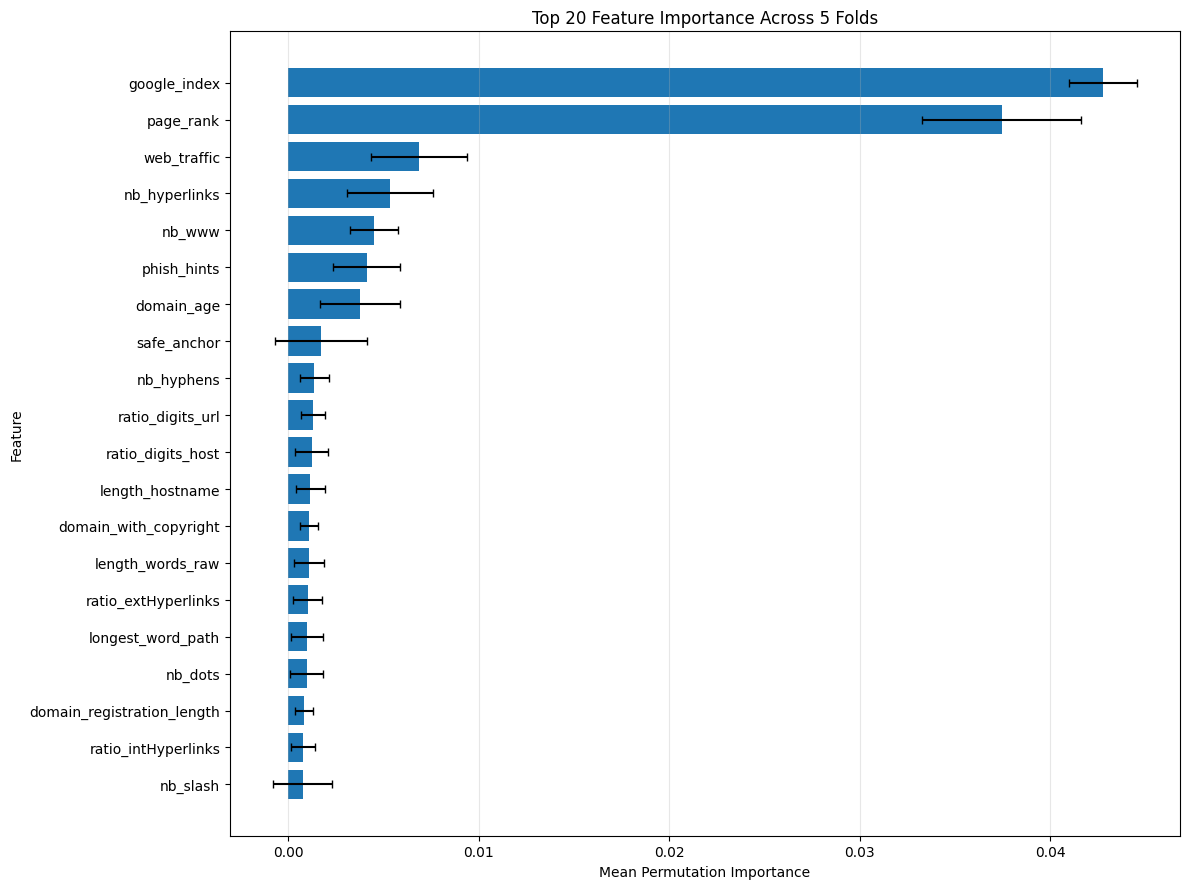

In [45]:
import matplotlib.pyplot as plt

# 상위 20개 특성 추출
top20 = importance_summary.head(20).sort_values(
    'mean_importance',
    ascending=True
)

plt.figure(figsize=(12, 9))

plt.barh(
    top20.index,
    top20['mean_importance'],
    xerr=top20['std_importance'],
    capsize=3
)

plt.xlabel('Mean Permutation Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importance Across 5 Folds')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

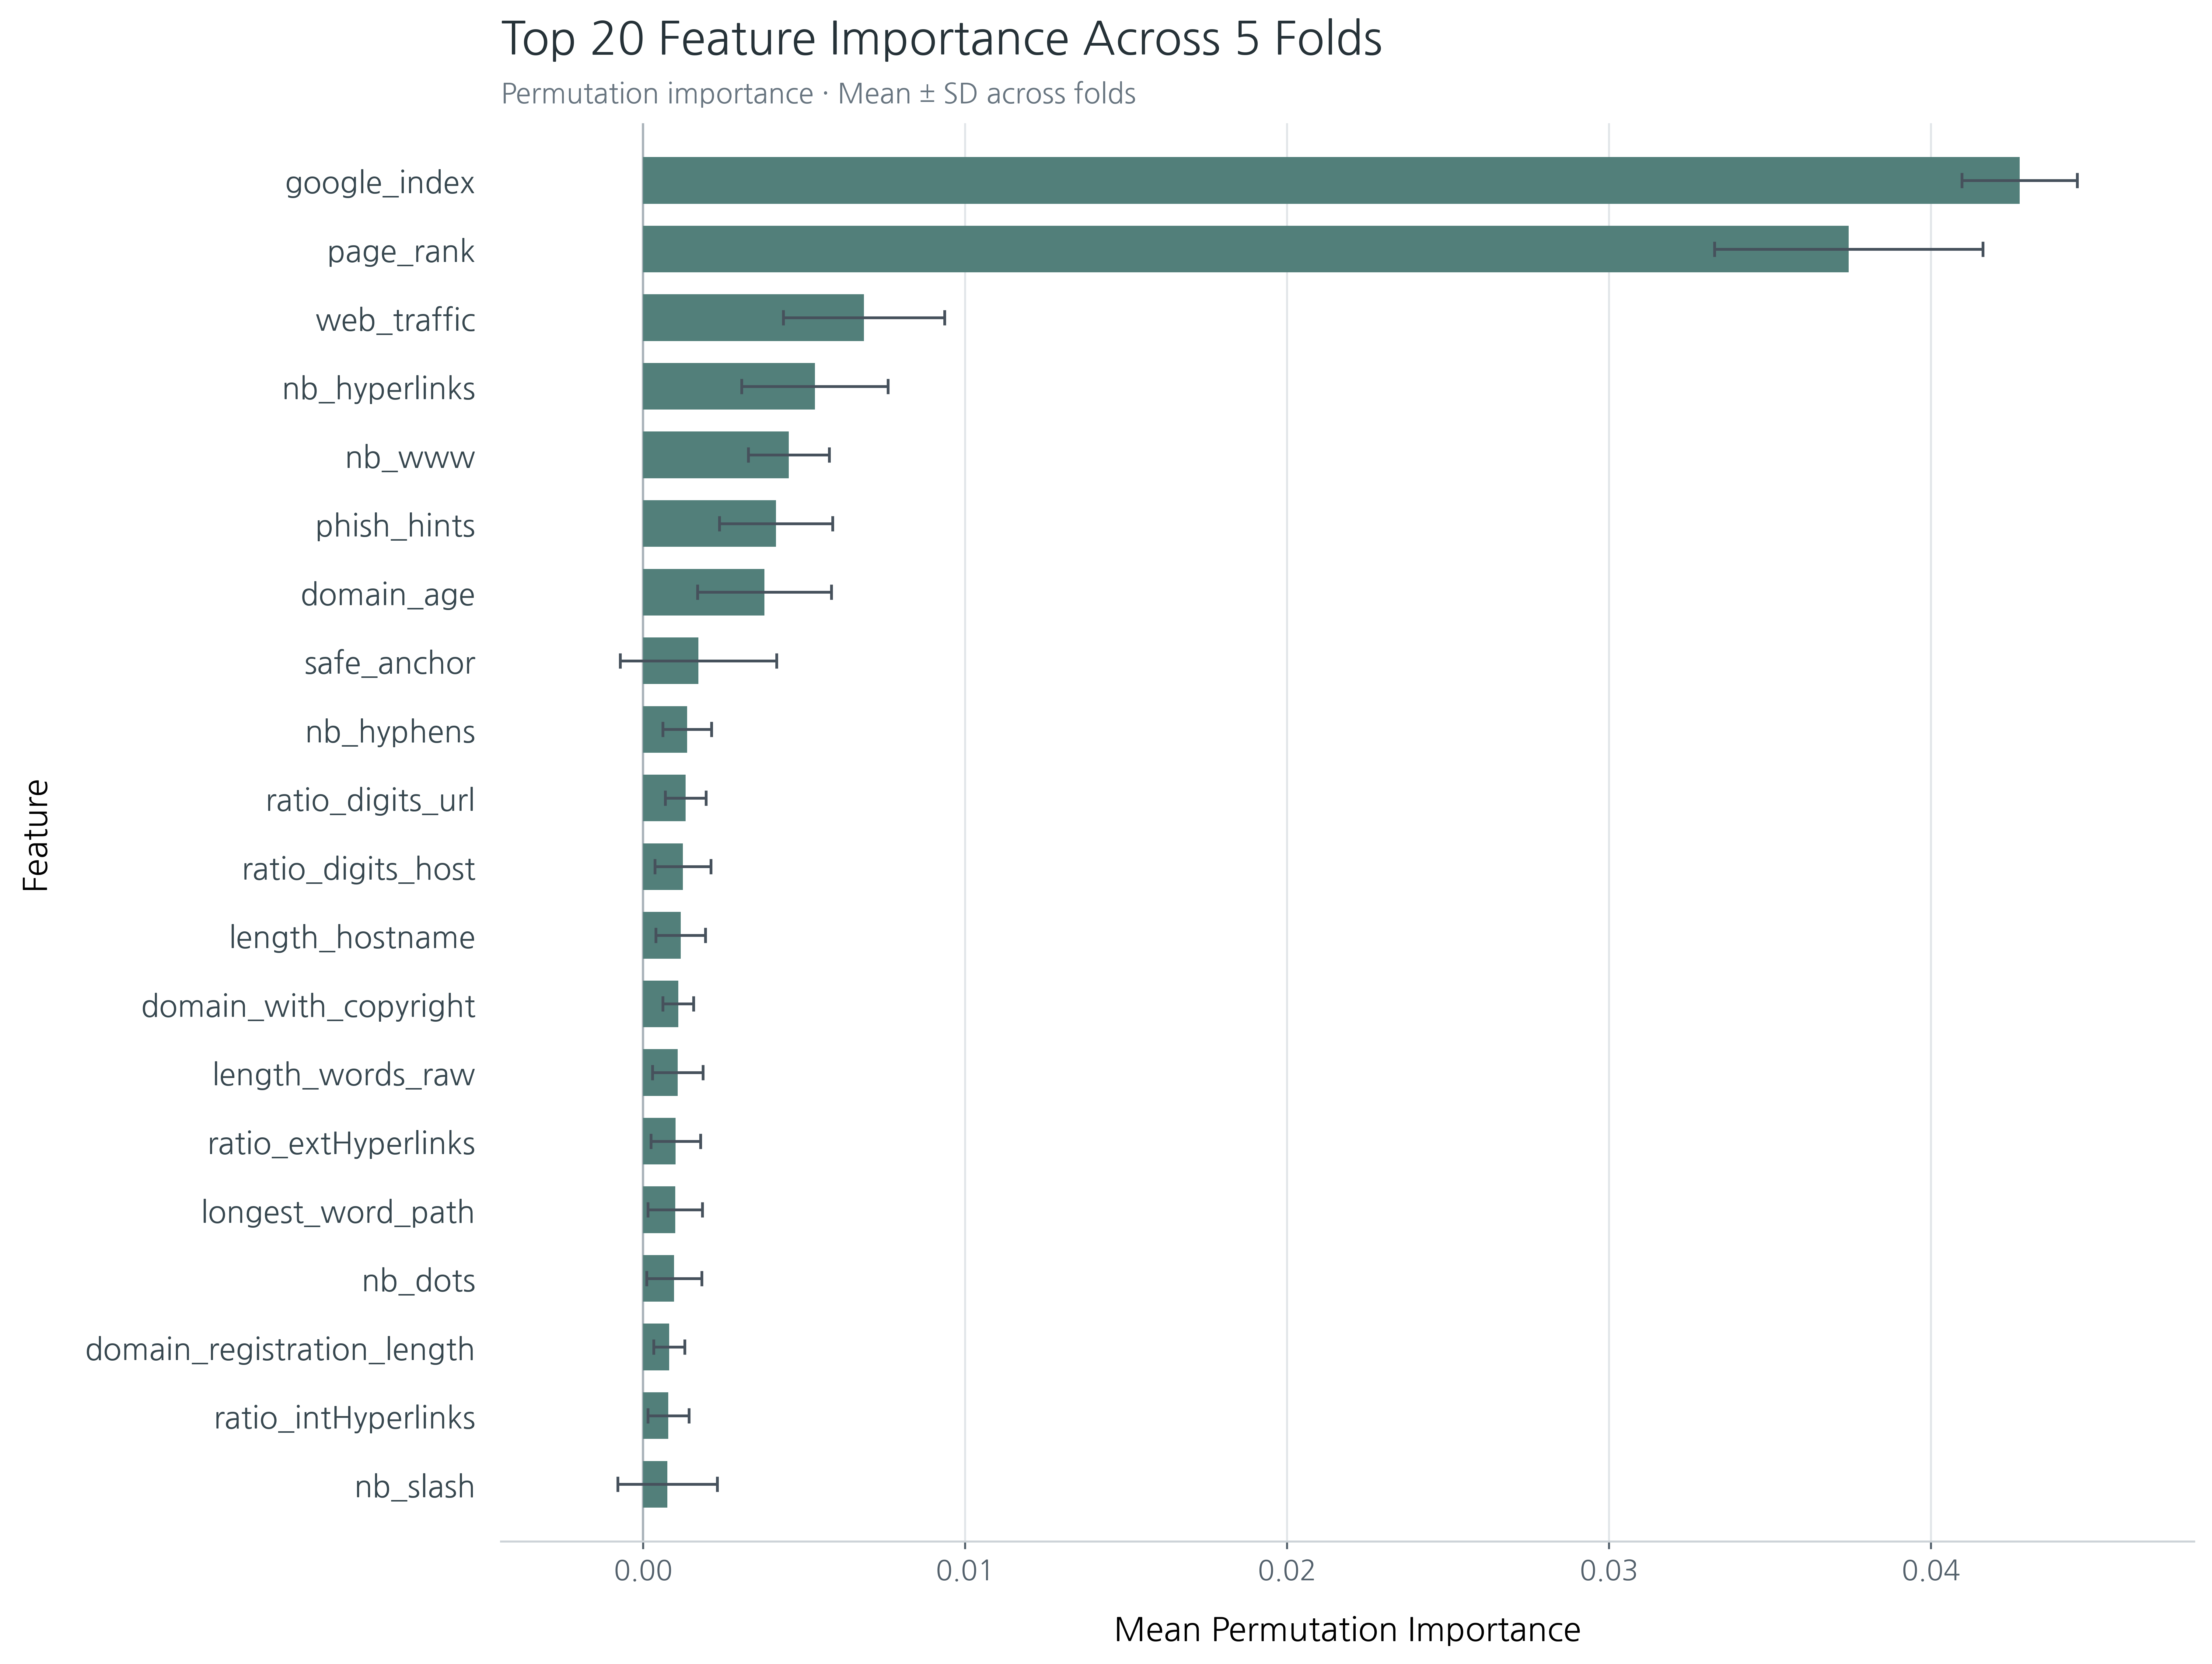

In [63]:
#개선본
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# 중요도가 높은 상위 20개 선택 → 가로 막대그래프용 정렬
top20 = (
    importance_summary
    .nlargest(20, 'mean_importance')
    .sort_values('mean_importance', ascending=True)
)

# 이 그래프에만 스타일 적용
with plt.rc_context({
    'font.size': 12,
    'axes.titlesize': 18,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 12,
    'figure.dpi': 600,
    'savefig.dpi': 600,
    'axes.unicode_minus': False,
}):
    fig, ax = plt.subplots(figsize=(12, 9), layout='constrained')
    fig.set_facecolor('white')
    ax.set_facecolor('white')

    ax.barh(
        top20.index,
        top20['mean_importance'],
        xerr=top20['std_importance'],
        height=0.68,
        color='#527F7A',         # 차분한 청록색
        edgecolor='none',
        error_kw={
            'ecolor': '#46515C', # 짙은 회색 오차 막대
            'elinewidth': 1.1,
            'capsize': 3,
            'capthick': 1.1,
        },
        zorder=3,
    )

    ax.set_title(
        'Top 20 Feature Importance Across 5 Folds',
        loc='left',
        fontweight='bold',
        color='#263238',
        pad=28,
    )
    ax.text(
        0, 1.015,
        'Permutation importance · Mean ± SD across folds',
        transform=ax.transAxes,
        fontsize=11,
        color='#687580',
    )

    ax.set_xlabel('Mean Permutation Importance', labelpad=12)
    ax.set_ylabel('Feature', labelpad=14)

    # 가로축 눈금과 격자를 간결하게 표시
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.set_axisbelow(True)
    ax.grid(axis='x', color='#E2E6E9', linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.axvline(0, color='#AAB3BA', linewidth=0.9, zorder=2)

    # 불필요한 테두리와 눈금선 제거
    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)
    ax.spines['bottom'].set_color('#CDD3D8')

    ax.tick_params(axis='y', length=0, pad=10, colors='#37474F')
    ax.tick_params(axis='x', length=3, colors='#54616C')
    ax.margins(x=0.08, y=0.025)

    # show() 전에 저장
    fig.savefig(
        'top20_feature_importance.png',
        dpi=600,
        bbox_inches='tight',
        facecolor='white',
    )
    plt.show()

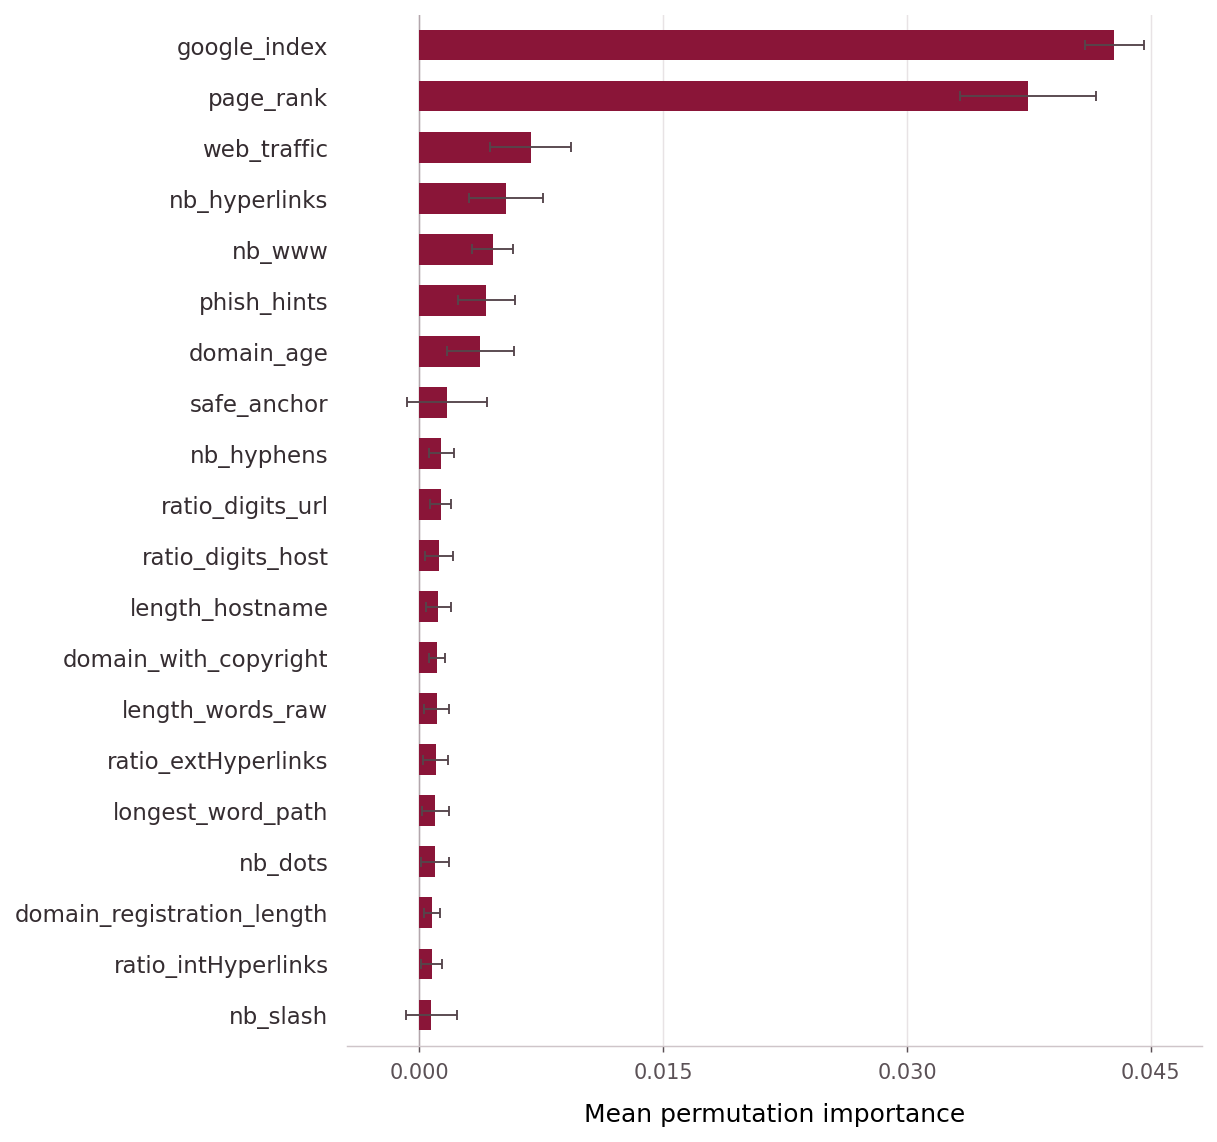

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# 중요도 상위 20개: 높은 특성이 위에 표시되도록 정렬
top20 = (
    importance_summary
    .nlargest(20, 'mean_importance')
    .sort_values('mean_importance', ascending=False)
)

BURGUNDY = '#8A1538'  # 덕성 버건디 계열
y = np.arange(len(top20))

with plt.rc_context({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 11,
    'axes.unicode_minus': False,
    'figure.dpi': 150,       # 화면 표시용
    'savefig.dpi': 600,      # 파일 저장용
    'pdf.fonttype': 42,
}):
    # 충분한 세로 공간으로 특성명 사이 간격 확보
    fig, ax = plt.subplots(figsize=(8, 7.5), layout='constrained')
    fig.set_facecolor('white')
    ax.set_facecolor('white')

    ax.barh(
        y,
        top20['mean_importance'].to_numpy(),
        xerr=top20['std_importance'].to_numpy(),
        height=0.60,
        color=BURGUNDY,
        edgecolor='none',
        error_kw={
            'ecolor': '#55454B',
            'elinewidth': 0.9,
            'capsize': 2.5,
            'capthick': 0.9,
        },
        zorder=3,
    )

    ax.set_yticks(y)
    ax.set_yticklabels(top20.index.astype(str))
    ax.invert_yaxis()

    ax.set_xlabel('Mean permutation importance', labelpad=10)
    ax.set_ylabel('')

    # 작은 크기로 삽입할 때 공간을 확보하도록 제목은 생략
    # 그림 설명 예: Top 20 features by permutation importance (mean ± SD).

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set_axisbelow(True)
    ax.grid(axis='x', color='#E8E3E5', linewidth=0.7)
    ax.grid(axis='y', visible=False)
    ax.axvline(0, color='#B3A6AC', linewidth=0.7, zorder=2)

    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)

    ax.spines['bottom'].set_color('#CFC5C9')
    ax.spines['bottom'].set_linewidth(0.7)

    ax.tick_params(axis='y', length=0, pad=9, colors='#352D31')
    ax.tick_params(
        axis='x',
        length=3,
        width=0.7,
        pad=5,
        colors='#5B5156',
    )

    ax.set_ylim(len(top20) - 0.4, -0.6)
    ax.margins(x=0.08)

    fig.savefig(
        'top20_feature_importance_burgundy.png',
        dpi=600,
        facecolor='white',
    )
    fig.savefig(
        'top20_feature_importance_burgundy.pdf',
        facecolor='white',
    )

    plt.show()

그래프의 막대는 5개 Fold의 평균 중요도, 가로 오차 막대는 Fold 간 표준편차임.

### 06-1. Fold별 F1과 성능 지표 비교

다음 그래프들은 81·20·10·5개 특성 모델을 시각적으로 비교하기 위한 코드입니다. 앞서 만든 교차검증 결과표의 변수들을 활용합니다.

F1 점수 비교 그래프

Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


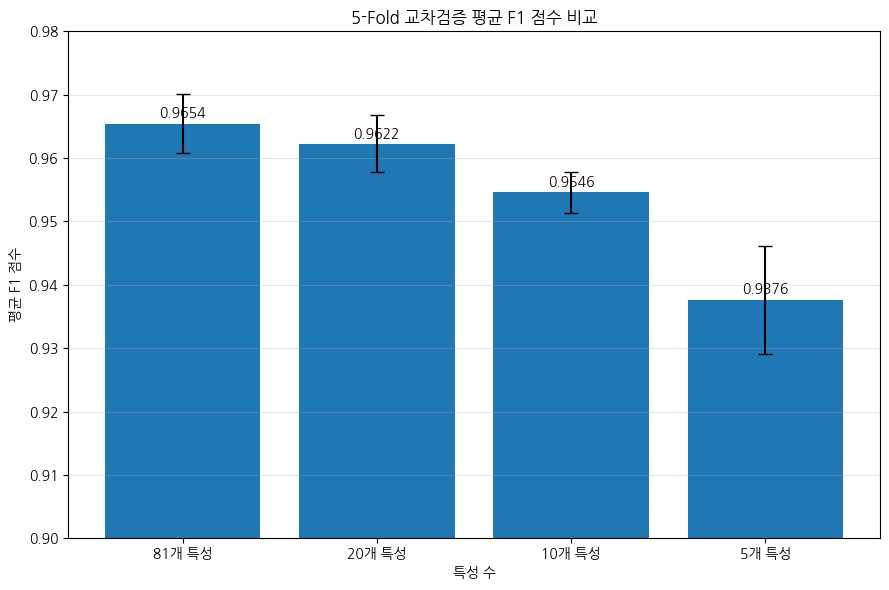

In [46]:

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# 한글 폰트 설치
!apt-get -qq install -y fonts-nanum

# 폰트 설정
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = 'NanumGothic'
else:
    print('나눔고딕 폰트를 찾을 수 없습니다.')

plt.rcParams['axes.unicode_minus'] = False

order = ['81개 특성', '20개 특성', '10개 특성', '5개 특성']

f1_mean = mean_results.loc[order, 'F1']
f1_std = std_results.loc[order, 'F1']

plt.figure(figsize=(9, 6))

plt.bar(
    order,
    f1_mean,
    yerr=f1_std,
    capsize=5
)

plt.xlabel('특성 수')
plt.ylabel('평균 F1 점수')
plt.title('5-Fold 교차검증 평균 F1 점수 비교')
plt.ylim(0.90, 0.98)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(f1_mean):
    plt.text(i, value + 0.001, f'{value:.4f}', ha='center')

plt.tight_layout()
plt.show()


In [47]:
print(f1_mean)
print(f1_std)

모델
81개 특성    0.965439
20개 특성    0.962227
10개 특성    0.954602
5개 특성     0.937649
Name: F1, dtype: float64
모델
81개 특성    0.004596
20개 특성    0.004497
10개 특성    0.003242
5개 특성     0.008529
Name: F1, dtype: float64


4가지 성능 지표 비교

In [48]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']

# 평균 성능
print("5-Fold 평균 성능")
display(mean_results.loc[order, metrics].round(4))

# 성능 표준편차
print("5-Fold 성능 표준편차")
display(std_results.loc[order, metrics].round(4))

5-Fold 평균 성능


,Accuracy,Precision,Recall,F1
모델,,,,
81개 특성,0.9654,0.9653,0.9657,0.9654
20개 특성,0.9622,0.9604,0.9641,0.9622
10개 특성,0.9545,0.9523,0.9569,0.9546
5개 특성,0.9374,0.9340,0.9414,0.9376


5-Fold 성능 표준편차


,Accuracy,Precision,Recall,F1
모델,,,,
81개 특성,0.0046,0.0059,0.0074,0.0046
20개 특성,0.0045,0.0058,0.0062,0.0045
10개 특성,0.0032,0.0027,0.0049,0.0032
5개 특성,0.0083,0.0065,0.0137,0.0085


4가지 성능 지표 시각화

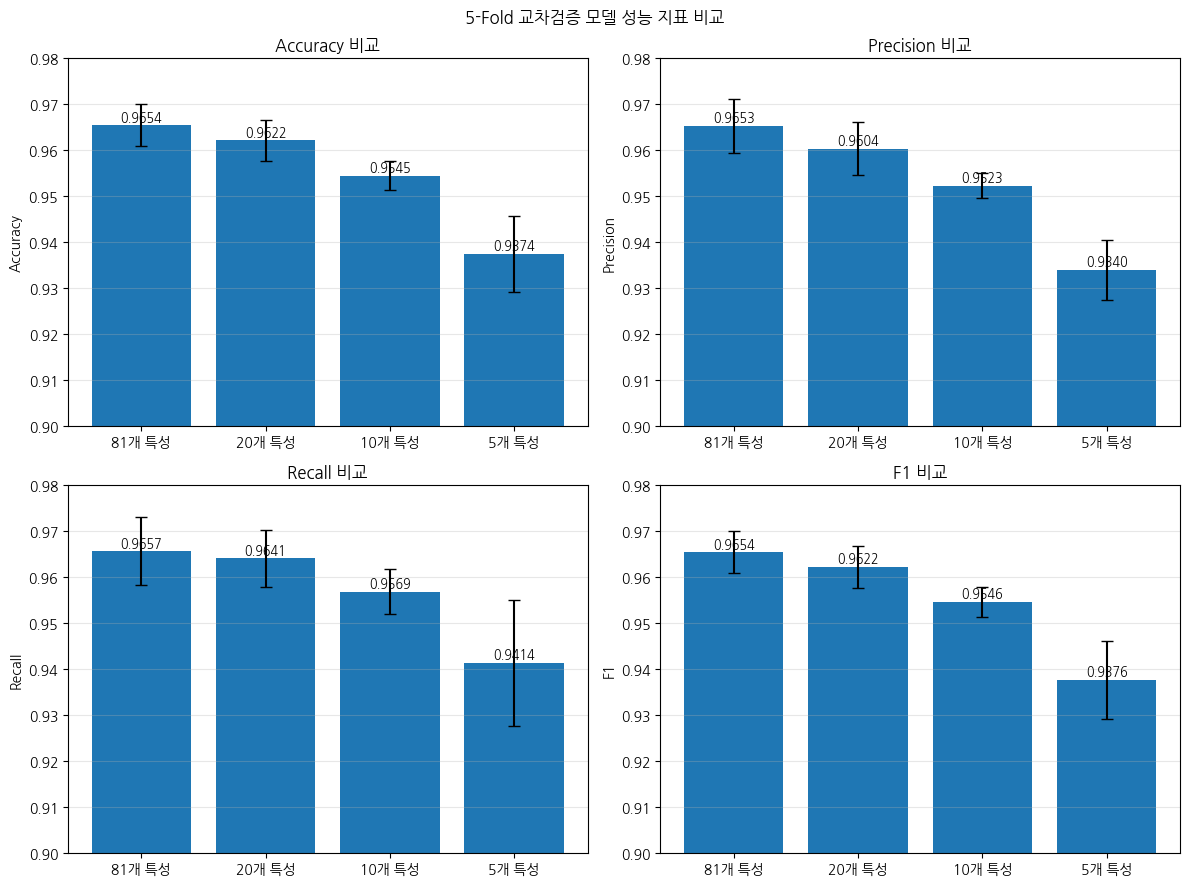

In [49]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 설정 강제 재지정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
order = ['81개 특성', '20개 특성', '10개 특성', '5개 특성']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, metric in zip(axes.flat, metrics):

    values = mean_results.loc[order, metric]
    errors = std_results.loc[order, metric]

    bars = ax.bar(
        order,
        values,
        yerr=errors,
        capsize=4
    )

    ax.set_title(f'{metric} 비교')
    ax.set_ylabel(metric)
    ax.set_ylim(0.90, 0.98)
    ax.grid(axis='y', alpha=0.3)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.001,
            f'{value:.4f}',
            ha='center',
            fontsize=9
        )

plt.suptitle('5-Fold 교차검증 모델 성능 지표 비교')
plt.tight_layout()
plt.show()

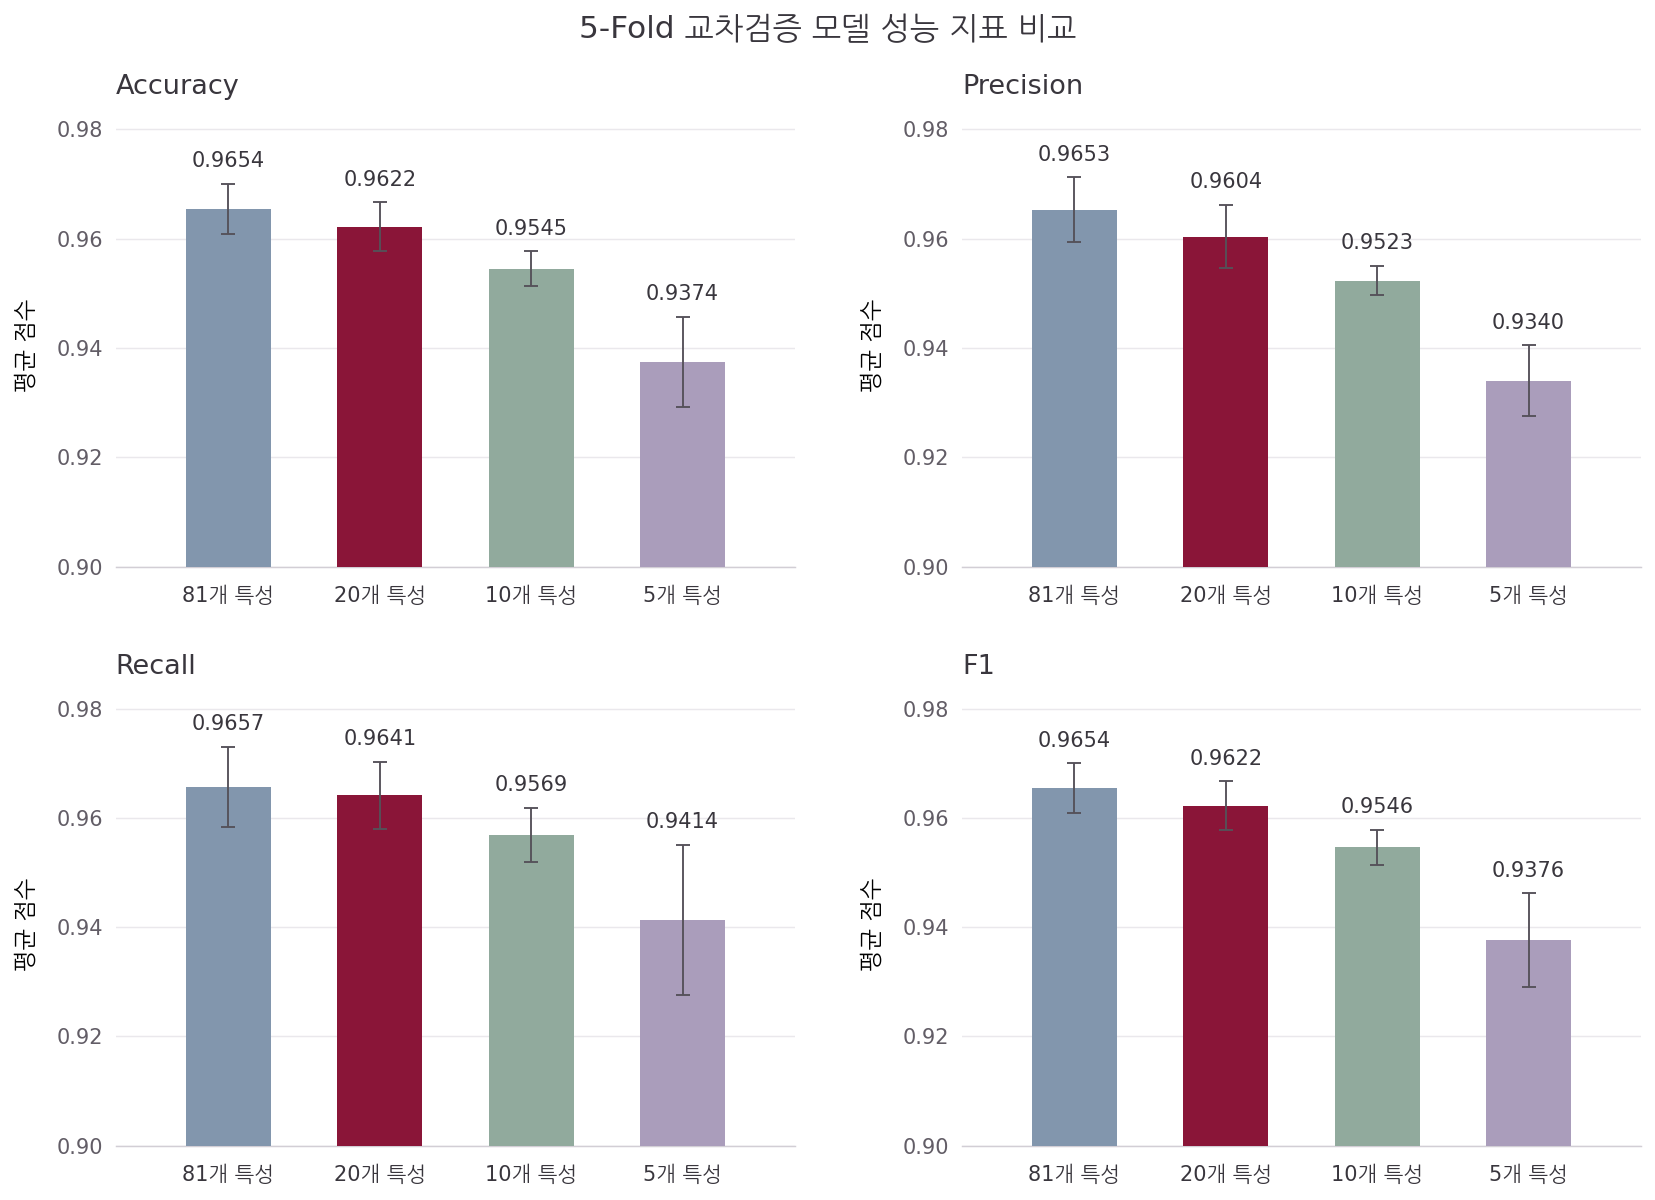

In [69]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# Colab에서 한글 폰트 설치
!apt-get -qq install -y fonts-nanum

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
else:
    raise FileNotFoundError('나눔고딕 폰트를 찾을 수 없습니다.')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
order = ['81개 특성', '20개 특성', '10개 특성', '5개 특성']
x = np.arange(len(order))

# 앞 그래프와 동일한 색상
colors = [
    '#8296AD',  # 81개: 블루그레이
    '#8A1538',  # 20개: 버건디
    '#91AA9D',  # 10개: 세이지
    '#AA9DBB',  # 5개: 라벤더
]

# 네 패널의 y축 범위를 동일하게 설정
all_upper = (
    mean_results.loc[order, metrics]
    + std_results.loc[order, metrics]
).to_numpy(dtype=float)

y_upper = max(0.98, float(np.max(all_upper)) + 0.008)

with plt.rc_context({
    'font.family': ['DejaVu Sans', 'NanumGothic'],
    'font.size': 11,
    'font.weight': 'normal',
    'axes.titlesize': 13,
    'axes.titleweight': 'normal',
    'axes.labelsize': 11,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.unicode_minus': False,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
}):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 8),
        layout='constrained',
    )
    fig.set_facecolor('white')

    # 패널 사이 간격 확보
    fig.get_layout_engine().set(
        w_pad=0.08,
        h_pad=0.10,
        wspace=0.08,
        hspace=0.08,
    )

    for ax, metric in zip(axes.flat, metrics):
        values = mean_results.loc[order, metric].to_numpy(dtype=float)
        errors = std_results.loc[order, metric].to_numpy(dtype=float)

        ax.set_facecolor('white')

        ax.bar(
            x,
            values,
            yerr=errors,
            width=0.56,
            color=colors,
            edgecolor='none',
            error_kw={
                'ecolor': '#555159',
                'elinewidth': 0.9,
                'capsize': 3.5,
                'capthick': 0.9,
            },
            zorder=3,
        )

        ax.set_title(
            metric,
            loc='left',
            pad=14,
            color='#39363D',
        )
        ax.set_xticks(x)
        ax.set_xticklabels(order)
        ax.set_ylabel('평균 점수', labelpad=9)

        ax.set_ylim(0.90, y_upper)
        ax.yaxis.set_major_locator(MultipleLocator(0.02))
        ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

        # 오차 막대 위에 평균값 표시
        for i, (value, error) in enumerate(zip(values, errors)):
            ax.annotate(
                f'{value:.4f}',
                xy=(i, value + error),
                xytext=(0, 6),
                textcoords='offset points',
                ha='center',
                va='bottom',
                fontsize=10,
                fontweight='normal',
                color='#39363D',
            )

        ax.set_axisbelow(True)
        ax.grid(axis='y', color='#EAE8EC', linewidth=0.7)
        ax.grid(axis='x', visible=False)

        for spine in ['top', 'right', 'left']:
            ax.spines[spine].set_visible(False)

        ax.spines['bottom'].set_color('#D2CED5')
        ax.spines['bottom'].set_linewidth(0.7)

        ax.tick_params(
            axis='x',
            length=0,
            pad=9,
            colors='#39363D',
        )
        ax.tick_params(
            axis='y',
            length=0,
            pad=6,
            colors='#625D66',
        )
        ax.margins(x=0.13)

    fig.suptitle(
        '5-Fold 교차검증 모델 성능 지표 비교',
        fontsize=15,
        fontweight='normal',
        color='#39363D',
    )

    fig.savefig(
        'model_performance_comparison.png',
        dpi=600,
        facecolor='white',
    )

    plt.show()

<a id="step-07"></a>
## 07. 최종 특성 선정과 테스트 데이터 평가

**이 단계의 질문:** 교차검증으로 확인한 특성들을 사용해 최종 모델을 다시 학습하면, 테스트 데이터에서는 어떤 결과가 나올까?

평균 중요도 기반 특성 목록을 만든 후, 최종 모델 4개를 학습하고 학습·검증에 사용하지 않았던 테스트 데이터에서 성능을 측정합니다.

In [50]:
# 평균 중요도 기준 최종 특성 목록
final_features_20 = importance_summary.head(20).index.tolist()
final_features_10 = importance_summary.head(10).index.tolist()
final_features_5 = importance_summary.head(5).index.tolist()

print("최종 20개 특성")
print(final_features_20)

print("\n최종 10개 특성")
print(final_features_10)

print("\n최종 5개 특성")
print(final_features_5)

최종 20개 특성
['google_index', 'page_rank', 'web_traffic', 'nb_hyperlinks', 'nb_www', 'phish_hints', 'domain_age', 'safe_anchor', 'nb_hyphens', 'ratio_digits_url', 'ratio_digits_host', 'length_hostname', 'domain_with_copyright', 'length_words_raw', 'ratio_extHyperlinks', 'longest_word_path', 'nb_dots', 'domain_registration_length', 'ratio_intHyperlinks', 'nb_slash']

최종 10개 특성
['google_index', 'page_rank', 'web_traffic', 'nb_hyperlinks', 'nb_www', 'phish_hints', 'domain_age', 'safe_anchor', 'nb_hyphens', 'ratio_digits_url']

최종 5개 특성
['google_index', 'page_rank', 'web_traffic', 'nb_hyperlinks', 'nb_www']


최종 모델 학습

In [51]:
# 최종 모델 생성
final_models = {
    '81개 특성': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    '20개 특성': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    '10개 특성': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    '5개 특성': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

# 모델별 사용할 특성 지정
feature_sets = {
    '81개 특성': X_dev.columns.tolist(),
    '20개 특성': final_features_20,
    '10개 특성': final_features_10,
    '5개 특성': final_features_5
}

# 개발 데이터 전체로 모델 학습
for name, model in final_models.items():

    selected_features = feature_sets[name]

    model.fit(
        X_dev[selected_features],
        y_dev
    )

    print(f"{name} 모델 학습 완료")

81개 특성 모델 학습 완료
20개 특성 모델 학습 완료
10개 특성 모델 학습 완료
5개 특성 모델 학습 완료


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

final_results = []
final_predictions = {}

for name, model in final_models.items():

    selected_features = feature_sets[name]

    # 테스트 데이터 예측
    y_pred = model.predict(
        X_test[selected_features]
    )

    final_predictions[name] = y_pred

    # 성능 평가
    final_results.append({
        '모델': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred)
    })

# 결과표 생성
final_results_df = pd.DataFrame(final_results)

print("최종 테스트 성능")
display(final_results_df.round(4))

최종 테스트 성능


,모델,Accuracy,Precision,Recall,F1
0,81개 특성,0.9637,0.9641,0.9633,0.9637
1,20개 특성,0.9624,0.9640,0.9606,0.9623
2,10개 특성,0.9584,0.9572,0.9598,0.9585
3,5개 특성,0.9405,0.9359,0.9458,0.9408


<a id="step-08"></a>
## 08. 혼동행렬과 미탐·오탐 사례 분석

**이 단계의 질문:** F1 점수가 비슷하더라도, 실제로 어떤 피싱 사이트를 새로 놓치거나 잡아내게 될까?

혼동행렬을 통해 **TP(정탐), TN(정상 판별), FP(오탐), FN(미탐)**의 차이를 확인합니다. 특히 FN은 실제 피싱을 놓친 경우이므로 개별 사례 확인이 중요합니다.

### 다음 단계: 혼동행렬 분석

예측 변화의 시각적 분석을 위한 4개 모델의 혼동행렬 시각화

이 그래프를 통해 특성을 줄였을 때 피싱을 놓치는 사례와 정상 사이트를 오탐하는 사례가 얼마나 달라졌는지 비교할 수 있음.

FN이 중요 : 피싱 사이트를 놓치는 경우이기 때문

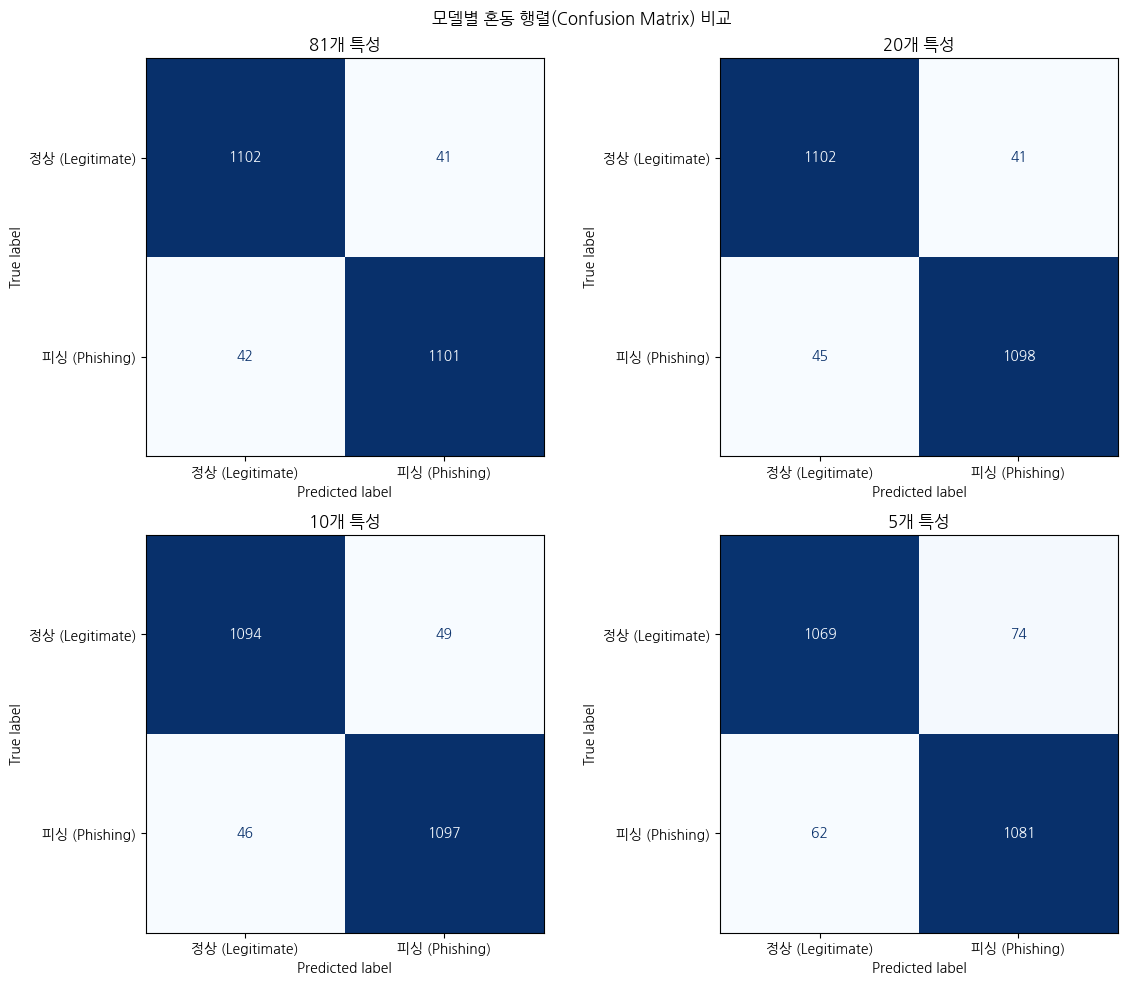

In [53]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 폰트 설정 강제 재지정
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.flat,
    final_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=['정상 (Legitimate)', '피싱 (Phishing)'],
        cmap='Blues',
        values_format='d',
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle('모델별 혼동 행렬(Confusion Matrix) 비교')
plt.tight_layout()
plt.show()

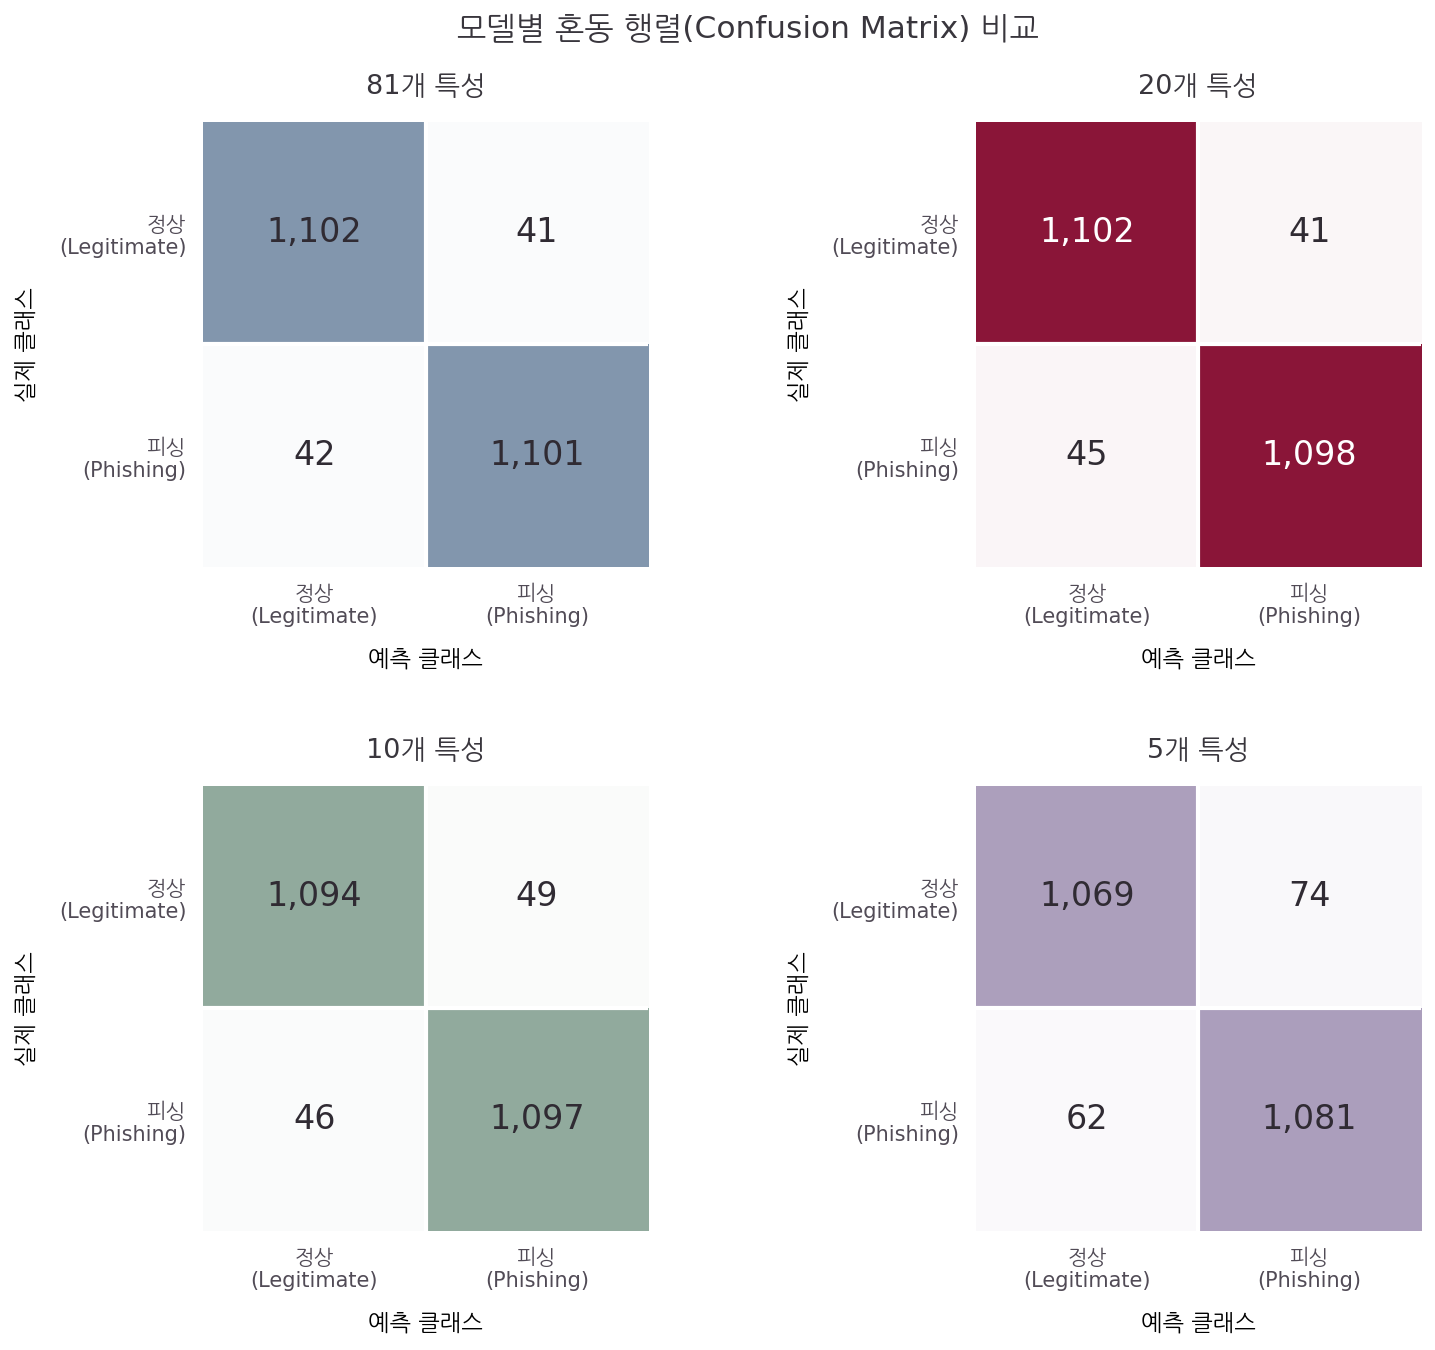

In [70]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.colors import LinearSegmentedColormap, Normalize
from sklearn.metrics import confusion_matrix

# Colab에서 한글 폰트 설치
!apt-get -qq install -y fonts-nanum

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
else:
    raise FileNotFoundError('나눔고딕 폰트를 찾을 수 없습니다.')

order = ['81개 특성', '20개 특성', '10개 특성', '5개 특성']

# 앞 그래프와 동일한 색상
colors = {
    '81개 특성': '#8296AD',  # 블루그레이
    '20개 특성': '#8A1538',  # 버건디
    '10개 특성': '#91AA9D',  # 세이지
    '5개 특성': '#AA9DBB',   # 라벤더
}

# final_predictions의 키가 order와 동일해야 합니다.
# 클래스가 0=정상, 1=피싱인 경우
class_labels = [0, 1]
display_labels = ['정상\n(Legitimate)', '피싱\n(Phishing)']

matrices = {
    name: confusion_matrix(
        y_test,
        final_predictions[name],
        labels=class_labels,
    )
    for name in order
}

# 모든 패널에서 같은 건수는 같은 상대적 농도로 표시
vmax = max(int(cm.max()) for cm in matrices.values())
norm = Normalize(vmin=0, vmax=max(vmax, 1))

with plt.rc_context({
    'font.family': ['DejaVu Sans', 'NanumGothic'],
    'font.size': 11,
    'font.weight': 'normal',
    'axes.titlesize': 13,
    'axes.titleweight': 'normal',
    'axes.labelsize': 11,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.unicode_minus': False,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
}):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(10, 9),
        layout='constrained',
    )
    fig.set_facecolor('white')

    fig.get_layout_engine().set(
        w_pad=0.10,
        h_pad=0.10,
        wspace=0.10,
        hspace=0.10,
    )

    for ax, name in zip(axes.flat, order):
        cm = matrices[name]

        # 흰색 → 각 특성에 지정한 색상
        cmap = LinearSegmentedColormap.from_list(
            f'cmap_{name}',
            ['#FFFFFF', colors[name]],
        )

        ax.imshow(
            cm,
            cmap=cmap,
            norm=norm,
            interpolation='nearest',
            aspect='equal',
        )

        # 배경 밝기에 따라 숫자 색상을 선택
        for row in range(cm.shape[0]):
            for col in range(cm.shape[1]):
                r, g, b, _ = cmap(norm(cm[row, col]))
                luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b

                ax.text(
                    col,
                    row,
                    f'{cm[row, col]:,}',
                    ha='center',
                    va='center',
                    fontsize=16,
                    fontweight='normal',
                    color='white' if luminance < 0.5 else '#302B33',
                )

        ax.set_title(name, pad=13, color='#39363D')
        ax.set_xlabel('예측 클래스', labelpad=10)
        ax.set_ylabel('실제 클래스', labelpad=10)

        ax.set_xticks([0, 1], labels=display_labels)
        ax.set_yticks([0, 1], labels=display_labels)

        ax.tick_params(
            axis='both',
            which='both',
            length=0,
            pad=8,
            colors='#514B56',
        )

        # 셀 사이에 얇은 흰색 구분선
        ax.set_xticks([0.5], minor=True)
        ax.set_yticks([0.5], minor=True)
        ax.grid(which='minor', color='white', linewidth=2)
        ax.grid(which='major', visible=False)

        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.suptitle(
        '모델별 혼동 행렬(Confusion Matrix) 비교',
        fontsize=15,
        fontweight='normal',
        color='#39363D',
    )

    fig.savefig(
        'confusion_matrix_comparison.png',
        dpi=600,
        facecolor='white',
    )

    plt.show()

### 08-1. 원본 URL과 모델 예측 연결

테스트 표본을 원본 URL과 연결해, **같은 사이트를 4개 모델이 각각 어떻게 분류했는지** 확인할 수 있는 표를 만듭니다. 이 코드와 출력은 원본 그대로입니다.

## 1. URL·실제 라벨·모델 예측 결과 연결

In [54]:
# =============================================================
# 1. 테스트 샘플의 원본 URL과 4개 모델의 예측 결과 연결
# 실행 위치: 기존 노트북 마지막 혼동행렬 코드 바로 아래
# 이미 생성된 변수: df_clean, X_test, y_test,
#                  final_predictions, final_results_df, mean_results
# =============================================================
from pathlib import Path
from urllib.parse import urlsplit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import font_manager
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix
from IPython.display import display

# macOS/Windows/Linux에서 한글 그래프 글꼴이 있으면 자동 적용
for korean_font in ['AppleGothic', 'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if korean_font in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family'] = korean_font
        break
plt.rcParams['axes.unicode_minus'] = False

SAVE_DIR = Path('phishing_analysis_results')
SAVE_DIR.mkdir(exist_ok=True)

model_columns = {
    '81개 특성': 'pred_81',
    '20개 특성': 'pred_20',
    '10개 특성': 'pred_10',
    '5개 특성': 'pred_5'
}

# df_clean에서 중복 URL 제거 후 원본 인덱스를 유지했으므로
# X_test.index로 URL을 정확히 찾아올 수 있음.
assert X_test.index.is_unique, '테스트 인덱스에 중복이 있습니다.'
assert df_clean.index.is_unique, 'df_clean 인덱스에 중복이 있습니다.'
assert X_test.index.isin(df_clean.index).all(), '테스트 인덱스가 원본 데이터와 맞지 않습니다.'
assert X_test.index.equals(y_test.index), 'X_test와 y_test의 행 순서가 다릅니다.'

site_predictions = pd.DataFrame(index=X_test.index)
site_predictions.index.name = 'original_index'
site_predictions['url'] = df_clean.loc[X_test.index, 'url'].to_numpy()
site_predictions['actual'] = y_test.to_numpy().astype(int)
site_predictions['actual_label'] = site_predictions['actual'].map({0: 'legitimate', 1: 'phishing'})

def get_domain(url):
    """URL에서 도메인만 추출. 프로토콜이 없는 URL도 처리."""
    if pd.isna(url) or not str(url).strip():
        return None
    s = str(url).strip()
    if '://' not in s:
        s = 'http://' + s
    try:
        return urlsplit(s).hostname
    except ValueError:
        return None

site_predictions['domain'] = site_predictions['url'].map(get_domain)

for model_name, pred_col in model_columns.items():
    pred = np.asarray(final_predictions[model_name]).ravel()
    assert len(pred) == len(site_predictions), f'{model_name}: 예측 길이 불일치'
    assert np.isin(pred, [0, 1]).all(), f'{model_name}: 예상 외 예측값 존재'
    site_predictions[pred_col] = pred.astype(int)
    site_predictions[f'FN_{pred_col}'] = (
        site_predictions['actual'].eq(1) & site_predictions[pred_col].eq(0)
    )

prediction_cols = list(model_columns.values())
site_predictions['predictions_differ'] = (
    site_predictions[prediction_cols].nunique(axis=1) > 1
)

print('테스트 URL 수:', len(site_predictions))
print('실제 피싱 URL 수:', site_predictions['actual'].eq(1).sum())
print('네 모델 중 예측이 하나라도 다른 URL 수:', site_predictions['predictions_differ'].sum())
display(site_predictions[['url', 'domain', 'actual_label'] + prediction_cols].head(10))
site_predictions.to_csv(SAVE_DIR / 'all_test_url_predictions.csv', encoding='utf-8-sig')

테스트 URL 수: 2286
실제 피싱 URL 수: 1143
네 모델 중 예측이 하나라도 다른 URL 수: 117


,url,domain,actual_label,pred_81,pred_20,pred_10,pred_5
original_index,,,,,,,
4509,https://storage.cloud.google.com/user7773578ix...,storage.cloud.google.com,phishing,1,1,1,1
8622,http://www.silvergames.com/en/traffic-collision-2,www.silvergames.com,legitimate,0,0,0,0
8245,https://www.resilienz.at/,www.resilienz.at,legitimate,0,0,0,0
7823,http://signipartialregs.ebay.de.voilaparisinte...,signipartialregs.ebay.de.voilaparisinterior.com,phishing,1,1,1,1
6592,http://shadetreetechnology.com/V4/validation/2...,shadetreetechnology.com,phishing,1,1,1,1
5575,http://www.tutorialspoint.com/dbms/,www.tutorialspoint.com,legitimate,0,0,0,0
8972,http://www.erb.org.zm/downloads/webadmin/made-...,www.erb.org.zm,phishing,1,1,1,0
7938,https://ru-ru.facebook.com/HelpCompany/timeline,ru-ru.facebook.com,legitimate,0,0,0,0
7840,https://groups.google.com/d/forum/node-red,groups.google.com,legitimate,0,0,0,0


## 2. 미탐(FN) 및 URL별 예측 변화 사례 추출

In [55]:
# =============================================================
# 2. 모델별 미탐(FN) URL 추출 + 81개 기준 예측 변화 사례 추출
# =============================================================
fn_tables = []

for model_name, pred_col in model_columns.items():
    missed = site_predictions.loc[
        site_predictions['FN_' + pred_col],
        ['url', 'domain', 'actual_label', pred_col]
    ].copy()
    missed.insert(0, 'model', model_name)
    missed.rename(columns={pred_col: 'prediction'}, inplace=True)
    fn_tables.append(missed)
    print(f'{model_name}: 미탐(FN) {len(missed)}건')

fn_cases_df = pd.concat(fn_tables, axis=0)
fn_cases_df.index.name = 'original_index'
fn_cases_df.to_csv(SAVE_DIR / 'false_negative_urls.csv', encoding='utf-8-sig')
print('\n미탐 URL 예시 (모델별 전체 목록은 CSV에 저장)')
display(fn_cases_df.head(30))

change_tables = []
base_pred = site_predictions['pred_81']

for model_name, pred_col in list(model_columns.items())[1:]:
    changed = site_predictions.loc[
        base_pred.ne(site_predictions[pred_col]),
        ['url', 'domain', 'actual_label', 'actual'] + prediction_cols
    ].copy()
    changed.insert(0, 'compared_model', model_name)

    # 변화 유형은 81개 특성 모델을 기준으로 판단
    changed['change_type'] = np.select(
        [
            (changed['actual'] == 1) & (changed['pred_81'] == 1) & (changed[pred_col] == 0),
            (changed['actual'] == 1) & (changed['pred_81'] == 0) & (changed[pred_col] == 1),
            (changed['actual'] == 0) & (changed['pred_81'] == 0) & (changed[pred_col] == 1),
            (changed['actual'] == 0) & (changed['pred_81'] == 1) & (changed[pred_col] == 0)
        ],
        ['새로운 미탐 발생', '기존 미탐 해소', '새로운 오탐 발생', '기존 오탐 해소'],
        default='기타'
    )
    change_tables.append(changed)

prediction_changes_df = pd.concat(change_tables, axis=0)
prediction_changes_df.index.name = 'original_index'
priority = {'새로운 미탐 발생': 0, '기존 미탐 해소': 1,
            '새로운 오탐 발생': 2, '기존 오탐 해소': 3}
prediction_changes_df['priority'] = prediction_changes_df['change_type'].map(priority)
prediction_changes_df = prediction_changes_df.sort_values(
    ['priority', 'compared_model', 'domain'], na_position='last'
).drop(columns='priority')
prediction_changes_df.to_csv(SAVE_DIR / 'prediction_changed_urls.csv', encoding='utf-8-sig')

print('\n81개 모델과 비교해 예측이 달라진 URL (신규 미탐 우선)')
display(prediction_changes_df.head(30))

# 모든 축소 모델 중 적어도 하나에서 81개 모델과 다른 피싱 URL만 따로 저장
phishing_changed_df = site_predictions.loc[
    site_predictions['actual'].eq(1) &
    site_predictions[prediction_cols[1:]].ne(base_pred, axis=0).any(axis=1),
    ['url', 'domain', 'actual_label'] + prediction_cols
].copy()
phishing_changed_df.to_csv(SAVE_DIR / 'phishing_changed_urls.csv', encoding='utf-8-sig')
print('예측이 달라진 피싱 URL 수 (중복 제외):', len(phishing_changed_df))

81개 특성: 미탐(FN) 42건
20개 특성: 미탐(FN) 45건
10개 특성: 미탐(FN) 46건
5개 특성: 미탐(FN) 62건

미탐 URL 예시 (모델별 전체 목록은 CSV에 저장)


,model,url,domain,actual_label,prediction
original_index,,,,,
8107,81개 특성,http://itunesgenerator.com/,itunesgenerator.com,phishing,0
8370,81개 특성,https://itunes-signup.performancehorizon.com/s...,itunes-signup.performancehorizon.com,phishing,0
3866,81개 특성,https://buduzdorov.narod.ru/,buduzdorov.narod.ru,phishing,0
1914,81개 특성,https://www.namikeystonepa.org/xanax/,www.namikeystonepa.org,phishing,0
4560,81개 특성,http://www.bunkofamerica.com,www.bunkofamerica.com,phishing,0
8449,81개 특성,http://shalompennington.com/,shalompennington.com,phishing,0
7828,81개 특성,http://secure.legalmetric.com/img/last/allegro...,secure.legalmetric.com,phishing,0
10801,81개 특성,https://absa.ent.box.com/,absa.ent.box.com,phishing,0
5936,81개 특성,http://jvsecurepay.com/access/auth/login.html,jvsecurepay.com,phishing,0



81개 모델과 비교해 예측이 달라진 URL (신규 미탐 우선)


,compared_model,url,domain,actual_label,actual,pred_81,pred_20,pred_10,pred_5,change_type
original_index,,,,,,,,,,
7458,10개 특성,https://dw.uptodown.com/dwn/GdBvWUiBptS6-fiTAd...,dw.uptodown.com,phishing,1,1,0,0,1,새로운 미탐 발생
2385,10개 특성,https://firebasestorage.googleapis.com/v0/b/br...,firebasestorage.googleapis.com,phishing,1,1,0,0,0,새로운 미탐 발생
5151,10개 특성,http://htl.li/kL5q30q5utK,htl.li,phishing,1,1,1,0,1,새로운 미탐 발생
9664,10개 특성,http://server685641.nazwa.pl/weryfikacja/,server685641.nazwa.pl,phishing,1,1,1,0,0,새로운 미탐 발생
8071,10개 특성,http://tuliving.com.ar/img/,tuliving.com.ar,phishing,1,1,1,0,1,새로운 미탐 발생
11234,10개 특성,http://wow-atlantida.com/files,wow-atlantida.com,phishing,1,1,1,0,0,새로운 미탐 발생
193,10개 특성,https://www.intouchcrm.co.uk/app/settings/sign...,www.intouchcrm.co.uk,phishing,1,1,0,0,0,새로운 미탐 발생
4458,10개 특성,http://www.performanceoutdooradvertising.com/f...,www.performanceoutdooradvertising.com,phishing,1,1,1,0,0,새로운 미탐 발생
1795,10개 특성,http://www.sapl.com.hk/swfobject/expressinstal...,www.sapl.com.hk,phishing,1,1,1,0,1,새로운 미탐 발생


예측이 달라진 피싱 URL 수 (중복 제외): 47


### 08-2. 예측 변화 요약과 시각화

기존 코드에서는 모델별 FN·FP 변화, 81개 특성 모델과 축소 모델 간 예측이 달라진 사례를 **표와 그래프**로 비교합니다.

## 3. 예측 변화 시각화


모델별 전체 비교


,모델,특성 수,TN,FP,FN,TP,피싱 미탐률(%),81개 대비 신규 미탐,81개 대비 미탐 해소,81개 대비 FN 순증가,81개 대비 예측 변경 URL 수,Accuracy,Precision,Recall,F1
0,81개 특성,81,1102,41,42,1101,3.6745,0,0,0,0,0.9637,0.9641,0.9633,0.9637
1,20개 특성,20,1102,41,45,1098,3.9370,6,3,3,17,0.9624,0.9640,0.9606,0.9623
2,10개 특성,10,1094,49,46,1097,4.0245,11,7,4,48,0.9584,0.9572,0.9598,0.9585
3,5개 특성,5,1069,74,62,1081,5.4243,29,9,20,95,0.9405,0.9359,0.9458,0.9408


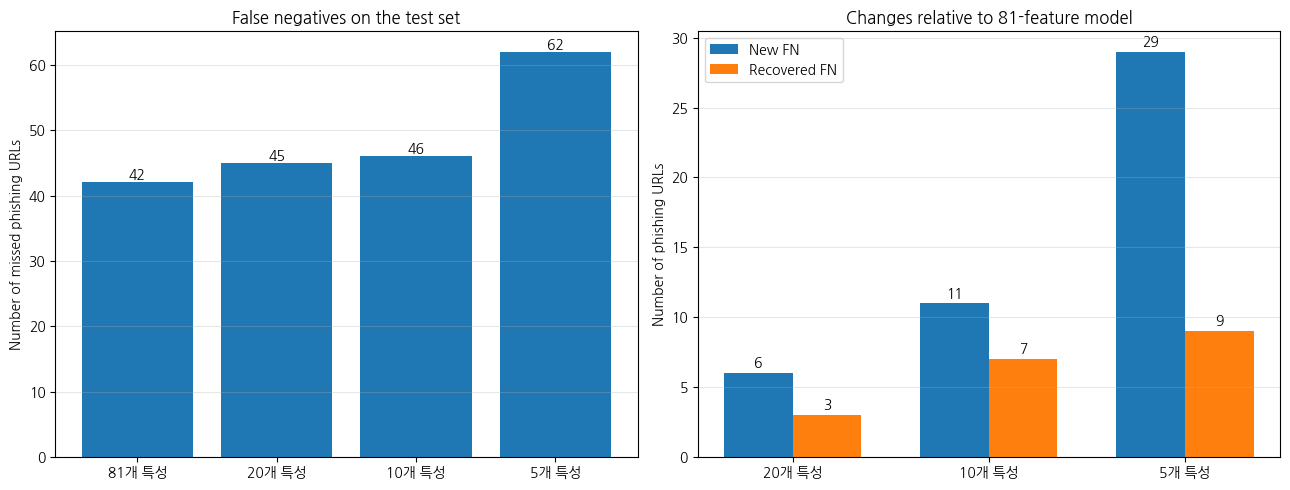

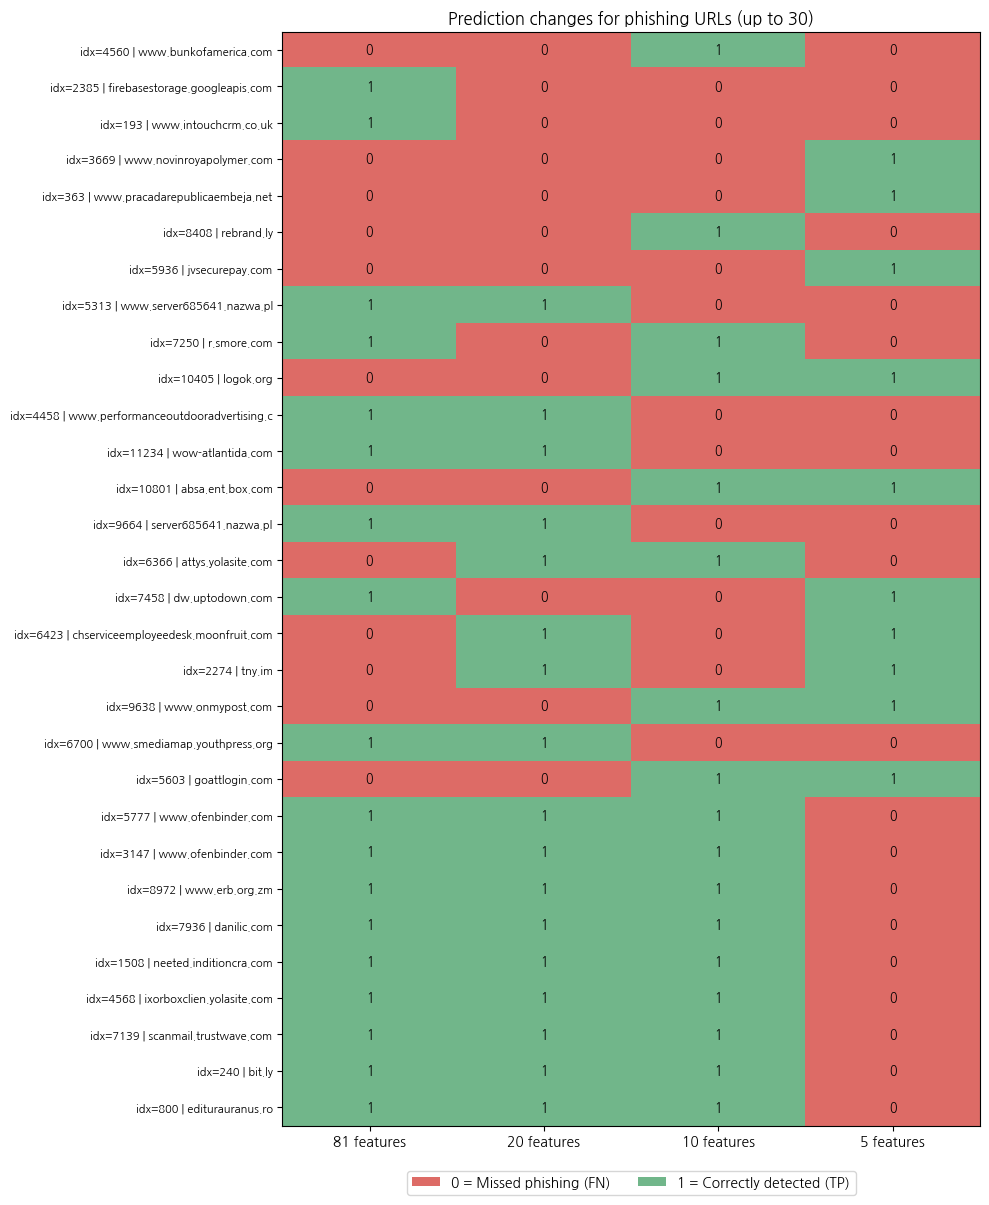

히트맵에 표시된 원본 URL (idx로 그래프 행과 대조 가능)


,url,domain,pred_81,pred_20,pred_10,pred_5
original_index,,,,,,
4560,http://www.bunkofamerica.com,www.bunkofamerica.com,0,0,1,0
2385,https://firebasestorage.googleapis.com/v0/b/br...,firebasestorage.googleapis.com,1,0,0,0
193,https://www.intouchcrm.co.uk/app/settings/sign...,www.intouchcrm.co.uk,1,0,0,0
3669,http://www.novinroyapolymer.com/,www.novinroyapolymer.com,0,0,0,1
363,http://www.pracadarepublicaembeja.net/men,www.pracadarepublicaembeja.net,0,0,0,1
8408,http://rebrand.ly/App_novo_cadastro,rebrand.ly,0,0,1,0
5936,http://jvsecurepay.com/access/auth/login.html,jvsecurepay.com,0,0,0,1
5313,http://www.server685641.nazwa.pl/weryfikacja/,www.server685641.nazwa.pl,1,1,0,0
7250,https://r.smore.com/c?u=https://yanamholidays....,r.smore.com,1,0,1,0


In [56]:
# =============================================================
# 3. 미탐/오탐 및 예측 변화 요약표 + 시각화
# =============================================================
model_summary_rows = []
actual = site_predictions['actual']
num_phishing = int(actual.eq(1).sum())
metric_table = final_results_df.set_index('모델')

for model_name, pred_col in model_columns.items():
    pred = site_predictions[pred_col]
    tn, fp, fn, tp = confusion_matrix(actual, pred, labels=[0, 1]).ravel()

    # 81개 특성 모델에 비해 새로 놓치게 된 피싱 URL
    newly_missed = int((actual.eq(1) & base_pred.eq(1) & pred.eq(0)).sum())
    # 81개 모델은 놓쳤지만 축소 모델이 찾아낸 피싱 URL
    recovered = int((actual.eq(1) & base_pred.eq(0) & pred.eq(1)).sum())

    model_summary_rows.append({
        '모델': model_name,
        '특성 수': len(feature_sets[model_name]),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        '피싱 미탐률(%)': fn / num_phishing * 100 if num_phishing else np.nan,
        '81개 대비 신규 미탐': newly_missed,
        '81개 대비 미탐 해소': recovered,
        '81개 대비 FN 순증가': newly_missed - recovered,
        '81개 대비 예측 변경 URL 수': int(pred.ne(base_pred).sum()),
        'Accuracy': float(metric_table.loc[model_name, 'Accuracy']),
        'Precision': float(metric_table.loc[model_name, 'Precision']),
        'Recall': float(metric_table.loc[model_name, 'Recall']),
        'F1': float(metric_table.loc[model_name, 'F1'])
    })

model_summary_df = pd.DataFrame(model_summary_rows)
model_summary_df.to_csv(SAVE_DIR / 'model_error_summary.csv', index=False, encoding='utf-8-sig')
print('\n모델별 전체 비교')
display(model_summary_df.round(4))

# (1) FN 절대 건수 / 신규 미탐 vs 해소된 미탐
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = model_summary_df['모델'].tolist()
fn_counts = model_summary_df['FN'].to_numpy()
axes[0].bar(range(len(labels)), fn_counts)
axes[0].set_xticks(range(len(labels)), labels)
axes[0].set_title('False negatives on the test set')
axes[0].set_ylabel('Number of missed phishing URLs')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(fn_counts):
    axes[0].text(i, v, str(v), ha='center', va='bottom')

reduced = model_summary_df.iloc[1:]
x = np.arange(len(reduced))
w = 0.35
axes[1].bar(x - w / 2, reduced['81개 대비 신규 미탐'], width=w, label='New FN')
axes[1].bar(x + w / 2, reduced['81개 대비 미탐 해소'], width=w, label='Recovered FN')
axes[1].set_xticks(x, reduced['모델'])
axes[1].set_title('Changes relative to 81-feature model')
axes[1].set_ylabel('Number of phishing URLs')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)
for container in axes[1].containers:
    axes[1].bar_label(container, padding=2)

plt.tight_layout()
plt.savefig(SAVE_DIR / 'fn_counts_and_changes.png', dpi=200, bbox_inches='tight')
plt.show()

# (2) 예측이 변한 피싱 URL 가운데 최대 30개를 보여주는 히트맵
# 피싱 URL만 대상이므로 1 = 탐지 성공, 0 = 미탐
if not phishing_changed_df.empty:
    heatmap_df = phishing_changed_df.copy()
    heatmap_df['missed_models'] = (heatmap_df[prediction_cols] == 0).sum(axis=1)
    heatmap_df = heatmap_df.sort_values('missed_models', ascending=False).head(30)

    fig_height = max(4, len(heatmap_df) * 0.35 + 1.6)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    im = ax.imshow(
        heatmap_df[prediction_cols].to_numpy(),
        aspect='auto', vmin=0, vmax=1,
        cmap=ListedColormap(['#dd6b66', '#71b68a'])
    )
    ax.set_xticks(range(4), ['81 features', '20 features', '10 features', '5 features'])
    ax.set_yticks(range(len(heatmap_df)))
    ax.set_yticklabels([
        f'idx={idx} | {str(domain)[:35]}'
        for idx, domain in zip(heatmap_df.index, heatmap_df['domain'])
    ], fontsize=8)
    for r in range(len(heatmap_df)):
        for c in range(4):
            ax.text(c, r, str(heatmap_df.iloc[r][prediction_cols[c]]),
                    ha='center', va='center', fontsize=9)
    ax.set_title('Prediction changes for phishing URLs (up to 30)')
    ax.legend(handles=[
        Patch(facecolor='#dd6b66', label='0 = Missed phishing (FN)'),
        Patch(facecolor='#71b68a', label='1 = Correctly detected (TP)')
    ], loc='upper center', bbox_to_anchor=(0.5, -0.035), ncol=2)
    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'changed_phishing_heatmap.png', dpi=200, bbox_inches='tight')
    plt.show()
    print('히트맵에 표시된 원본 URL (idx로 그래프 행과 대조 가능)')
    display(heatmap_df[['url', 'domain'] + prediction_cols])
else:
    print('피싱 URL에 대해 81개 모델과 예측이 달라진 사례가 없습니다.')

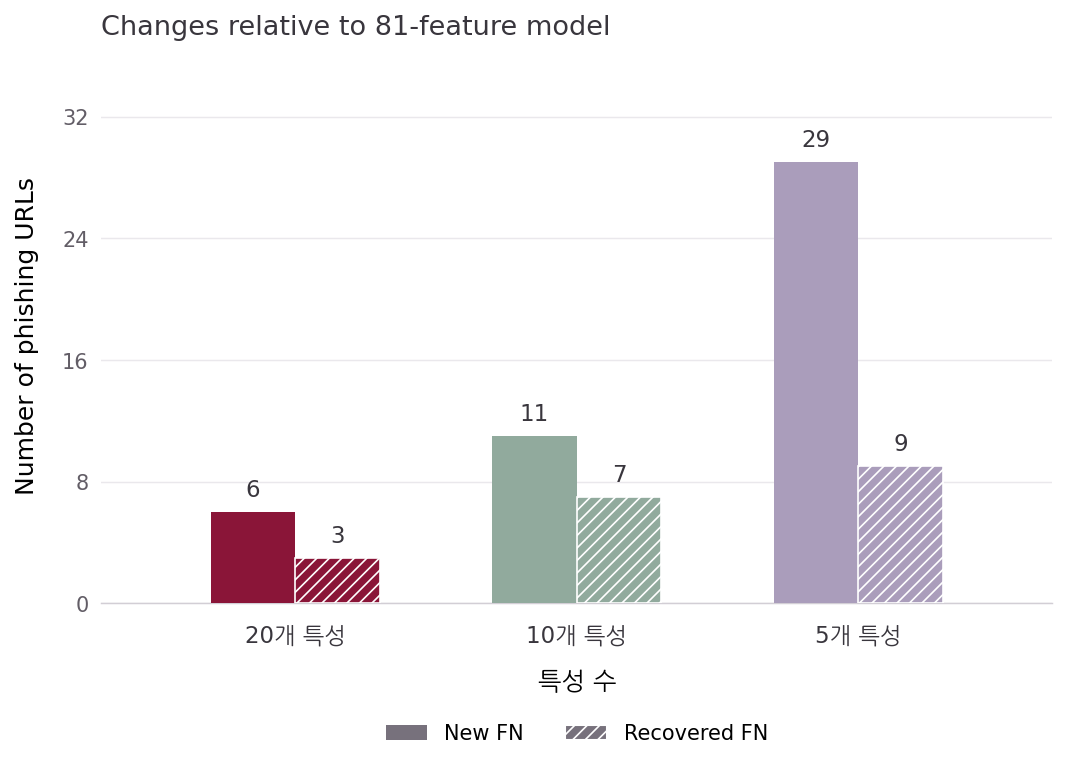

In [71]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

# 앞서 설치한 한글 폰트 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
else:
    raise FileNotFoundError(
        '나눔고딕을 먼저 설치해주세요: !apt-get -qq install -y fonts-nanum'
    )

# 특성 수를 기준으로 축소 모델 선택 및 정렬
reduced = (
    model_summary_df
    .loc[model_summary_df['특성 수'].isin([20, 10, 5])]
    .sort_values('특성 수', ascending=False)
    .copy()
)

model_colors = {
    20: '#8A1538',  # 버건디
    10: '#91AA9D',  # 세이지
    5: '#AA9DBB',   # 라벤더
}

colors = [model_colors[int(n)] for n in reduced['특성 수']]
labels = [f'{int(n)}개 특성' for n in reduced['특성 수']]

new_fn = reduced['81개 대비 신규 미탐'].to_numpy(dtype=int)
recovered_fn = reduced['81개 대비 미탐 해소'].to_numpy(dtype=int)

x = np.arange(len(reduced))
w = 0.30

with plt.rc_context({
    'font.family': ['DejaVu Sans', 'NanumGothic'],
    'font.size': 11,
    'font.weight': 'normal',
    'axes.titlesize': 13,
    'axes.titleweight': 'normal',
    'axes.labelsize': 12,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 11,
    'ytick.labelsize': 10,
    'axes.unicode_minus': False,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'hatch.linewidth': 0.8,
}):
    fig, ax = plt.subplots(
        figsize=(7, 5),
        layout='constrained',
    )
    fig.set_facecolor('white')
    ax.set_facecolor('white')

    # 신규 미탐: 모델별 단색
    bars_new = ax.bar(
        x - w / 2,
        new_fn,
        width=w,
        color=colors,
        edgecolor='none',
        zorder=3,
    )

    # 미탐 해소: 같은 모델 색상 + 빗금
    bars_recovered = ax.bar(
        x + w / 2,
        recovered_fn,
        width=w,
        color=colors,
        edgecolor='white',
        linewidth=0.8,
        hatch='////',
        zorder=3,
    )

    ax.bar_label(
        bars_new,
        padding=5,
        fontsize=11,
        color='#39363D',
    )
    ax.bar_label(
        bars_recovered,
        padding=5,
        fontsize=11,
        color='#39363D',
    )

    ax.set_xticks(x, labels)
    ax.set_title(
        'Changes relative to 81-feature model',
        loc='left',
        pad=16,
        color='#39363D',
    )
    ax.set_xlabel('특성 수', labelpad=11)
    ax.set_ylabel('Number of phishing URLs', labelpad=11)

    # 정수 눈금과 수치 표시 공간 확보
    max_count = max(int(new_fn.max()), int(recovered_fn.max()), 1)
    ax.set_ylim(0, max_count * 1.18 + 1)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))

    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#EAE8EC', linewidth=0.7)
    ax.grid(axis='x', visible=False)

    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)

    ax.spines['bottom'].set_color('#D2CED5')
    ax.spines['bottom'].set_linewidth(0.7)

    ax.tick_params(axis='x', length=0, pad=10, colors='#39363D')
    ax.tick_params(axis='y', length=0, pad=6, colors='#625D66')
    ax.margins(x=0.15)

    # 색상은 모델, 빗금 여부는 미탐 변화 유형을 나타냄
    ax.legend(
        handles=[
            Patch(
                facecolor='#77717C',
                edgecolor='none',
                label='New FN',
            ),
            Patch(
                facecolor='#77717C',
                edgecolor='white',
                hatch='////',
                label='Recovered FN',
            ),
        ],
        loc='upper center',
        bbox_to_anchor=(0.5, -0.19),
        ncol=2,
        frameon=False,
        fontsize=10,
    )

    fig.savefig(
        SAVE_DIR / 'fn_changes_comparison.png',
        dpi=600,
        facecolor='white',
    )

    plt.show()

<a id="step-09"></a>
## 09. 설명가능한 AI: LIME·SHAP과 개별 URL 분석

**이 단계의 질문:** 같은 피싱 사이트를 81개 모델이 놓치고 20개 모델이 탐지한 이유를 특성 기여도로 설명할 수 있을까?

이 구간은 기존의 **LIME·SHAP 분석 코드, 예측 근거 그래프, 기여도 변화 그래프 및 저장된 출력 전체**를 유지합니다. 코드가 참조하는 `final_models`, `final_predictions` 등의 값은 앞선 셀에서 생성됩니다.

> 기존 코드에 `%pip install`, OS별 폰트 관련 코드, 결과 디렉터리 생성이 들어 있습니다. 환경 의존성이 있어도 원본 변경을 피하기 위해 손대지 않았습니다.

# 4. 설명가능한 AI - LIME과 SHAP의 decision plot

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✅ 한글 폰트 설정 완료: ['NanumGothic']
전체 분석 대상: 3건


,original_index,url,domain,81개 특성,20개 특성,10개 특성,5개 특성
0,6366,http://attys.yolasite.com/,attys.yolasite.com,0,1,1,0
1,6423,http://chserviceemployeedesk.moonfruit.com/,chserviceemployeedesk.moonfruit.com,0,1,0,1
2,2274,http://tny.im/a6p~,tny.im,0,1,0,1


[1/3] attys.yolasite.com 분석 중


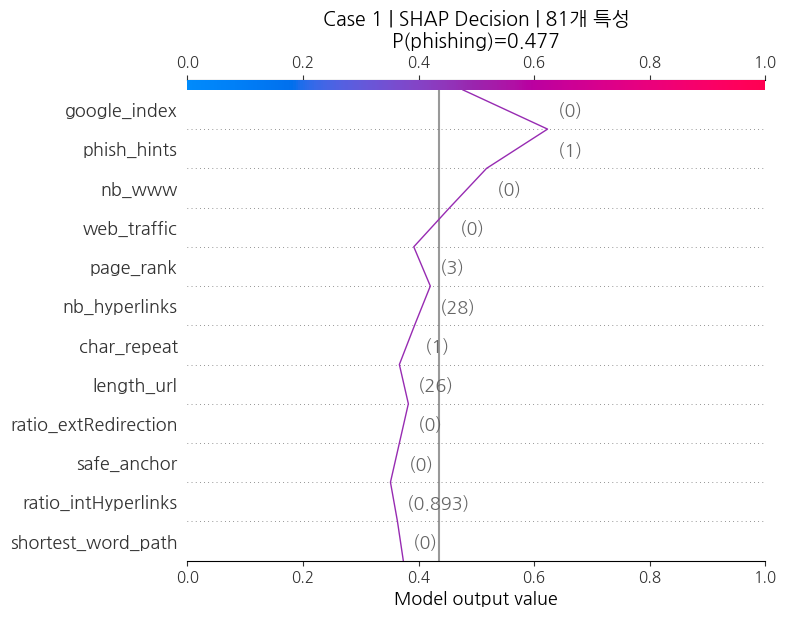

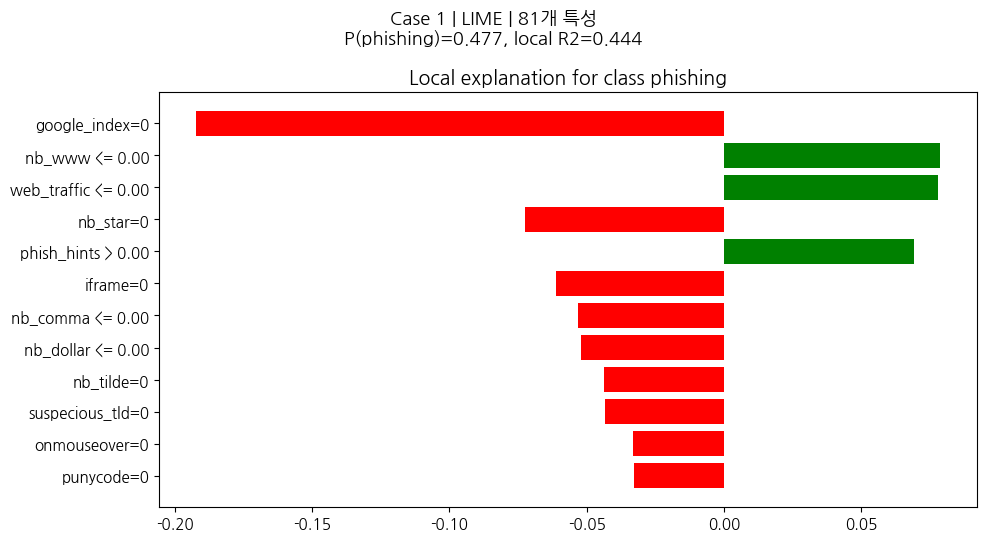

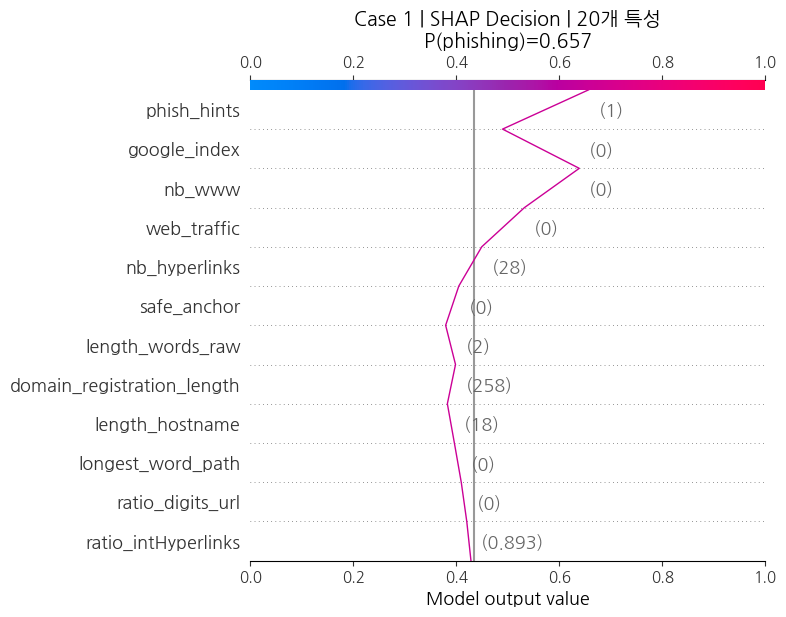

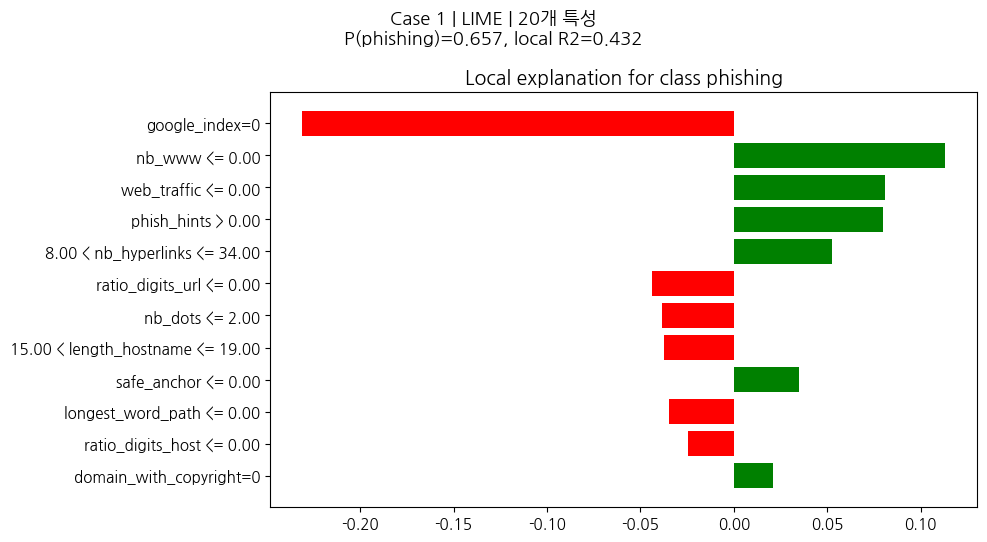

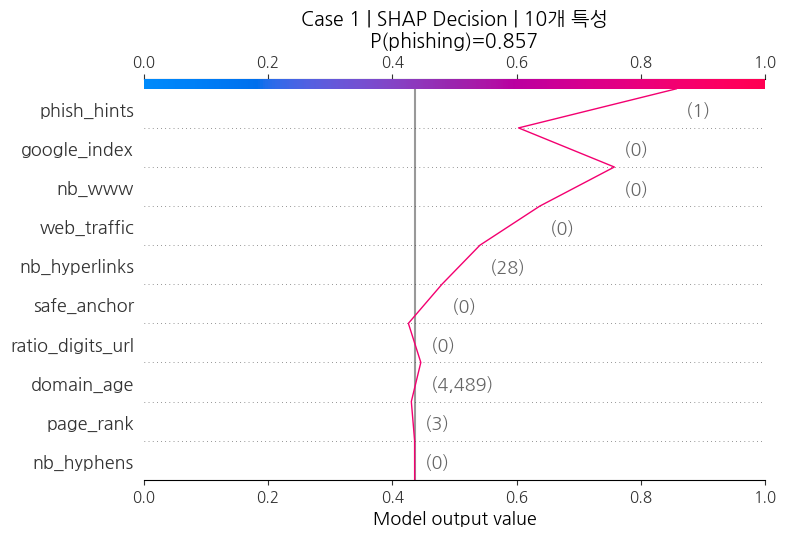

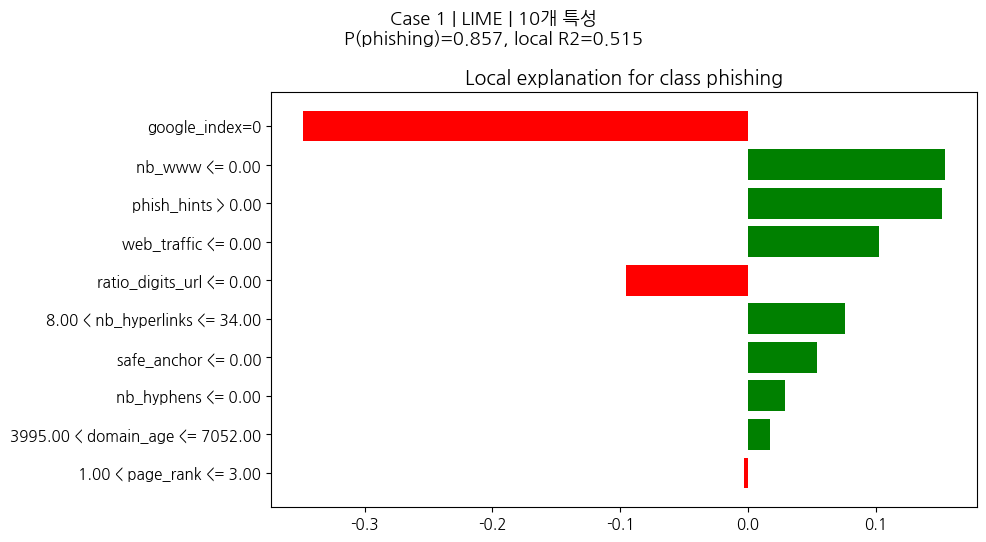

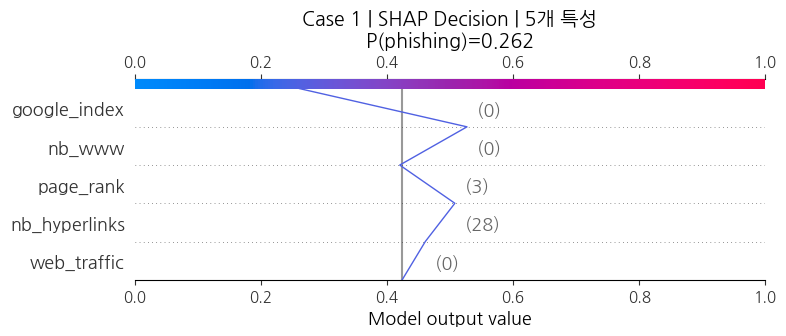

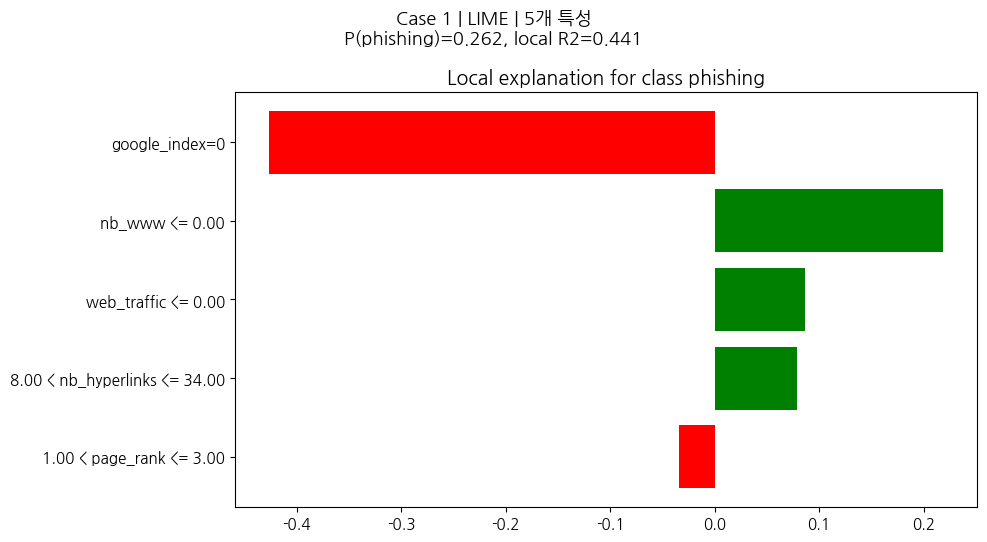

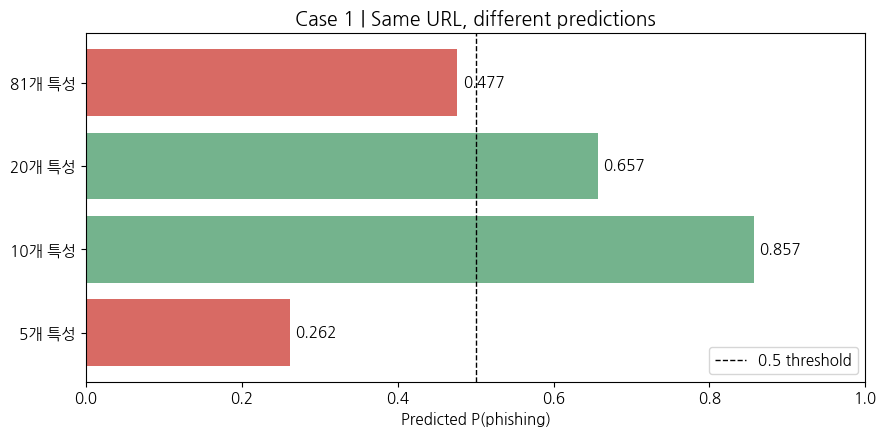

[2/3] chserviceemployeedesk.moonfruit.com 분석 중
[3/3] tny.im 분석 중

[모델별 예측 확률 및 설명 충실도]


,case_no,model,prediction,p_phishing,shap_additivity_error,lime_local_r2,lime_local_error
0,1,81개 특성,0,0.4767,0.0,0.4439,0.0883
1,1,20개 특성,1,0.6567,0.0,0.4322,0.0893
2,1,10개 특성,1,0.8567,0.0,0.5150,0.2123
3,1,5개 특성,0,0.2616,0.0,0.4414,0.1892
4,2,81개 특성,0,0.4367,0.0,0.4690,0.0930
5,2,20개 특성,1,0.5167,0.0,0.4575,0.2584
6,2,10개 특성,0,0.4733,0.0,0.5416,0.3886
7,2,5개 특성,1,0.8067,0.0,0.4533,0.7563
8,3,81개 특성,0,0.4333,0.0,0.5369,0.0441
9,3,20개 특성,1,0.5667,0.0,0.5014,0.1543



[모델별 설명 지표 요약]


,model,n_cases,mean_p_phishing,mean_shap_additivity_error,mean_lime_local_r2,mean_lime_local_error
0,81개 특성,3,0.4489,0.0,0.4833,0.0751
1,20개 특성,3,0.5800,0.0,0.4637,0.1673
2,10개 특성,3,0.5700,0.0,0.5291,0.2246
3,5개 특성,3,0.6005,0.0,0.4637,0.4478



[모델별 평균 절대 SHAP 기여도 상위 5개]


,model,feature,mean_shap,mean_abs_shap,positive_share
30,5개 특성,google_index,-0.2006,0.2006,0.0000
1,10개 특성,google_index,-0.1771,0.1771,0.0000
32,5개 특성,nb_www,0.1669,0.1669,1.0000
31,5개 특성,nb_hyperlinks,0.1643,0.1643,1.0000
13,20개 특성,google_index,-0.1422,0.1422,0.0000
50,81개 특성,google_index,-0.1387,0.1387,0.0000
4,10개 특성,nb_www,0.1215,0.1215,1.0000
21,20개 특성,nb_www,0.0993,0.0993,1.0000
6,10개 특성,phish_hints,0.0739,0.0952,0.3333
34,5개 특성,web_traffic,0.0889,0.0889,1.0000



전체 3건 분석 완료!
저장 폴더: /content/phishing_analysis_results/LIME_SHAP_all_cases
화면 미리보기는 1 건이지만 전체 사례 분석 결과를 저장했습니다.
주의: 피싱 URL은 직접 접속하지 마세요.
SHAP 기여도는 모델별 예측 설명이며 인과관계를 의미하지 않습니다.


In [57]:
%pip install -q shap lime


import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# 그래프 기본 설정
mpl.rcParams['figure.figsize'] = (10, 6)
mpl.rcParams['font.size'] = 11
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 11

# ============================================================
# LIME + SHAP: 81개 특성 모델 미탐,
# 20개 특성 모델 탐지 사례 분석
# 실제 피싱(1), 81개 모델 예측(0), 20개 모델 예측(1)
#
# 기존 변수:
# X_dev, X_test, y_test, df_clean,
# feature_sets, final_models, final_predictions
# ============================================================

from pathlib import Path
from urllib.parse import urlsplit
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

from lime.lime_tabular import LimeTabularExplainer
import shap


# ============================================================
# 1. 분석 설정
# ============================================================

MODEL_ORDER = [
    '81개 특성',
    '20개 특성',
    '10개 특성',
    '5개 특성'
]

BACKGROUND_SIZE = 50
LIME_SAMPLES = 2000
TOP_N = 12

# 화면에 미리 표시할 사례 수
# 실제 분석 대상 수에는 영향을 주지 않음!
PREVIEW_CASES = 1

RANDOM_STATE = 42

OUT = Path(
    'phishing_analysis_results/LIME_SHAP_all_cases'
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

# 시스템 설치 폰트 중 가능한 한글 폰트 자동 설정
font_names = {
    f.name
    for f in font_manager.fontManager.ttflist
}

for font in [
    'AppleGothic',
    'Malgun Gothic',
    'NanumGothic',
    'Noto Sans CJK KR',
    'DejaVu Sans'
]:
    if font in font_names:
        plt.rcParams['font.family'] = font
        break

plt.rcParams['axes.unicode_minus'] = False
print(f"✅ 한글 폰트 설정 완료: {plt.rcParams['font.family']}")

# ============================================================
# 2. 예측 역전 사례 전체 추출
# ============================================================


# ============================================================
# 2. 81개 모델은 미탐했지만 20개 모델은 탐지한 사례 추출
# ============================================================

assert X_test.index.equals(y_test.index)
assert X_test.index.is_unique
assert df_clean.index.is_unique
assert X_test.index.isin(df_clean.index).all()

# 모델별 예측값
predictions = {}

for model_name in MODEL_ORDER:

    predictions[model_name] = np.asarray(
        final_predictions[model_name]
    ).ravel()

    assert len(predictions[model_name]) == len(X_test), (
        f'{model_name}: 예측 길이 불일치'
    )

# 분석 조건
# 실제 피싱 = 1
# 81개 모델 = 0 (미탐)
# 20개 모델 = 1 (탐지)

pattern = (
    (y_test.to_numpy().astype(int) == 1)
    & (predictions['81개 특성'] == 0)
    & (predictions['20개 특성'] == 1)
)

# 조건에 해당하는 사례 전체 추출
case_indices = X_test.index[pattern].tolist()

if not case_indices:
    raise ValueError(
        '81개 모델은 미탐하고 20개 모델은 탐지한 사례가 없습니다.'
    )

print(f'전체 분석 대상: {len(case_indices)}건')


# URL에서 도메인 추출
def extract_domain(url):

    if pd.isna(url):
        return None

    u = str(url).strip()

    if '://' not in u:
        u = 'http://' + u

    try:
        return urlsplit(u).hostname
    except ValueError:
        return None


# URL과 원본 인덱스 연결
cases_df = pd.DataFrame({
    'original_index': case_indices,
    'url': df_clean.loc[
        case_indices, 'url'
    ].to_numpy()
})

cases_df['domain'] = (
    cases_df['url'].map(extract_domain)
)

# 네 모델의 예측 결과 모두 기록
for model_name in MODEL_ORDER:

    preds_series = pd.Series(
        predictions[model_name],
        index=X_test.index
    )

    cases_df[model_name] = (
        preds_series.loc[case_indices].to_numpy()
    )

display(cases_df.head(20))

cases_df.to_csv(
    OUT / '81miss_20detect_cases.csv',
    index=False,
    encoding='utf-8-sig'
)

# ============================================================
# 3. SHAP 및 LIME 설명기 생성
# ============================================================

# 모델 학습에 사용한 개발 데이터에서 배경 표본 추출
background = X_dev.sample(
    n=min(BACKGROUND_SIZE, len(X_dev)),
    random_state=RANDOM_STATE
)

shap_explainers = {}
lime_explainers = {}
pred_series = {}

for model_name in MODEL_ORDER:

    model = final_models[model_name]
    feats = list(feature_sets[model_name])

    # 학습된 모델과 특성 순서 일치 확인
    assert list(model.feature_names_in_) == feats, (
        f'{model_name}: 학습 특성 순서 불일치'
    )

    assert 1 in model.classes_, (
        f'{model_name}: 피싱 클래스가 없습니다.'
    )

    pred_series[model_name] = pd.Series(
        np.asarray(final_predictions[model_name]),
        index=X_test.index
    )

    # SHAP: 피싱 예측 확률을 설명
    shap_explainers[model_name] = (
        shap.TreeExplainer(
            model,
            data=background[feats],
            feature_perturbation='interventional',
            model_output='probability'
        )
    )

    # 이진 특성 식별
    category_cols = [
        i
        for i, f in enumerate(feats)
        if set(
            X_dev[f].dropna().unique()
        ).issubset({0, 1})
    ]

    # LIME 설명기
    lime_explainers[model_name] = (
        LimeTabularExplainer(
            training_data=X_dev[
                feats
            ].to_numpy(dtype=float),

            feature_names=feats,

            class_names=[
                'legitimate' if label == 0
                else 'phishing'
                for label in model.classes_
            ],

            categorical_features=category_cols,

            discretize_continuous=True,
            mode='classification',
            random_state=RANDOM_STATE
        )
    )


# ============================================================
# 4. SHAP 클래스별 값 추출 함수
# ============================================================

def shap_for_phishing(
    explainer,
    sample,
    positive_idx
):

    raw_values = explainer.shap_values(sample)

    # 구버전 SHAP
    if isinstance(raw_values, list):

        phi = np.asarray(
            raw_values[positive_idx]
        )[0]

    # 신버전 SHAP
    else:

        raw_values = np.asarray(raw_values)

        if raw_values.ndim == 3:

            phi = raw_values[
                0, :, positive_idx
            ]

        elif raw_values.ndim == 2:

            phi = raw_values[0]

        else:
            raise ValueError(
                f'SHAP shape 오류: '
                f'{raw_values.shape}'
            )

    expected = np.asarray(
        explainer.expected_value
    )

    base = float(
        expected[positive_idx]
        if expected.ndim
        else expected
    )

    return base, np.asarray(
        phi,
        dtype=float
    )


# 그래프 저장 함수
def finish_plot(path, preview=False):

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=160,
        bbox_inches='tight'
    )

    if preview:
        plt.show()

    plt.close()


# ============================================================
# 5. 모든 URL에 SHAP + LIME 적용
# ============================================================

summary_records = []
shap_records = []
lime_records = []

for case_no, idx in enumerate(
    case_indices,
    start=1
):

    url = df_clean.loc[idx, 'url']
    domain = extract_domain(url)

    show = case_no <= PREVIEW_CASES

    print(
        f'[{case_no}/{len(case_indices)}] '
        f'{domain} 분석 중'
    )

    probabilities = []

    for model_name in MODEL_ORDER:

        model = final_models[model_name]

        feats = list(
            feature_sets[model_name]
        )

        sample = X_test.loc[
            [idx], feats
        ]

        positive_idx = list(
            model.classes_
        ).index(1)

        # 피싱 확률 및 예측
        p1 = float(
            model.predict_proba(
                sample
            )[0, positive_idx]
        )

        pred = int(
            model.predict(sample)[0]
        )

        # 이전 모델의 예측과 동일한지 확인
        if pred != int(
            pred_series[model_name].loc[idx]
        ):
            raise RuntimeError(
                f'{model_name}: 저장된 예측과 '
                f'현재 예측이 다릅니다.'
            )

        probabilities.append(p1)


        # ====================================
        # 5-1. SHAP 분석
        # ====================================

        base, phi = shap_for_phishing(
            shap_explainers[model_name],
            sample,
            positive_idx
        )

        # SHAP 가산성 확인
        shap_error = abs(
            (base + phi.sum()) - p1
        )

        if shap_error > 1e-3:
            warnings.warn(
                f'사례 {case_no}, {model_name}: '
                f'SHAP 오차 {shap_error:.5f}'
            )

        # 전체 특성의 SHAP 기여도 저장
        feature_values = (
            sample.iloc[0].to_numpy()
        )

        for f, v, s in zip(
            feats,
            feature_values,
            phi
        ):

            shap_records.append({
                'case_no': case_no,
                'original_index': idx,
                'url': url,
                'model': model_name,
                'feature': f,
                'feature_value': v,
                'shap_value_for_phishing': float(s),
                'shap_base': base
            })


        # SHAP Decision Plot 생성
        shap.decision_plot(
            base,
            phi,
            features=sample.iloc[0],
            feature_names=feats,
            feature_order='importance',

            feature_display_range=slice(
                -1,
                -min(TOP_N, len(feats)) - 1,
                -1
            ),

            xlim=(0, 1),
            show=False
        )

        plt.title(
            f'Case {case_no} | '
            f'SHAP Decision | {model_name}\n'
            f'P(phishing)={p1:.3f}'
        )

        finish_plot(
            OUT / (
                f'case{case_no:03d}_'
                f'SHAP_{len(feats)}.png'
            ),
            preview=show
        )


        # ====================================
        # 5-2. LIME 분석
        # ====================================

        def predict_prob(
            arr,
            m=model,
            columns=feats
        ):

            return m.predict_proba(
                pd.DataFrame(
                    arr,
                    columns=columns
                )
            )


        lime_result = (
            lime_explainers[model_name]
            .explain_instance(

                data_row=sample.iloc[
                    0
                ].to_numpy(dtype=float),

                predict_fn=predict_prob,

                labels=(positive_idx,),

                num_features=min(
                    TOP_N,
                    len(feats)
                ),

                num_samples=LIME_SAMPLES
            )
        )

        # LIME 설명 품질
        local_r2 = float(
            lime_result.score
        )

        local_prediction = float(
            np.ravel(
                lime_result.local_pred
            )[0]
        )

        # LIME 결과 저장
        for rule, weight in lime_result.as_list(
            label=positive_idx
        ):

            lime_records.append({
                'case_no': case_no,
                'original_index': idx,
                'url': url,
                'model': model_name,
                'rule': rule,
                'lime_weight_for_phishing': float(weight),
                'local_r2': local_r2
            })


        # LIME 그래프 생성
        fig = lime_result.as_pyplot_figure(
            label=positive_idx
        )

        fig.set_size_inches(
            10,
            5.5
        )

        fig.suptitle(
            f'Case {case_no} | '
            f'LIME | {model_name}\n'
            f'P(phishing)={p1:.3f}, '
            f'local R2={local_r2:.3f}'
        )

        finish_plot(
            OUT / (
                f'case{case_no:03d}_'
                f'LIME_{len(feats)}.png'
            ),
            preview=show
        )


        # ====================================
        # 5-3. 모델별 설명 결과 종합
        # ====================================

        summary_records.append({
            'case_no': case_no,
            'original_index': idx,
            'url': url,
            'domain': domain,
            'model': model_name,
            'n_features': len(feats),
            'actual': 1,
            'prediction': pred,
            'p_phishing': p1,
            'shap_base': base,
            'shap_additivity_error': shap_error,
            'lime_local_r2': local_r2,
            'lime_local_prediction': local_prediction,
            'lime_local_error': abs(
                local_prediction - p1
            )
        })


    # ========================================
    # 5-4. 동일 URL의 예측 확률 비교
    # ========================================

    fig, ax = plt.subplots(
        figsize=(9, 4.5)
    )

    bar_colors = [
        '#d86a64' if p < 0.5
        else '#74b38d'
        for p in probabilities
    ]

    bars = ax.barh(
        MODEL_ORDER[::-1],
        probabilities[::-1],
        color=bar_colors[::-1]
    )

    ax.axvline(
        0.5,
        linestyle='--',
        color='black',
        linewidth=1,
        label='0.5 threshold'
    )

    ax.bar_label(
        bars,
        fmt='%.3f',
        padding=4
    )

    ax.set_xlim(0, 1)
    ax.set_xlabel(
        'Predicted P(phishing)'
    )

    ax.set_title(
        f'Case {case_no} | '
        f'Same URL, different predictions'
    )

    ax.legend(
        loc='lower right'
    )

    finish_plot(
        OUT / (
            f'case{case_no:03d}_'
            f'probabilities.png'
        ),
        preview=show
    )


# ============================================================
# 6. 전체 분석 결과 저장
# ============================================================

summary_df = pd.DataFrame(
    summary_records
)

shap_df = pd.DataFrame(
    shap_records
)

lime_df = pd.DataFrame(
    lime_records
)


summary_df.to_csv(
    OUT / 'all_case_model_summary.csv',
    index=False,
    encoding='utf-8-sig'
)

shap_df.to_csv(
    OUT / 'all_case_shap_contributions.csv',
    index=False,
    encoding='utf-8-sig'
)

lime_df.to_csv(
    OUT / 'all_case_lime_contributions.csv',
    index=False,
    encoding='utf-8-sig'
)


print(
    '\n[모델별 예측 확률 및 설명 충실도]'
)

display(
    summary_df[[
        'case_no',
        'model',
        'prediction',
        'p_phishing',
        'shap_additivity_error',
        'lime_local_r2',
        'lime_local_error'
    ]].head(20).round(4)
)


# ============================================================
# 7. 모델별 설명 품질 비교
# ============================================================

quality_df = (
    summary_df
    .groupby(
        'model',
        sort=False
    )
    .agg(
        n_cases=(
            'case_no',
            'nunique'
        ),

        mean_p_phishing=(
            'p_phishing',
            'mean'
        ),

        mean_shap_additivity_error=(
            'shap_additivity_error',
            'mean'
        ),

        mean_lime_local_r2=(
            'lime_local_r2',
            'mean'
        ),

        mean_lime_local_error=(
            'lime_local_error',
            'mean'
        )
    )
    .reset_index()
)

quality_df.to_csv(
    OUT / 'explanation_quality_summary.csv',
    index=False,
    encoding='utf-8-sig'
)

print(
    '\n[모델별 설명 지표 요약]'
)

display(
    quality_df.round(4)
)


# ============================================================
# 8. 전체 사례의 SHAP 특성 기여도 종합
# ============================================================

feature_summary = (
    shap_df
    .groupby(
        ['model', 'feature'],
        as_index=False
    )
    .agg(
        mean_shap=(
            'shap_value_for_phishing',
            'mean'
        ),

        mean_abs_shap=(
            'shap_value_for_phishing',
            lambda v: v.abs().mean()
        ),

        positive_share=(
            'shap_value_for_phishing',
            lambda v: (v > 0).mean()
        )
    )
)

feature_summary.to_csv(
    OUT / 'shap_feature_summary_all_cases.csv',
    index=False,
    encoding='utf-8-sig'
)

print(
    '\n[모델별 평균 절대 SHAP 기여도 상위 5개]'
)

display(
    feature_summary
    .sort_values(
        'mean_abs_shap',
        ascending=False
    )
    .groupby(
        'model',
        sort=False
    )
    .head(5)
    .round(4)
)


# ============================================================
# 9. 완료 메시지
# ============================================================

print(
    f'\n전체 {len(case_indices)}건 분석 완료!'
)

print(
    '저장 폴더:',
    OUT.resolve()
)

print(
    '화면 미리보기는',
    PREVIEW_CASES,
    '건이지만 전체 사례 분석 결과를 저장했습니다.'
)

print(
    '주의: 피싱 URL은 직접 접속하지 마세요.'
)

print(
    'SHAP 기여도는 모델별 예측 설명이며 '
    '인과관계를 의미하지 않습니다.'
)

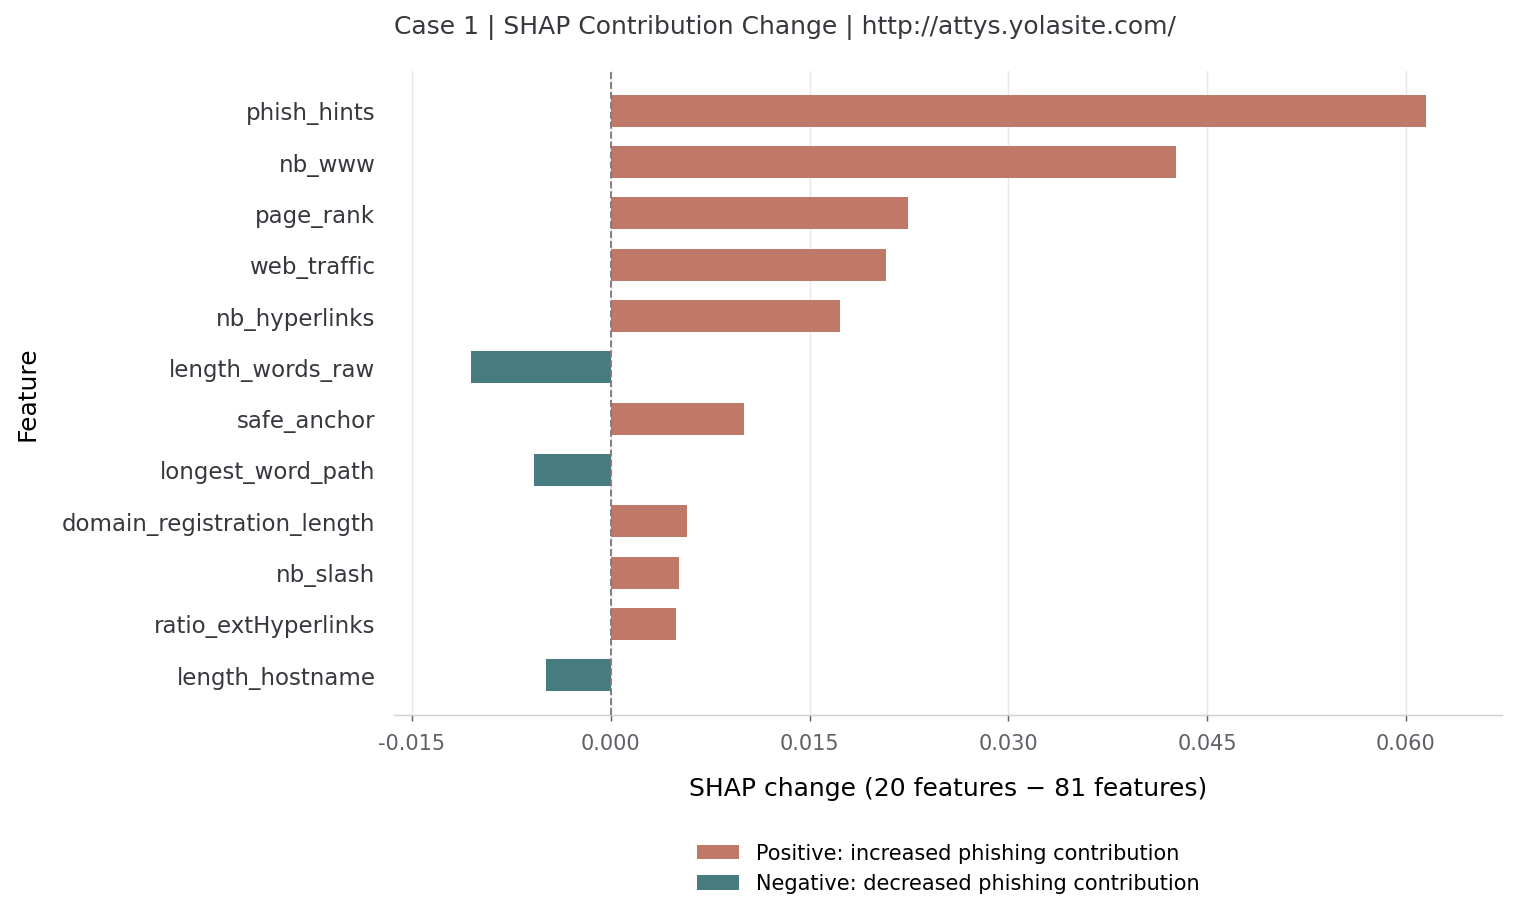

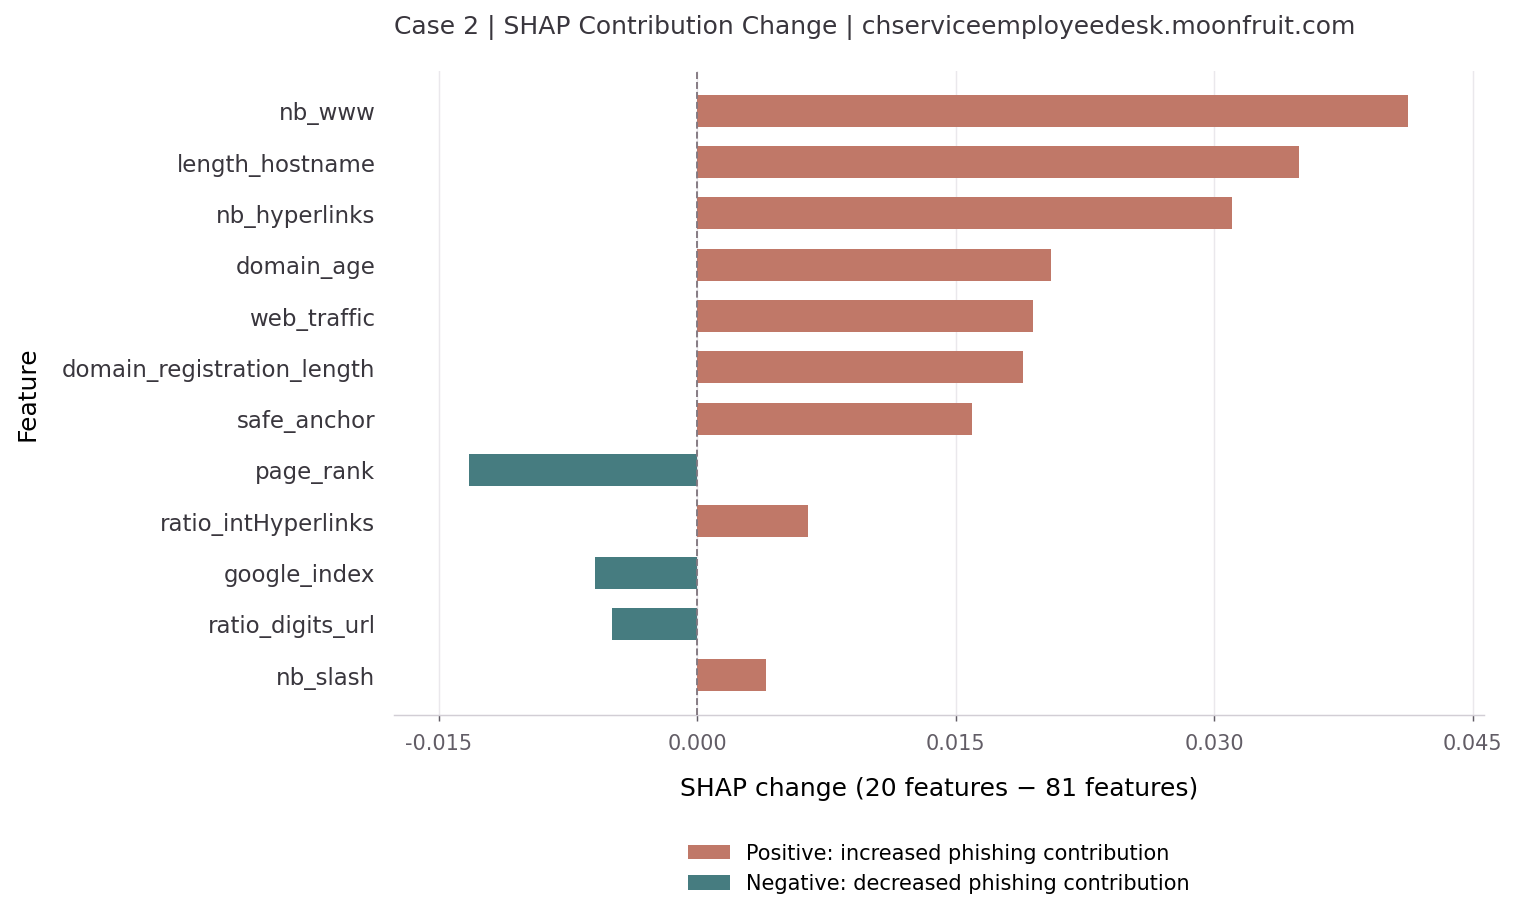

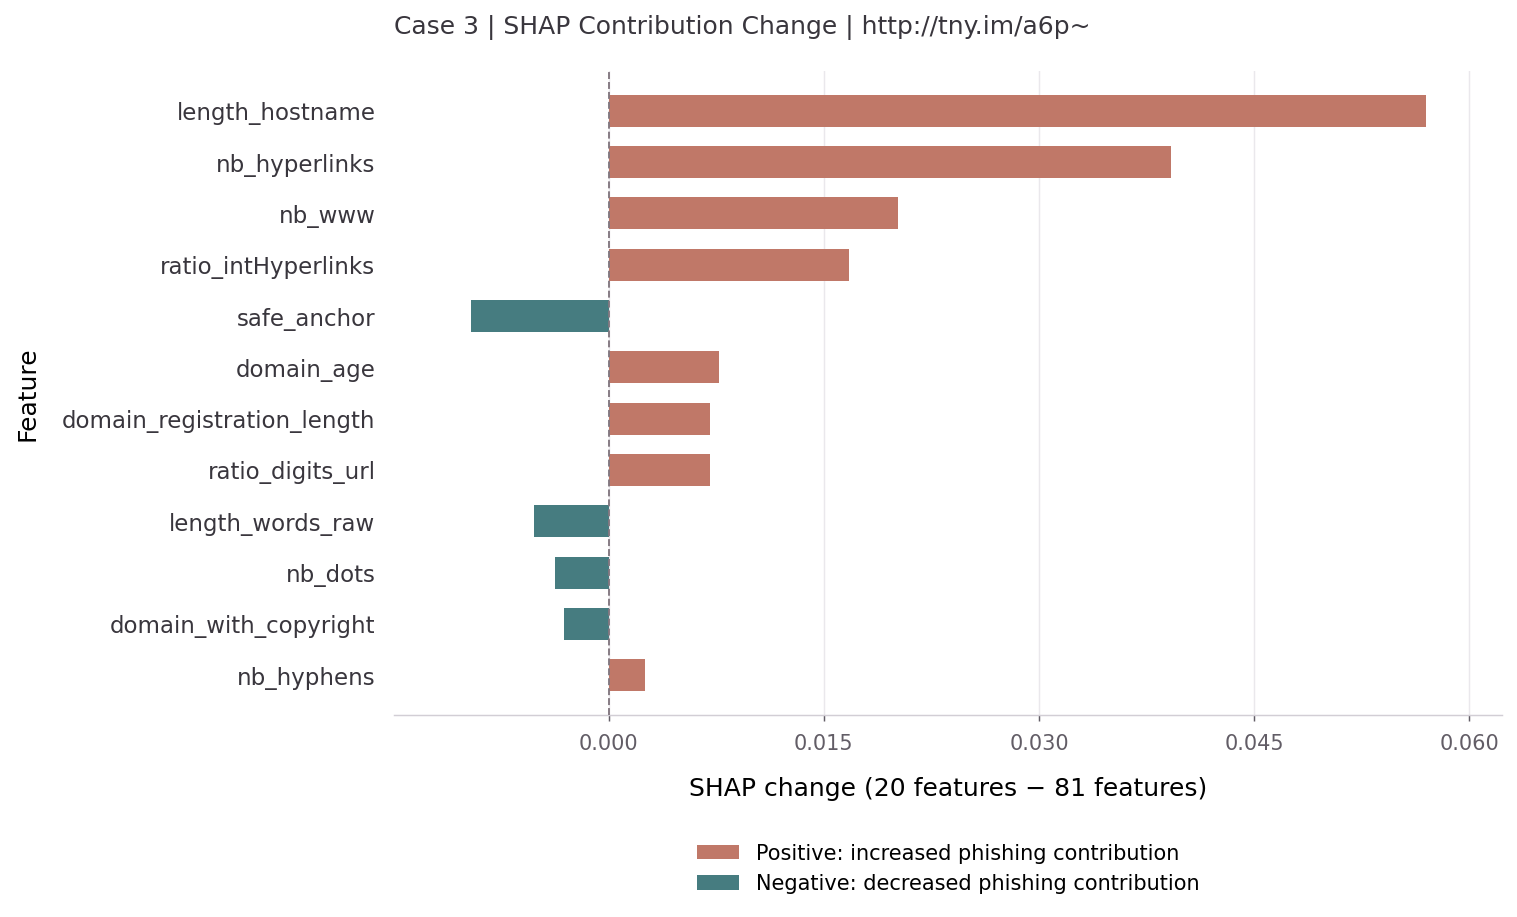

In [74]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

# ============================================================
# SHAP Contribution Change 그래프만 생성
# 기존 코드에서 생성한 shap_df, OUT 사용
# ============================================================

font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

OUT.mkdir(parents=True, exist_ok=True)

POSITIVE_COLOR = '#C07868'  # 더스티 코랄: 피싱 판단 기여도 증가
NEGATIVE_COLOR = '#467C80'  # 딥 틸: 피싱 판단 기여도 감소

cases = [
    (1, 'http://attys.yolasite.com/'),
    (2, 'chserviceemployeedesk.moonfruit.com'),
    (3, 'http://tny.im/a6p~'),
]

TOP_N_CHANGE = 12  # 첨부 그림처럼 변화량 상위 12개 표시


# 프로토콜과 마지막 / 차이를 제거하여 URL 대조
def normalize_url(value):
    value = str(value).strip()
    for prefix in ('https://', 'http://'):
        if value.lower().startswith(prefix):
            value = value[len(prefix):]
            break
    return value.rstrip('/')


normalized_urls = shap_df['url'].map(normalize_url)

with plt.rc_context({
    'font.family': ['DejaVu Sans', 'NanumGothic'],
    'font.size': 11,
    'font.weight': 'normal',
    'axes.titlesize': 12,
    'axes.titleweight': 'normal',
    'axes.labelsize': 12,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 10,
    'ytick.labelsize': 11,
    'axes.unicode_minus': False,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
}):
    for case_no, url in cases:

        case_data = shap_df.loc[
            normalized_urls.eq(normalize_url(url))
            & shap_df['model'].isin(['81개 특성', '20개 특성'])
        ].copy()

        if case_data.empty:
            raise ValueError(f'Case {case_no}: SHAP 데이터에 URL이 없습니다: {url}')

        # 동일 URL이 여러 원본 행에 있으면 임의로 섞지 않도록 확인
        if case_data['original_index'].nunique() != 1:
            raise ValueError(
                f'Case {case_no}: 동일 URL의 원본 행이 여러 개입니다. '
                'original_index로 분석할 행을 지정해주세요.'
            )

        contributions = case_data.pivot(
            index='feature',
            columns='model',
            values='shap_value_for_phishing',
        )

        if not {'81개 특성', '20개 특성'}.issubset(contributions.columns):
            raise ValueError(f'Case {case_no}: 두 모델의 SHAP 값이 모두 필요합니다.')

        # 두 모델에 공통으로 존재하는 특성의 기여도 비교
        contributions = contributions.dropna(
            subset=['81개 특성', '20개 특성']
        )

        change = (
            contributions['20개 특성']
            - contributions['81개 특성']
        )

        # 절대 변화량이 큰 순서로 선택
        selected_features = (
            change.abs()
            .nlargest(TOP_N_CHANGE)
            .index
        )
        change = change.loc[selected_features]

        y = np.arange(len(change))
        bar_colors = np.where(
            change.to_numpy() >= 0,
            POSITIVE_COLOR,
            NEGATIVE_COLOR,
        )

        fig, ax = plt.subplots(
            figsize=(10, 6),
            layout='constrained',
        )
        fig.set_facecolor('white')
        ax.set_facecolor('white')

        ax.barh(
            y,
            change.to_numpy(),
            height=0.62,
            color=bar_colors,
            edgecolor='none',
            zorder=3,
        )

        ax.set_yticks(y, labels=change.index)
        ax.invert_yaxis()

        ax.set_title(
            f'Case {case_no} | SHAP Contribution Change | {url}',
            loc='left',
            pad=18,
            color='#39363D',
        )
        ax.set_xlabel(
            'SHAP change (20 features − 81 features)',
            labelpad=11,
        )
        ax.set_ylabel('Feature', labelpad=11)

        ax.axvline(
            0,
            color='#827780',
            linestyle='--',
            linewidth=0.9,
            zorder=4,
        )

        ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
        ax.set_axisbelow(True)
        ax.grid(axis='x', color='#EAE8EC', linewidth=0.7)
        ax.grid(axis='y', visible=False)

        for spine in ['top', 'right', 'left']:
            ax.spines[spine].set_visible(False)

        ax.spines['bottom'].set_color('#D2CED5')
        ax.spines['bottom'].set_linewidth(0.7)

        ax.tick_params(
            axis='y',
            length=0,
            pad=9,
            colors='#39363D',
        )
        ax.tick_params(
            axis='x',
            length=3,
            width=0.7,
            pad=6,
            colors='#625D66',
        )
        ax.margins(x=0.08, y=0.04)

        ax.legend(
            handles=[
                Patch(
                    facecolor=POSITIVE_COLOR,
                    label='Positive: increased phishing contribution',
                ),
                Patch(
                    facecolor=NEGATIVE_COLOR,
                    label='Negative: decreased phishing contribution',
                ),
            ],
            loc='upper center',
            bbox_to_anchor=(0.5, -0.17),
            frameon=False,
            fontsize=10,
            ncol=1,
        )

        filename = f'case{case_no:03d}_SHAP_contribution_change'

        fig.savefig(
            OUT / f'{filename}.png',
            dpi=600,
            facecolor='white',
        )
        fig.savefig(
            OUT / f'{filename}.pdf',
            facecolor='white',
        )

        plt.show()
        plt.close(fig)

In [58]:
### 1. 리눅스 시스템에 나눔 폰트 설치
!apt-get install -y fonts-nanum

### 2. Matplotlib 폰트 캐시 초기화 및 재빌드
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

fm._rebuild() if hasattr(fm, '_rebuild') else None

# 설치된 나눔 폰트 중 하나를 기본 폰트로 설정
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

print("✅ 나눔 폰트 설치 및 Matplotlib 설정 완료!")
print("이제 상단의 시각화 셀들을 다시 실행하시면 한글이 정상적으로 표시됩니다.")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
✅ 나눔 폰트 설치 및 Matplotlib 설정 완료!
이제 상단의 시각화 셀들을 다시 실행하시면 한글이 정상적으로 표시됩니다.


<a id="step-10"></a>
## 10. 교차검증·테스트·미탐·XAI 분석 종합

**이 단계의 질문:** 특성 수를 줄인 효과를 성능, 놓친 사례, 예측 근거까지 함께 놓고 어떻게 해석할까?

아래 기존 코드는 여러 단계의 결과를 종합하고, 일부 결과를 CSV 파일로 저장합니다. 그 뒤에는 **특정 사례의 SHAP 기여도 차이**를 더 자세히 살펴보는 원본 분석이 이어집니다.

## 4. 분석 결과 종합


In [59]:

# =============================================================
# 4. CV + 테스트 + 미탐 + 전체 예측 역전 + LIME/SHAP 최종 종합
# =============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

SAVE_DIR = Path('phishing_analysis_results')
XAI_DIR = SAVE_DIR / 'LIME_SHAP_all_cases'

SAVE_DIR.mkdir(parents=True, exist_ok=True)

ORDER = [
    '81개 특성',
    '20개 특성',
    '10개 특성',
    '5개 특성'
]


# =============================================================
# 1. 최종 성능 및 교차검증 종합
# =============================================================

m = model_summary_df.set_index('모델').loc[ORDER].copy()

cv = mean_results.loc[
    ORDER,
    ['Accuracy', 'Precision', 'Recall', 'F1']
]

cv_std = std_results.loc[ORDER, 'F1']

base = m.loc['81개 특성']

compare = m.copy()

compare['특성 감소율(%)'] = (
    1 - compare['특성 수'] / base['특성 수']
) * 100

compare['81개 대비 F1 변화(%p)'] = (
    compare['F1'] - base['F1']
) * 100

compare['81개 대비 Recall 변화(%p)'] = (
    compare['Recall'] - base['Recall']
) * 100

compare['CV F1 평균'] = cv['F1']
compare['CV F1 표준편차'] = cv_std

compare['CV-테스트 F1 차이(%p)'] = (
    compare['F1'] - cv['F1']
) * 100

print('\n[1] 모델별 CV·테스트 성능·오류 종합')

display(compare.round(4))

compare.to_csv(
    SAVE_DIR / 'final_all_model_comparison.csv',
    encoding='utf-8-sig'
)


# ============================================================
# 2. 81개 미탐 → 20개 탐지 사례 추출
# ============================================================

actual = y_test.to_numpy().astype(int)

pred_81 = np.asarray(
    final_predictions['81개 특성']
).ravel().astype(int)

pred_20 = np.asarray(
    final_predictions['20개 특성']
).ravel().astype(int)

mask = (
    (actual == 1)
    & (pred_81 == 0)
    & (pred_20 == 1)
)

ids = X_test.index[mask].tolist()

assert X_test.index.isin(df_clean.index).all()

urls = pd.DataFrame({
    'original_index': ids,
    'url': df_clean.loc[ids, 'url'].to_numpy()
})

urls['key'] = urls['original_index'].astype(str)

urls.to_csv(
    SAVE_DIR / 'final_reversal_urls.csv',
    index=False,
    encoding='utf-8-sig'
)

print(
    f'\n81개 미탐 → 20개 탐지 피싱 URL: {len(ids)}건'
)

display(urls.drop(columns='key').head(10))


# =============================================================
# 3. 앞에서 계산한 전체 XAI 결과 불러오기
# =============================================================

required_paths = {
    'xai': XAI_DIR / 'all_case_model_summary.csv',
    'shap': XAI_DIR / 'all_case_shap_contributions.csv',
    'lime': XAI_DIR / 'all_case_lime_contributions.csv'
}

missing = [
    p.name
    for p in required_paths.values()
    if not p.exists()
]

if missing:
    raise FileNotFoundError(
        '전체 사례 LIME/SHAP 분석 셀부터 실행하세요. '
        + ', '.join(missing)
    )

xai = pd.read_csv(required_paths['xai'])
shap_vals = pd.read_csv(required_paths['shap'])
lime_vals = pd.read_csv(required_paths['lime'])

for data in (xai, shap_vals, lime_vals):

    data['key'] = (
        data['original_index'].astype(str)
    )

    data.drop(
        data[
            ~data['key'].isin(set(urls['key']))
            | ~data['model'].isin(ORDER)
        ].index,
        inplace=True
    )

# 전체 사례가 분석되었는지 검증
expected_pairs = {
    (str(idx), name)
    for idx in ids
    for name in ORDER
}

actual_pairs = set(
    zip(xai['key'], xai['model'])
)

assert (
    len(xai) == len(expected_pairs)
    and actual_pairs == expected_pairs
), 'XAI 결과에 일부 사례가 누락되었습니다.'

shap_counts = shap_vals.groupby(
    ['key', 'model']
)['feature'].nunique()

lime_counts = lime_vals.groupby(
    ['key', 'model']
).size()

assert all(
    shap_counts.get(
        (str(idx), name), 0
    ) == len(feature_sets[name])
    for idx in ids
    for name in ORDER
), 'SHAP 일부 사례/특성 누락'

assert all(
    lime_counts.get(
        (str(idx), name), 0
    ) >= 1
    for idx in ids
    for name in ORDER
), 'LIME 일부 사례 누락'


# =============================================================
# 4. SHAP과 LIME 설명 품질 비교 및 방법 선택
# =============================================================

# SHAP: 실제 피싱 확률과 기여도 합의 오차
sums = shap_vals.groupby(
    ['key', 'model']
)['shap_value_for_phishing'].sum().rename(
    'shap_sum'
)

xai = xai.join(
    sums,
    on=['key', 'model']
)

xai['shap_reconstruction_error'] = (
    xai['shap_base']
    + xai['shap_sum']
    - xai['p_phishing']
).abs()

# LIME: 국소 설명 적합도 및 국소 오차
xai['lime_pass'] = (
    (xai['lime_local_r2'] >= 0.80)
    & (xai['lime_local_error'] <= 0.05)
)

quality = xai.groupby('model').agg(
    사례수=('key', 'nunique'),

    평균_피싱확률=('p_phishing', 'mean'),

    SHAP_평균재구성오차=(
        'shap_reconstruction_error',
        'mean'
    ),

    SHAP_검증통과비율=(
        'shap_reconstruction_error',
        lambda s: s.le(0.01).mean()
    ),

    LIME_평균R2=(
        'lime_local_r2',
        'mean'
    ),

    LIME_평균국소오차=(
        'lime_local_error',
        'mean'
    ),

    LIME_검증통과비율=(
        'lime_pass',
        'mean'
    )
).loc[ORDER]

print('\n[3] LIME / SHAP 설명 품질')

display(quality.round(4))

quality.to_csv(
    SAVE_DIR / 'final_xai_quality.csv',
    encoding='utf-8-sig'
)

# 설명 품질 점검
shap_ok = (
    xai['shap_reconstruction_error'].notna().all()
    and (
        xai['shap_reconstruction_error'] <= 0.01
    ).mean() >= 0.95
)

lime_ok = (
    xai[
        ['lime_local_r2', 'lime_local_error']
    ].notna().all().all()
    and xai['lime_pass'].mean() >= 0.80
)

if shap_ok:

    xai_choice = 'SHAP Decision Plot (논문 주 분석)'

    why = (
        '피싱 예측 확률을 기준값과 특성 기여도로 '
        '분해하고 4개 모델을 동일 척도로 비교할 수 있음'
    )

    if lime_ok:
        why += (
            '; LIME은 보조 검증 및 '
            '직관적인 규칙 제시에 활용'
        )

elif lime_ok:

    xai_choice = 'LIME (조건부 주 분석)'

    why = (
        'SHAP 재구성 검증은 미충족, '
        'LIME 국소 설명 기준은 충족. '
        '반복 시드 안정성 점검 필요'
    )

else:

    xai_choice = '선정 보류'

    why = (
        '두 방법 모두 설명 품질 점검 기준을 '
        '충족하지 않아 재검증 필요'
    )

print(f'\n[4] 추천 XAI: {xai_choice}')
print(f'근거: {why}')

print(
    '※ 점검 기준은 분석용이며, '
    'SHAP 오차와 LIME R²를 직접 비교하지 않습니다.'
)


# =============================================================
# 5. 설명에 중요하게 작용한 특성 및 규칙
# =============================================================

# SHAP: 평균 기여도와 절대 기여도
shap_feature = shap_vals.groupby(
    ['model', 'feature']
).agg(
    평균SHAP=(
        'shap_value_for_phishing',
        'mean'
    ),

    평균절대SHAP=(
        'shap_value_for_phishing',
        lambda x: x.abs().mean()
    ),

    양의기여비율=(
        'shap_value_for_phishing',
        lambda x: x.gt(0).mean()
    )
).reset_index().sort_values(
    '평균절대SHAP',
    ascending=False
)

top_shap = shap_feature.groupby(
    'model',
    sort=False
).head(5)

# LIME: 자주 등장하는 국소 규칙
lime_rule = lime_vals.groupby(
    ['model', 'rule']
).agg(
    등장URL수=('key', 'nunique'),

    평균가중치=(
        'lime_weight_for_phishing',
        'mean'
    ),

    평균절대가중치=(
        'lime_weight_for_phishing',
        lambda x: x.abs().mean()
    )
).reset_index().sort_values(
    ['등장URL수', '평균절대가중치'],
    ascending=False
)

top_lime = lime_rule.groupby(
    'model',
    sort=False
).head(5)

print('\n[5] 모델별 SHAP 상위 특성')
display(top_shap.round(4))

print('\n[6] 모델별 LIME 주요 규칙')
display(top_lime.round(4))

top_shap.to_csv(
    SAVE_DIR / 'final_shap_top_features.csv',
    index=False,
    encoding='utf-8-sig'
)

top_lime.to_csv(
    SAVE_DIR / 'final_lime_top_rules.csv',
    index=False,
    encoding='utf-8-sig'
)


# =============================================================
# 6. 20개 → 10개 예측 역전 원인 탐색
# =============================================================

# 동일 URL의 피싱 확률 비교
pwide = xai.pivot(
    index='key',
    columns='model',
    values='p_phishing'
)

pwide['81→20 피싱 확률 증가'] = (
    pwide['20개 특성']
    - pwide['81개 특성']
)

pwide = (
    pwide.reset_index()
    .merge(
        urls[['key', 'url']],
        on='key',
        how='left'
    )
)

pwide.to_csv(
    SAVE_DIR / 'final_case_probability_changes.csv',
    index=False,
    encoding='utf-8-sig'
)

print('\n[7] 81개 → 20개 피싱 확률 상승이 큰 URL')

display(
    pwide.sort_values(
        '81→20 피싱 확률 증가',
        ascending=False
    )[
        [
            'url',
            '81개 특성',
            '20개 특성',
            '81→20 피싱 확률 증가'
        ]
    ].head(10).round(4)
)

# SHAP 기준값과 특성 기여도 변화 분해
shap_map = {
    (k, m): g.set_index(
        'feature'
    )['shap_value_for_phishing'].to_dict()

    for (k, m), g in shap_vals.groupby(
        ['key', 'model']
    )
}

xai_map = xai.set_index(['key', 'model'])

decomp_rows = []

for idx in ids:

    key = str(idx)

    s81 = shap_map[(key, '81개 특성')]
    s20 = shap_map[(key, '20개 특성')]

    common = set(s81) & set(s20)

    # 기준 확률의 변화
    base_diff = (
        xai_map.loc[
            (key, '20개 특성'), 'shap_base'
            ]
        - xai_map.loc[
            (key, '81개 특성'), 'shap_base'
            ]
        )

    # 공통 특성의 기여도 변화
    shared_diff = sum(
        s20[f] - s81[f]
        for f in common
        )

    # 81개 모델에만 존재하는 특성
    excluded_term = -sum(
        s81[f]
        for f in set(s81) - set(s20)
        )

    # 20개 모델에만 존재하는 특성
    added_term = sum(
        s20[f]
        for f in set(s20) - set(s81)
        )

    # 실제 피싱 확률의 변화
    delta = (
        xai_map.loc[
            (key, '20개 특성'), 'p_phishing'
            ]
        - xai_map.loc[
            (key, '81개 특성'), 'p_phishing'
            ]
        )

    reconstructed = (
        base_diff
        + shared_diff
        + excluded_term
        + added_term
    )

    decomp_rows.append({
        'original_index': idx,

        '실제 확률 변화': delta,

        '기준값 변화': base_diff,

        '공통 특성 기여 변화': shared_diff,

        '제외 특성 기여 제거 항': excluded_term,

        '추가 특성 기여 항': added_term,

        '재구성 오차': abs(
            delta - reconstructed
        )
    })

decomp = pd.DataFrame(decomp_rows)

print(
    '\n[8] 81→20 특성 축소 시 '
    'SHAP 변화 분해 (전체 역전 사례 평균)'
)

display(
    decomp.drop(
        columns='original_index'
    ).mean().to_frame('평균').round(4)
)

decomp.to_csv(
    SAVE_DIR / 'final_81_to_20_shap_decomposition.csv',
    index=False,
    encoding='utf-8-sig'
)


# =============================================================
# 7. 논문에 활용할 수 있는 최종 종합 문장 생성
# =============================================================

lines = [
    (
    '실제 피싱 URL 중 81개 특성 모델은 미탐(0)했지만 '
    '20개 특성 모델은 탐지(1)한 사례는 '
    f'{len(ids)}건으로, 특성 축소에 따른 '
    '예측 변화 사례를 확인하였다.'
    )
]

for name in ORDER:

    r = compare.loc[name]

    lines.append(
        f"{name} 모델: "
        f"특성 {int(r['특성 수'])}개, "
        f"CV F1 {r['CV F1 평균']:.4f}"
        f"±{r['CV F1 표준편차']:.4f}, "
        f"테스트 F1 {r['F1']:.4f}, "
        f"Recall {r['Recall']:.4f}, "
        f"FN {int(r['FN'])}건, "
        f"FP {int(r['FP'])}건, "
        f"81개 모델 대비 신규 미탐 "
        f"{int(r['81개 대비 신규 미탐'])}건, "
        f"미탐 해소 "
        f"{int(r['81개 대비 미탐 해소'])}건."
    )

lines += [
    (
        f'설명 방법 권고: {xai_choice}. '
        f'{why}.'
    ),

    (
    '예측 역전 사례에서 81→20개 모델의 '
    '평균 피싱 확률 변화는 '
    f"{pwide['81→20 피싱 확률 증가'].mean():+.4f}이다."
    ),

    (
        'SHAP 기여도는 모델의 예측을 설명하는 값이지 '
        '특성 제거의 인과효과를 입증하는 값이 아니다.'
    ),

    (
        'LIME의 국소 R²와 SHAP의 복원 오차는 '
        '서로 다른 지표이며 직접 비교하지 않았다.'
    ),

    (
        '최종 분류 모델 선정은 설명 도구 선택과 '
        '별개로 CV 안정성, 테스트 F1·Recall, '
        'FN/FP를 고려해야 한다.'
    )
]

report = '\n'.join(lines)

print(
    '\n' + '=' * 65
    + '\n[최종 논문용 분석 종합]\n'
    + '=' * 65
)

print(report)

(SAVE_DIR / 'final_integrated_report.txt').write_text(
    report,
    encoding='utf-8'
)

print('\n최종 결과 저장:', SAVE_DIR.resolve())



[1] 모델별 CV·테스트 성능·오류 종합


,특성 수,TN,FP,FN,TP,피싱 미탐률(%),81개 대비 신규 미탐,81개 대비 미탐 해소,81개 대비 FN 순증가,81개 대비 예측 변경 URL 수,Accuracy,Precision,Recall,F1,특성 감소율(%),81개 대비 F1 변화(%p),81개 대비 Recall 변화(%p),CV F1 평균,CV F1 표준편차,CV-테스트 F1 차이(%p)
모델,,,,,,,,,,,,,,,,,,,,
81개 특성,81,1102,41,42,1101,3.6745,0,0,0,0,0.9637,0.9641,0.9633,0.9637,0.0000,0.0000,0.0000,0.9654,0.0046,-0.1763
20개 특성,20,1102,41,45,1098,3.9370,6,3,3,17,0.9624,0.9640,0.9606,0.9623,75.3086,-0.1362,-0.2625,0.9622,0.0045,0.0086
10개 특성,10,1094,49,46,1097,4.0245,11,7,4,48,0.9584,0.9572,0.9598,0.9585,87.6543,-0.5179,-0.3500,0.9546,0.0032,0.3895
5개 특성,5,1069,74,62,1081,5.4243,29,9,20,95,0.9405,0.9359,0.9458,0.9408,93.8272,-2.2858,-1.7498,0.9376,0.0085,0.3169



81개 미탐 → 20개 탐지 피싱 URL: 3건


,original_index,url
0,6366,http://attys.yolasite.com/
1,6423,http://chserviceemployeedesk.moonfruit.com/
2,2274,http://tny.im/a6p~



[3] LIME / SHAP 설명 품질


,사례수,평균_피싱확률,SHAP_평균재구성오차,SHAP_검증통과비율,LIME_평균R2,LIME_평균국소오차,LIME_검증통과비율
model,,,,,,,
81개 특성,3,0.4489,0.0,1.0,0.4833,0.0751,0.0
20개 특성,3,0.5800,0.0,1.0,0.4637,0.1673,0.0
10개 특성,3,0.5700,0.0,1.0,0.5291,0.2246,0.0
5개 특성,3,0.6005,0.0,1.0,0.4637,0.4478,0.0


... (5 outputs left out)

,url,81개 특성,20개 특성,81→20 피싱 확률 증가
1,http://attys.yolasite.com/,0.4767,0.6567,0.1800
0,http://tny.im/a6p~,0.4333,0.5667,0.1333
2,http://chserviceemployeedesk.moonfruit.com/,0.4367,0.5167,0.0800



[8] 81→20 특성 축소 시 SHAP 변화 분해 (전체 역전 사례 평균)


,평균
실제 확률 변화,0.1311
기준값 변화,-0.0010
공통 특성 기여 변화,0.1554
제외 특성 기여 제거 항,-0.0233
추가 특성 기여 항,0.0000
재구성 오차,0.0000



[최종 논문용 분석 종합]
실제 피싱 URL 중 81개 특성 모델은 미탐(0)했지만 20개 특성 모델은 탐지(1)한 사례는 3건으로, 특성 축소에 따른 예측 변화 사례를 확인하였다.
81개 특성 모델: 특성 81개, CV F1 0.9654±0.0046, 테스트 F1 0.9637, Recall 0.9633, FN 42건, FP 41건, 81개 모델 대비 신규 미탐 0건, 미탐 해소 0건.
20개 특성 모델: 특성 20개, CV F1 0.9622±0.0045, 테스트 F1 0.9623, Recall 0.9606, FN 45건, FP 41건, 81개 모델 대비 신규 미탐 6건, 미탐 해소 3건.
10개 특성 모델: 특성 10개, CV F1 0.9546±0.0032, 테스트 F1 0.9585, Recall 0.9598, FN 46건, FP 49건, 81개 모델 대비 신규 미탐 11건, 미탐 해소 7건.
5개 특성 모델: 특성 5개, CV F1 0.9376±0.0085, 테스트 F1 0.9408, Recall 0.9458, FN 62건, FP 74건, 81개 모델 대비 신규 미탐 29건, 미탐 해소 9건.
설명 방법 권고: SHAP Decision Plot (논문 주 분석). 피싱 예측 확률을 기준값과 특성 기여도로 분해하고 4개 모델을 동일 척도로 비교할 수 있음.
예측 역전 사례에서 81→20개 모델의 평균 피싱 확률 변화는 +0.1311이다.
SHAP 기여도는 모델의 예측을 설명하는 값이지 특성 제거의 인과효과를 입증하는 값이 아니다.
LIME의 국소 R²와 SHAP의 복원 오차는 서로 다른 지표이며 직접 비교하지 않았다.
최종 분류 모델 선정은 설명 도구 선택과 별개로 CV 안정성, 테스트 F1·Recall, FN/FP를 고려해야 한다.

최종 결과 저장: /content/phishing_analysis_results


## 여기까지의 결과 정리


두 모델의 예측 결과를 비교해서 실제 피싱 사이트인데 81개 특성 모델에서는 정상 사이트로 잘못 예측했지만, 20개 특성 모델에서는 피싱 사이트로 올바르게 예측한 사례


--> 즉, 총 3개의 개선 사례


- attys.yolasite.com

- chserviceemployeedesk.moonfruit.com

- tny.im/a6~


세 사례의 피싱 예측 확률은 평균적으로 약 0.1311 증가함.


즉, 특성을 줄였다고 해서 모든 개별 사이트의 예측 성능이 나빠지는 것은 아니고, 일부 사례에서는 오히려 피싱으로 판단하는 방향으로 예측이 개선된 것을 확인할 수 있음.


이후 세 가지 개선 사례에 대해 SHAP 분석을 진행한 결과,


(SHAP은 모델이 특정 사이트를 피싱 또는 정상으로 예측할 때 각 특성이 예측 결과에 얼마나 기여했는지를 보여주는 방법)


81개 특성 모델과 20개 특성 모델에서 각 특성이 예측에 기여하는 정도가 달라지는 것을 확인


다만 모든 사례에서 모든 특성이 동일한 방향으로 작용한 것은 아. 사이트마다 특성의 기여 양상이 달랐음.


LIME 분석도 진행한 결과,


(LIME은 특정 사례 주변에서 모델의 예측을 설명하는 국소적 설명 방법)


LIME의 평균 R²는 81개 모델은 0.4833, 20개 모델은 0.4637으로, 우리가 설정한 설명 신뢰도 기준인 R² 0.80 이상을 충족한 모델은 없었음.


따라서 LIME 결과를 신뢰도 높은 설명이라고 단정하기는 어려우며, LIME은 보조적인 분석 자료로 활용하고, 주요 해석은 SHAP 결과를 중심으로 하는 것이 적절하다고 판단됨.

### **특성 축소가 전체적인 탐지 성능을 무조건 향상시키는 것은 아니지만, 20개 특성 모델은 특성 수를 크게 줄이면서도 81개 특성 모델과 비슷한 성능을 유지할 수 있었고, 일부 개별 사례에서는 예측이 개선되는 모습도 확인되었다.**

### 10-1. 예측이 개선된 사례의 SHAP 변화량 계산

기존의 세 사례를 대상으로 81개 모델과 20개 모델의 **공통 특성**을 맞춰 놓고, 아래와 같은 차이를 계산합니다.

`SHAP 변화량 = SHAP(20개 특성 모델) − SHAP(81개 특성 모델)`

양수는 해당 특성의 피싱 예측 방향 기여도가 증가했음을, 음수는 감소했음을 뜻합니다. 개별 특성의 기여도 변화는 전체 모델 성능의 인과적 개선을 자동으로 증명하지 않습니다.

### 다음 단계

이번 분석의 핵심은 단순히 SHAP 값이 달라졌다는 사실을 확인하는 게 아니라, 81개 특성 모델에서 20개 특성 모델로 바뀌었을 때 어떤 특성의 예측 기여도가 얼마나 달라졌는지 구체적으로 비교하는 것

In [60]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 비교할 모델 지정
model_81 = '81개 특성'
model_20 = '20개 특성'

# 2. 실제 피싱 URL 3건의 SHAP 데이터만 추출
compare_shap = shap_vals[
    shap_vals['original_index'].isin(ids)
    & shap_vals['model'].isin([model_81, model_20])
].copy()

# 3. 81개 모델과 20개 모델의 SHAP 값을 나란히 비교
shap_pivot = compare_shap.pivot_table(
    index=['original_index', 'feature'],
    columns='model',
    values='shap_value_for_phishing',
    aggfunc='first'
).reset_index()

# 4. 두 모델에 공통으로 존재하는 특성만 비교
shap_pivot = shap_pivot.dropna(
    subset=[model_81, model_20]
).copy()

# 5. SHAP 기여도 변화량 계산
# 양수: 20개 모델에서 피싱 예측 방향으로 기여도가 증가
# 음수: 20개 모델에서 피싱 예측 방향 기여도가 감소
shap_pivot['SHAP 변화량'] = (
    shap_pivot[model_20] - shap_pivot[model_81]
)

# 6. URL 정보 연결
url_map = {
    6366: 'http://attys.yolasite.com/',
    6423: 'http://chserviceemployeedesk.moonfruit.com/',
    2274: 'http://tny.im/a6p~'
}

shap_pivot['URL'] = shap_pivot['original_index'].map(url_map)

# 7. 사례별로 변화량이 큰 특성 확인
for idx in ids:
    case_result = shap_pivot[
        shap_pivot['original_index'] == idx
    ].copy()

    case_result['절대 변화량'] = (
        case_result['SHAP 변화량'].abs()
    )

    case_result = case_result.sort_values(
        '절대 변화량',
        ascending=False
    )

    print('\n' + '=' * 75)
    print(f'URL: {url_map.get(idx, idx)}')
    print('=' * 75)

    display(
        case_result[
            ['feature', model_81, model_20, 'SHAP 변화량']
        ].head(15).round(4)
    )



URL: http://attys.yolasite.com/


model,feature,81개 특성,20개 특성,SHAP 변화량
136,phish_hints,0.1055,0.1670,0.0615
132,nb_www,0.0638,0.1064,0.0426
134,page_rank,-0.0286,-0.0062,0.0224
160,web_traffic,0.0622,0.0829,0.0208
120,nb_hyperlinks,0.0273,0.0445,0.0173
103,length_words_raw,-0.0086,-0.0192,-0.0106
151,safe_anchor,0.0155,0.0255,0.0101
107,longest_word_path,-0.0076,-0.0133,-0.0058
92,domain_registration_length,0.0101,0.0158,0.0057
126,nb_slash,-0.0008,0.0044,0.0052



URL: http://chserviceemployeedesk.moonfruit.com/


model,feature,81개 특성,20개 특성,SHAP 변화량
213,nb_www,0.0726,0.1139,0.0413
182,length_hostname,0.0329,0.0678,0.0349
201,nb_hyperlinks,0.0243,0.0553,0.0310
170,domain_age,-0.0080,0.0126,0.0205
241,web_traffic,-0.0020,0.0175,0.0195
173,domain_registration_length,0.0138,0.0327,0.0189
232,safe_anchor,0.0373,0.0532,0.0159
215,page_rank,-0.0526,-0.0658,-0.0132
229,ratio_intHyperlinks,-0.0050,0.0015,0.0064
177,google_index,-0.1470,-0.1530,-0.0059



URL: http://tny.im/a6p~


model,feature,81개 특성,20개 특성,SHAP 변화량
20,length_hostname,0.0245,0.0815,0.0570
39,nb_hyperlinks,0.0583,0.0975,0.0392
51,nb_www,0.0573,0.0775,0.0202
67,ratio_intHyperlinks,0.0027,0.0195,0.0168
70,safe_anchor,-0.0091,-0.0187,-0.0096
8,domain_age,0.0437,0.0514,0.0077
11,domain_registration_length,0.0011,0.0082,0.0071
62,ratio_digits_url,0.0154,0.0225,0.0071
22,length_words_raw,0.0053,0.0001,-0.0052
34,nb_dots,0.0033,-0.0005,-0.0037


위 코드의 목적 : 앞에서 찾은 예측 개선 사례 3개에 대해 81개 특성 모델과 20개 특성 모델의 SHAP 값을 비교


두 모델에 공통으로 존재하는 특성을 대상으로 다음 값을 계산


{SHAP 변화량} = {SHAP}_{20개} - {SHAP}_{81개}


양수(+) : 20개 특성 모델에서 해당 특성이 피싱 방향으로 더 기여하는 쪽으로 변화



음수(-) : 20개 특성 모델에서 해당 특성이 피싱 방향으로 기여하는 정도가 감소하거나 정상 방향으로 이동


**< 사례 1 · attys.yolasite.com >**

가장 큰 변화는 phish_hints로, 20개 특성 모델에서 피싱 방향으로 기여하는 정도가 0.0615만큼 증가함.


**< 사례 2 · chserviceemployeedesk.moonfruit.com > **

nb_www, length_hostname, nb_hyperlinks에서 비교적 큰 양의 변화가 나타남.

특히 domain_age와 web_traffic은 기존 81개 모델에서는 음수였지만 20개 모델에서는 양수로 바뀜. 즉, 해당 사례에서 이 특성들이 피싱 방향으로 기여하는 쪽으로 이동한 것.


**< 사례 3 · tny.im/a6~ >**

length_hostname의 변화량이 가장 컸고, nb_hyperlinks와 nb_www도 피싱 방향으로 기여하는 정도가 증가함.

**결론 : 세 사례 모두에서 동일하게 나타나는 특성도 있었지만, 각 사이트에서 크게 변화한 특성은 서로 달랐음. 즉, 20개 특성 모델에서 예측이 개선된 사례라도 그 예측에 기여한 특성의 변화 양상은 사이트마다 다를 수 있다는 점을 확인.**

### 10-2. 사례별 SHAP 기여도 변화 시각화

직전 단계에서 산출한 차이를 특성별 가로 막대그래프로 그려, 어떤 특성의 기여도가 두 모델 사이에서 크게 달라졌는지 확인합니다. **원래 그래프 코드와 출력은 모두 유지**했습니다.

아래 코드는 shap 변화량을 계산한 결과를 시각화 한 것

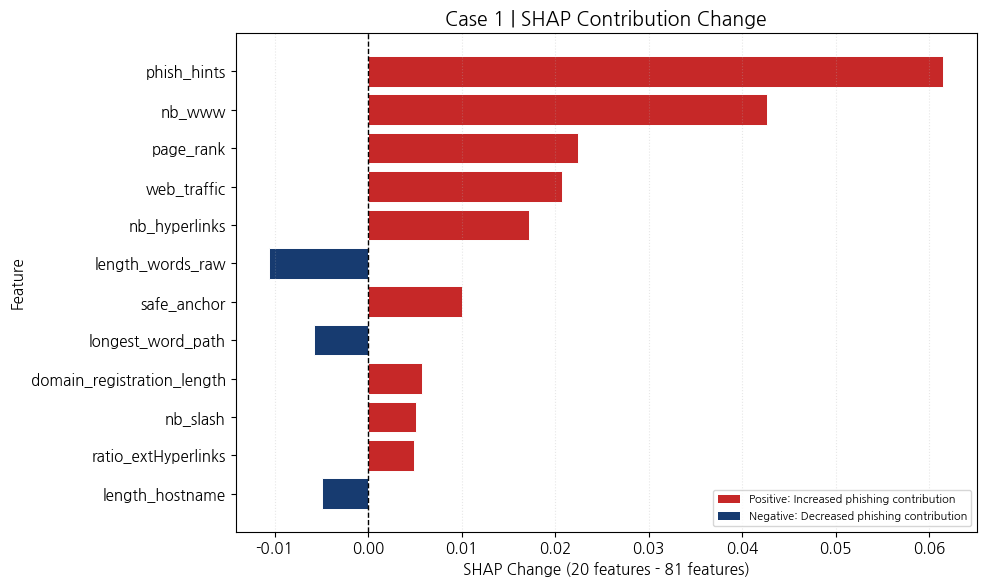

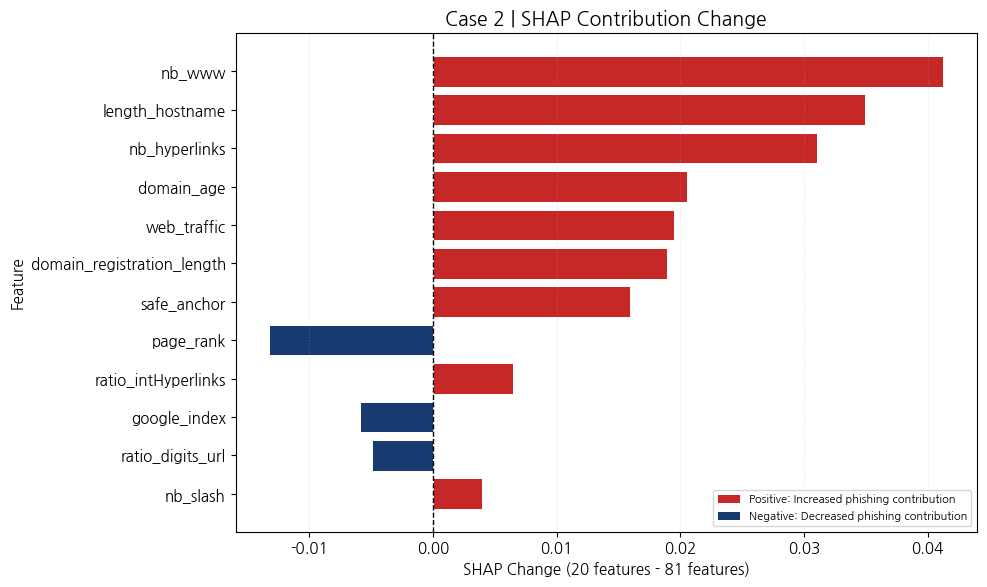

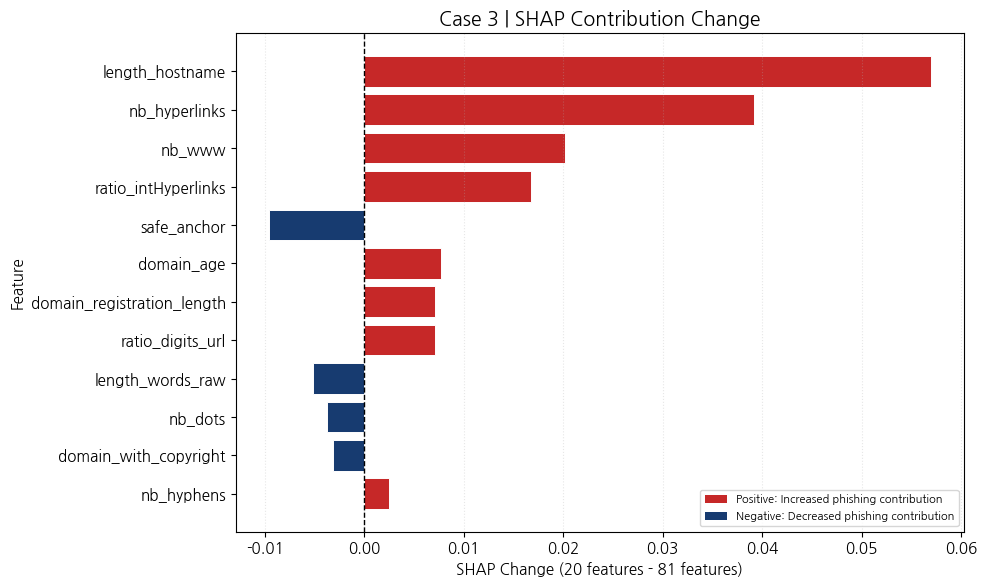

In [61]:

from matplotlib.patches import Patch

for idx in ids:
    case_result = shap_pivot[
        shap_pivot['original_index'] == idx
    ].copy()

    # 절대 변화량이 큰 상위 12개 특성 선택
    case_result = case_result.sort_values(
        'SHAP 변화량',
        key=lambda x: x.abs(),
        ascending=True
    ).tail(12)

    # 양수와 음수에 서로 다른 색상 적용
    colors = [
    '#C62828' if value > 0 else '#173B70'
    for value in case_result['SHAP 변화량']
    ]

    plt.figure(figsize=(10, 6))

    plt.barh(
        case_result['feature'],
        case_result['SHAP 변화량'],
        color=colors,
        edgecolor='white',
        linewidth=0.7
    )

    # 변화량 0 기준선
    plt.axvline(
        0,
        color='black',
        linestyle='--',
        linewidth=1
    )

    # 범례
    legend_elements = [
        Patch(facecolor='#C62828',
              label='Positive: Increased phishing contribution'),
        Patch(facecolor='#173B70',
              label='Negative: Decreased phishing contribution')
        ]

    plt.legend(
        handles=legend_elements,
        loc='best',
        fontsize=8
    )

    plt.xlabel(
        'SHAP Change (20 features - 81 features)'
    )
    plt.ylabel('Feature')

    plt.title(
        f'Case {ids.index(idx) + 1} | SHAP Contribution Change'
    )

    plt.grid(
        axis='x',
        linestyle=':',
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()



### 10-3. 세 사례에 공통적으로 나타나는 특성 변화

마지막으로 사례별 차이를 특성 단위로 모아 **평균 변화량, 평균 절대 변화량, 증가·감소한 사례 수**를 비교합니다. 원본 노트북의 최종 분석 단계입니다.

아래 코드는 세 사례의 결과를 합쳐서 어떤 특성들이 반복적으로 비슷한 방향으로 변화했는지

분석한 지표

- **Mean Delta**	세 사례의 SHAP 변화량 평균
- **Mean Abs Delta**	변화량 절댓값의 평균
- **Positive Cases**	양의 변화량을 보인 사례 수
- **Negative Cases**	음의 변화량을 보인 사례 수


Mean Delta는 변화 방향을 보여줌.



Mean Abs Delta는 방향과 상관없이 변화의 크기를 보여줌.



Positive/Negative Cases는 세 사례 중 몇 개에서 해당 방향의 변화가 나타났는지를 보여줌.


세 사례를 종합했을 때 nb_www, nb_hyperlinks, web_traffic, domain_registration_length, domain_age, ratio_intHyperlinks, nb_slash 특성은 세 사례 모두에서 피싱 방향으로 SHAP 기여도가 변화함.


특히 nb_www와 nb_hyperlinks는 세 사례 모두에서 양의 변화량을 보였고, 평균 변화량도 상대적으로 컸음.


반면 phish_hints, page_rank, length_hostname, safe_anchor 특성은 사례마다 변화 방향이 달랐음.


이를 통해 특성 축소 이후 모델의 예측 기여 구조가 변화했으며, 그 변화에는 세 사례에서 공통으로 나타나는 경향과 개별 사례에 따라 달라지는 경향이 모두 존재한다고 해석할 수 있음.

In [62]:

# 세 사례의 특성별 SHAP 변화량 평균
common_change = (
    shap_pivot
    .groupby('feature')['SHAP 변화량']
    .agg(
        평균_변화량='mean',
        평균_절대변화량=lambda x: x.abs().mean(),
        양의_변화_사례수=lambda x: (x > 0).sum(),
        음의_변화_사례수=lambda x: (x < 0).sum()
    )
    .reset_index()
)

common_change = common_change.sort_values(
    '평균_절대변화량',
    ascending=False
)

display(common_change.head(20).round(4))


,feature,평균_변화량,평균_절대변화량,양의_변화_사례수,음의_변화_사례수
11,nb_www,0.0347,0.0347,3,0
4,length_hostname,0.0290,0.0323,2,1
8,nb_hyperlinks,0.0292,0.0292,3,0
13,phish_hints,0.0188,0.0222,1,2
19,web_traffic,0.0136,0.0136,3,0
12,page_rank,0.0030,0.0120,1,2
18,safe_anchor,0.0055,0.0119,2,1
1,domain_registration_length,0.0106,0.0106,3,0
0,domain_age,0.0104,0.0104,3,0
17,ratio_intHyperlinks,0.0091,0.0091,3,0
